# A03 — Data Wrangling: limpieza y EDA del dataset perturbado *Room Occupancy Estimation*

**Tecnológico de Monterrey** · Maestría en Inteligencia Artificial Aplicada
**Curso:** TC5044 Operaciones de aprendizaje automático (MLOps)
**Actividad:** A03 — Actividad individual *Data Wrangling* (Parte A)
**Autor:** Jhonatan Marín Salazar · **Matrícula:** A01797351
**Fecha:** 9 de octubre de 2026

---

## Objetivo

En este notebook limpio el archivo `room-occupancy-estimation/modified.csv`, una copia deliberadamente corrompida del
dataset *Room Occupancy Estimation* del repositorio UCI (`original.csv`), y realizo el análisis exploratorio (EDA) del
resultado. Al final demuestro, con las mismas pruebas que el ejemplo `1.4_WineQuality_DataCleaning.ipynb`, qué tanto se
parece cada versión limpia al dataset original.

El dataset registra, cada ~30 segundos, las lecturas de siete nodos de sensores instalados en una sala de 6 m × 4.6 m:
temperatura, luz, sonido, CO₂ y sensores de movimiento PIR. La variable objetivo es `Room_Occupancy_Count`, el número de
personas presentes en la sala (0 a 3).

## Regla de juego

En un proyecto real no existe un "original" contra el cual compararse: la verdad limpia se desconoce. Por eso adopto la
misma regla del ejemplo:

- Todas mis decisiones de limpieza se basan **solo** en pruebas ejecutadas sobre `modified.csv` y en conocimiento del
  dominio, que dejo escrito como un **contrato de datos** antes de mirar la referencia.
- El archivo `original.csv` lo cargo **únicamente al final**: primero para auditar la limpieza celda por celda
  (Sección 7) y luego como línea base del EDA comparativo (Sección 8).

## Qué cambia frente al ejemplo del vino

A diferencia del dataset de vinos, este es una **serie de tiempo de sensores**. Esa naturaleza me permite aplicar técnicas
adicionales que en el ejemplo no tenían sentido:

1. Usar la marca de tiempo (`Date` + `Time`) como **llave natural** para detectar duplicados que el ruido disfraza y
   **fusionar** (coalescer) la información de las copias.
2. **Reconstruir** marcas de tiempo faltantes a partir de las lecturas vecinas.
3. Detectar valores corruptos que caen *dentro* del rango físico mediante un **filtro de Hampel** (picos aislados frente a
   la mediana móvil) en las variables de dinámica lenta.
4. Comparar cuatro estrategias de imputación: **A** eliminar filas, **B** mediana, **C** interpolación temporal y
   **D** KNN multivariado.

## Estructura del notebook

| Parte | Contenido |
|---|---|
| 1. Configuración | Librerías, rutas y contrato de datos |
| 2. Carga segura | Lectura de todo como texto para que nada se convierta en silencio |
| 3. Pruebas diagnósticas | Una prueba por problema de calidad; cada una define la acción de limpieza |
| 4. Pipeline de limpieza | Una función pura por paso, con bitácora de limpieza |
| 5. Estrategias de imputación | A: eliminar · B: mediana · C: interpolación temporal · D: KNN |
| 6. Validación posterior | Aserciones de que el contrato de datos se cumple |
| 7. Auditoría contra el original | Detección celda por celda y error de imputación (posible solo por ser un ejercicio sintético) |
| 8. EDA comparativo | Original vs. A, B, C y D |
| 9. EDA del dataset limpio | Análisis exploratorio completo y temporal de la versión seleccionada |
| 10. Conclusiones | Hallazgos, estrategia recomendada y lecciones de MLOps |

# 1. Configuración

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

sns.set(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

# Rutas relativas: este notebook vive al lado de la carpeta `room-occupancy-estimation/`
DATA_DIR = Path("room-occupancy-estimation")
MODIFIED_PATH = DATA_DIR / "modified.csv"
ORIGINAL_PATH = DATA_DIR / "original.csv"          # se usa SOLO en las secciones 7 y 8
BASELINE_PATH = DATA_DIR / "original_no_duplicates.csv"   # línea base, generada en la Sección 8

# Salidas: una versión limpia por estrategia
CLEAN_PATHS = {
    "A": DATA_DIR / "cleaned_A_dropna.csv",
    "B": DATA_DIR / "cleaned_B_median.csv",
    "C": DATA_DIR / "cleaned_C_interpolated.csv",
    "D": DATA_DIR / "cleaned_D_knn.csv",
}

## 1.1 Contrato de datos

El contrato de datos es el acuerdo escrito de cómo se ven los datos válidos. Herramientas como **pandera** o
**Great Expectations** lo formalizan; aquí lo dejo como diccionarios de Python para que cada regla sea visible y auditable.

Los límites provienen de la física de cada sensor y de la documentación del dataset en UCI. Los defino de forma
deliberadamente **generosa**: buscan atrapar valores imposibles, no valores inusuales.

| Variable | Rango válido | Justificación |
|---|---|---|
| `S1–S4_Temp` | 10 – 40 °C | Temperatura interior de una sala ocupada; fuera de ese rango no hay condiciones de oficina |
| `S1–S4_Light` | 0 – 1000 lux, entero | La iluminación de oficina típica está entre 300 y 500 lux; el sensor reporta enteros |
| `S1–S4_Sound` | 0 – 5 V | Salida analógica del amplificador del micrófono leída por un ADC de 5 V |
| `S5_CO2` | 250 – 5000 ppm | El aire exterior ronda 400 ppm; 5000 ppm es el límite de exposición ocupacional |
| `S5_CO2_Slope` | −50 – 50 | Pendiente del CO₂ en una ventana deslizante; ningún cambio físico de CO₂ en la sala la lleva a ese orden |
| `S6_PIR`, `S7_PIR` | {0, 1} | Sensores de movimiento digitales (binarios) |
| `Room_Occupancy_Count` | {0, 1, 2, 3} | El experimento se diseñó con entre 0 y 3 ocupantes (variable objetivo) |
| `Date` + `Time` | Fecha-hora válida, única | Cada lectura corresponde a un instante; dos filas con la misma marca de tiempo son la misma lectura |

In [2]:
# Contrato de datos: columna -> (mínimo, máximo) inclusivo
DATA_CONTRACT = {
    "S1_Temp": (10.0, 40.0), "S2_Temp": (10.0, 40.0), "S3_Temp": (10.0, 40.0), "S4_Temp": (10.0, 40.0),   # °C
    "S1_Light": (0, 1000), "S2_Light": (0, 1000), "S3_Light": (0, 1000), "S4_Light": (0, 1000),           # lux
    "S1_Sound": (0.0, 5.0), "S2_Sound": (0.0, 5.0), "S3_Sound": (0.0, 5.0), "S4_Sound": (0.0, 5.0),       # V
    "S5_CO2": (250, 5000),                                                                                 # ppm
    "S5_CO2_Slope": (-50.0, 50.0),
    "S6_PIR": (0, 1), "S7_PIR": (0, 1),                                                                     # binarios
    "Room_Occupancy_Count": (0, 3),                                                                         # objetivo
}

TIME_COLUMNS = ["Date", "Time"]
TARGET = "Room_Occupancy_Count"
FEATURES = [c for c in DATA_CONTRACT if c != TARGET]
EXPECTED_COLUMNS = TIME_COLUMNS + list(DATA_CONTRACT)

# Variables que por definición solo toman valores enteros o binarios
INTEGER_COLUMNS = ["S1_Light", "S2_Light", "S3_Light", "S4_Light", "S6_PIR", "S7_PIR", TARGET]
BINARY_COLUMNS = ["S6_PIR", "S7_PIR"]

# Grupos de sensores (útiles para el EDA)
SENSOR_GROUPS = {
    "Temperatura": ["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"],
    "Luz": ["S1_Light", "S2_Light", "S3_Light", "S4_Light"],
    "Sonido": ["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"],
    "CO2": ["S5_CO2", "S5_CO2_Slope"],
    "PIR": ["S6_PIR", "S7_PIR"],
}
CONTINUOUS_FEATURES = [c for c in FEATURES if c not in BINARY_COLUMNS]

# 2. Carga segura de los datos crudos

**¿Por qué leo todo como texto (`dtype=str`)?** Si dejo que pandas infiera los tipos, un solo token como `"?"` convierte
toda una columna numérica en `object`, o peor, una lista de `na_values` podría ocultar en silencio los problemas que
precisamente quiero **ver**. Leer como texto me da control total: primero inspecciono y después convierto de forma
explícita. Es el principio de MLOps *"nunca confíes en la entrada, valídala"*.

Con `keep_default_na=False` garantizo que incluso cadenas como `"NaN"` o `"NULL"` lleguen como texto literal para que mis
pruebas las cuenten.

In [3]:
raw_df = pd.read_csv(MODIFIED_PATH, dtype=str, keep_default_na=False)
raw_df.index.name = "row_id"      # conservo la posición original de cada fila para la trazabilidad

print(f"Filas: {raw_df.shape[0]:,}   Columnas: {raw_df.shape[1]}")
raw_df.head()

Filas: 10,331   Columnas: 20


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
row_id,,,,,,,,,,,,,,,,,,,,
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad


In [4]:
# Metadatos publicados con la perturbación (solo como referencia: en la vida real casi nunca existen)
metadata = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
print("Forma original:", metadata["shape_original"], "| Forma modificada:", metadata["shape_modified"])
metadata["rates"]

Forma original: [10129, 19] | Forma modificada: [10331, 20]


{'dup_rate': 0.02,
 'nan_rate': 0.01,
 'outlier_rate': 0.01,
 'bad_token_rate': 0.005,
 'obj_noise_rate': 0.05,
 'add_mixed_type': True}

Los metadatos anticipan los tipos de defectos inyectados: duplicados (2 %), faltantes (1 %), valores atípicos (1 %),
tokens inválidos (0.5 %), ruido de formato (5 %) y una columna de tipo mixto. No los uso para decidir; mis pruebas deben
encontrarlos por sí mismas.

# 3. Pruebas diagnósticas

Antes de modificar cualquier dato, **mido**. Cada prueba responde una pregunta y se traduce en una acción de limpieza:

| # | Prueba | Si falla → acción |
|---|---|---|
| T1 | Esquema: ¿las columnas coinciden con el contrato? | Eliminar columnas inesperadas / detener si falta alguna requerida |
| T2 | Tipos: ¿cada valor se puede convertir a número? | Normalizar y convertir tipos de forma explícita |
| T3 | Espacios: ¿hay valores con espacios al inicio o al final? | Eliminar espacios |
| T4 | Tokens: ¿qué cadenas no numéricas existen? | Mapear los marcadores (`?`, `NULL`, `bad`…) a faltante |
| T5 | Faltantes: ¿cuántas celdas vacías hay por columna? | Decidir entre eliminar o imputar |
| T6 | Marca de tiempo: ¿`Date` + `Time` forman una fecha-hora válida y ordenada? | Reconstruir lo recuperable, eliminar lo que no se pueda ubicar |
| T7 | Rango de dominio: ¿valores fuera de los límites físicos? | Marcarlos como inválidos (faltante) |
| T8 | Dominio discreto: ¿enteros y binarios donde corresponde? Resolución del CO₂ | Marcarlos como inválidos |
| T9 | Picos temporales: ¿valores dentro del rango pero aislados en el tiempo? | Filtro de Hampel en variables de dinámica lenta |
| T10 | Objetivo: ¿`Room_Occupancy_Count` es un entero entre 0 y 3? | Eliminar filas con objetivo inválido (una etiqueta nunca se imputa) |
| T11 | Duplicados: exactos y por marca de tiempo | Fusionar copias por marca de tiempo |
| T12 | Consistencia entre columnas: movimiento ⇒ presencia; coherencia espacial de la temperatura | Invalidar lo incoherente, o conservar y documentar si la incoherencia es plausible |

### T1 — Prueba de esquema
**Qué verifica:** el conjunto de columnas del archivo frente al contrato.
**Por qué importa:** una columna extra puede introducir ruido (o incluso filtrar el objetivo) en un modelo; una columna
faltante rompe el pipeline.

In [5]:
extra_cols = [c for c in raw_df.columns if c not in EXPECTED_COLUMNS]
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_df.columns]

print("Columnas inesperadas:", extra_cols)
print("Columnas faltantes:  ", missing_cols)

Columnas inesperadas: ['mixed_type_col']
Columnas faltantes:   []


In [6]:
# Inspecciono la columna inesperada antes de decidir qué hacer con ella
for col in extra_cols:
    s = raw_df[col]
    as_num = pd.to_numeric(s.str.strip(), errors="coerce")
    target_num = pd.to_numeric(raw_df[TARGET].str.strip(), errors="coerce")
    print(f"--- {col} ---")
    print(f"Valores distintos: {s.nunique():,}")
    print(f"Proporción convertible a número: {as_num.notna().mean():.1%}")
    print("Valores más frecuentes:")
    print(s.replace("", "<vacío>").value_counts().head(6).to_string())
    print(f"Correlación de Spearman con {TARGET} (parte numérica): {as_num.corr(target_num, method='spearman'):.3f}")

--- mixed_type_col ---
Valores distintos: 1,002
Proporción convertible a número: 69.2%
Valores más frecuentes:
mixed_type_col
bad        1068
unknown    1056
<vacío>    1054
786          16
957          16
194          15
Correlación de Spearman con Room_Occupancy_Count (parte numérica): 0.003


**Resultado → acción.** `mixed_type_col` no está en el contrato, mezcla enteros con texto (`bad`, `unknown`) y celdas
vacías, y no tiene relación con la ocupación. Es una **columna de ruido de tipo mixto** → **la elimino**.

### T2 — Prueba de tipos
**Qué verifica:** la proporción de valores de cada columna numérica que se pueden convertir a número *tal como están*.
**Por qué importa:** todas las variables del contrato son numéricas; lo que no se convierte es ruido de formato o un
problema real.

In [7]:
def parse_rate(series):
    return pd.to_numeric(series, errors="coerce").notna().mean()

numeric_cols = list(DATA_CONTRACT)
type_test = pd.DataFrame({
    "convertible_tal_cual": raw_df[numeric_cols].apply(parse_rate),
    "convertible_tras_strip": raw_df[numeric_cols].apply(lambda s: parse_rate(s.str.strip())),
})
type_test.style.format("{:.2%}")

,convertible_tal_cual,convertible_tras_strip
S1_Temp,98.48%,98.48%
S2_Temp,98.42%,98.42%
S3_Temp,98.44%,98.44%
S4_Temp,98.53%,98.53%
S1_Light,98.57%,98.57%
S2_Light,98.43%,98.43%
S3_Light,98.30%,98.30%
S4_Light,98.61%,98.61%
S1_Sound,98.59%,98.59%
S2_Sound,98.49%,98.49%


**Resultado → acción.** Ninguna columna es 100 % convertible y todas mejoran al quitar espacios, así que una parte del
problema es de formato (T3). El resto son tokens no numéricos o celdas vacías (T4, T5). La conversión numérica debe ir
**después** de esas correcciones.

### T3 — Prueba de espacios en blanco
**Qué verifica:** valores cuyo texto difiere de su versión sin espacios (por ejemplo `" 24.56 "`).
**Por qué importa:** `" 24.56 "` y `"24.56"` son la misma medición pero cadenas distintas: rompen la conversión, las
agrupaciones y la detección de duplicados.

In [8]:
check_cols = [c for c in raw_df.columns if c in EXPECTED_COLUMNS]
whitespace_counts = raw_df[check_cols].apply(lambda s: (s != s.str.strip()).sum())
print(f"Celdas con espacios al inicio/final: {whitespace_counts.sum():,} "
      f"({whitespace_counts.sum() / raw_df[check_cols].size:.1%} del total)")
whitespace_counts.to_frame("celdas_con_espacios").T

Celdas con espacios al inicio/final: 9,766 (5.0% del total)


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
celdas_con_espacios,499,532,529,499,543,501,502,529,552,479,526,533,499,509,509,540,530,473,482


**Resultado → acción.** Cerca del 5 % de las celdas, incluidas `Date` y `Time`, tienen espacios → **los elimino en todas
las columnas**.

### T4 — Prueba de tokens marcadores
**Qué verifica:** después de quitar espacios, qué cadenas no vacías siguen sin poder convertirse a número.
**Por qué importa:** los sistemas de origen suelen escribir marcadores (`?`, `N/A`, `NULL`, `error`…) en lugar de dejar
la celda vacía. Los listo de forma explícita en lugar de adivinarlos, para que un token *nuevo* se note la próxima vez.

In [9]:
stripped = raw_df[check_cols].apply(lambda s: s.str.strip())
not_numeric = stripped[numeric_cols].apply(
    lambda s: s[(s != "") & pd.to_numeric(s, errors="coerce").isna()]
)

token_counts = (
    pd.Series(not_numeric.stack().values)
    .value_counts()
    .rename_axis("token").to_frame("conteo")
)
token_counts.T

token,?,error,invalid,NULL,N/A,NAN,n/a,ERROR,INVALID,null
conteo,187,179,169,158,152,79,8,8,7,6


In [10]:
# Tokens en las columnas de fecha y hora (no numéricas por naturaleza)
for col in TIME_COLUMNS:
    s = stripped[col]
    pattern = r"^\d{4}/\d{2}/\d{2}$" if col == "Date" else r"^\d{2}:\d{2}:\d{2}$"
    odd = s[~s.str.match(pattern)]
    print(f"{col}: valores fuera del formato esperado -> {odd.replace('', '<vacío>').value_counts().to_dict()}")

# Los marcadores se comparan sin distinguir mayúsculas
PLACEHOLDER_TOKENS = {t.lower() for t in token_counts.index} | {"nan"}
print("\nTokens que trataré como faltantes:", sorted(PLACEHOLDER_TOKENS))

Date: valores fuera del formato esperado -> {'<vacío>': 90, 'NAN': 3}
Time: valores fuera del formato esperado -> {'<vacío>': 101, 'NAN': 5}

Tokens que trataré como faltantes: ['?', 'error', 'invalid', 'n/a', 'nan', 'null']


**Resultado → acción.** Existe un conjunto pequeño y bien definido de marcadores con variaciones de mayúsculas
(`NULL`/`null`, `ERROR`/`error`, `N/A`/`n/a`) → **los mapeo a faltante (NaN)** y luego convierto a número.

### T5 — Prueba de faltantes
**Qué verifica:** celdas vacías por columna, *antes* y *después* de convertir los marcadores.
**Por qué importa:** la cantidad y el patrón de los faltantes deciden si eliminar filas es asequible o si se necesita
imputar.

In [11]:
empty_cells = (stripped == "").sum()
is_missing = stripped.apply(lambda s: s.str.lower().isin(PLACEHOLDER_TOKENS) | (s == ""))

missing_test = pd.DataFrame({
    "celdas_vacias": empty_cells,
    "faltantes_incl_marcadores": is_missing.sum(),
    "pct_faltante": is_missing.mean() * 100,
})
print(f"Filas con al menos un faltante: {is_missing.any(axis=1).sum():,} "
      f"({is_missing.any(axis=1).mean():.1%})")
missing_test.round(2).T

Filas con al menos un faltante: 2,455 (23.8%)


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
celdas_vacias,90.0,101.00,99.00,113.00,100.00,94.00,96.00,103.00,108.0,100.00,90.00,90.00,88.00,83.00,107.00,91.00,86.00,100.00,110.00
faltantes_incl_marcadores,93.0,106.00,157.00,163.00,161.00,152.00,148.00,162.00,176.0,144.00,146.00,156.00,138.00,127.00,159.00,153.00,138.00,159.00,172.00
pct_faltante,0.9,1.03,1.52,1.58,1.56,1.47,1.43,1.57,1.7,1.39,1.41,1.51,1.34,1.23,1.54,1.48,1.34,1.54,1.66


**Resultado → acción.** Entre 1 % y 2 % por columna, repartido en filas distintas. Individualmente es poco, pero en
conjunto toca a cerca de una cuarta parte de las filas. Por eso compararé varias estrategias de imputación (Sección 5).

### T6 — Prueba de marca de tiempo
**Qué verifica:** que `Date` + `Time` formen una fecha-hora válida, que el archivo esté ordenado cronológicamente y que el
intervalo entre lecturas sea el esperado (~30 s).
**Por qué importa:** en una serie de tiempo, una lectura sin marca de tiempo no se puede ubicar, interpolar ni comparar
con sus vecinas. El orden del archivo, además, me dice si las filas sospechosas fueron agregadas al final.

In [12]:
timestamp_raw = pd.to_datetime(
    stripped["Date"] + " " + stripped["Time"], format="%Y/%m/%d %H:%M:%S", errors="coerce"
)

print(f"Marcas de tiempo inválidas o incompletas: {timestamp_raw.isna().sum():,}")
print(f"Rango temporal: {timestamp_raw.min()}  ->  {timestamp_raw.max()}")
print("\nLecturas válidas por día:")
print(timestamp_raw.dt.date.value_counts().sort_index().to_string())

Marcas de tiempo inválidas o incompletas: 197
Rango temporal: 2017-12-22 10:49:41  ->  2018-01-11 09:00:09

Lecturas válidas por día:
2017-12-22    1457
2017-12-23    2771
2017-12-24    1069
2017-12-25    1729
2017-12-26    1073
2018-01-10     996
2018-01-11    1039


In [13]:
# ¿El archivo está ordenado cronológicamente? Busco el primer punto donde el tiempo "retrocede"
valid_ts = timestamp_raw.dropna()
backwards = valid_ts.diff().dt.total_seconds() < 0
first_break = backwards.idxmax() if backwards.any() else None

print(f"Saltos hacia atrás en el tiempo: {backwards.sum():,}")
print(f"Primer salto hacia atrás en la fila: {first_break}")
print(f"Filas antes de ese punto que están en orden cronológico: "
      f"{valid_ts.loc[:first_break - 1].is_monotonic_increasing}")

body_gaps = valid_ts.loc[:first_break - 1].diff().dt.total_seconds()
print("\nIntervalo entre lecturas consecutivas (segundos), cuerpo del archivo:")
print(body_gaps.value_counts().head(5).to_string())

Saltos hacia atrás en el tiempo: 102
Primer salto hacia atrás en la fila: 10130
Filas antes de ese punto que están en orden cronológico: True

Intervalo entre lecturas consecutivas (segundos), cuerpo del archivo:
31.0    6123
30.0    3486
61.0     253
62.0      60
92.0       7


**Resultado → acción.**

- El archivo está en orden cronológico estricto hasta una fila cercana a la 10,129; a partir de ahí las marcas de tiempo
  saltan al azar. Ese bloque final es la firma de **filas agregadas** (posibles duplicados) que analizo en T11.
- El intervalo típico entre lecturas es de 30–31 s, de modo que una marca de tiempo faltante en el cuerpo del archivo se
  puede **reconstruir** a partir de sus vecinas inmediatas (punto medio), con un error de ±1 s que es irrelevante para el
  análisis. Solo lo hago cuando la fila anterior y la siguiente tienen marca válida, son del mismo día y están separadas
  por no más de 2 minutos; el resto de filas sin marca se eliminan, porque no se pueden ubicar en la serie.

### T7 — Prueba de rango de dominio
**Qué verifica:** valores convertidos que están fuera de los límites del contrato.
**Por qué importa:** valores como `CO₂ = 309,120 ppm` o una temperatura de `3,084 °C` son físicamente imposibles. Son
**errores**, no atípicos, y unos pocos bastan para destruir medias, desviaciones y correlaciones.

> **Error vs. atípico.** La regla IQR marca valores *estadísticamente inusuales*, y muchos de ellos son reales (la luz y
> el sonido tienen colas largas cuando la sala está ocupada). Una regla de dominio marca valores *imposibles*. Solo los
> segundos se deben eliminar de forma automática.

In [14]:
numeric_raw = stripped[numeric_cols].apply(
    lambda s: pd.to_numeric(s.where(~s.str.lower().isin(PLACEHOLDER_TOKENS)), errors="coerce")
)

range_rows = []
for col, (lo, hi) in DATA_CONTRACT.items():
    s = numeric_raw[col]
    bad = (s < lo) | (s > hi)
    range_rows.append({
        "variable": col, "min_contrato": lo, "max_contrato": hi,
        "min_observado": s.min(), "max_observado": s.max(),
        "n_fuera_de_rango": int(bad.sum()),
        "ejemplos": s[bad].head(3).round(2).tolist(),
    })
range_test = pd.DataFrame(range_rows).set_index("variable")
print(f"Celdas fuera de rango: {range_test['n_fuera_de_rango'].sum():,}")
range_test

Celdas fuera de rango: 994


,min_contrato,max_contrato,min_observado,max_observado,n_fuera_de_rango,ejemplos
variable,,,,,,
S1_Temp,10.0,40.0,24.940000,3084.910000,110,"[352.66, 259.38, 2106.0]"
S2_Temp,10.0,40.0,24.750000,2546.720000,109,"[345.75, 274.34, 2472.0]"
S3_Temp,10.0,40.0,24.440000,2413.740000,107,"[546.13, 437.13, 1459.36]"
S4_Temp,10.0,40.0,24.940000,2553.880000,93,"[1533.6, 337.94, 2467.5]"
S1_Light,0.0,1000.0,0.000000,14308.000000,11,"[10248.0, 10332.0, 1131.0]"
S2_Light,0.0,1000.0,0.000000,12168.000000,14,"[3312.0, 6100.0, 1101.0]"
S3_Light,0.0,1000.0,0.000000,26208.000000,11,"[26208.0, 17262.0, 12600.0]"
S4_Light,0.0,1000.0,0.000000,5041.000000,16,"[3933.0, 5041.0, 1840.0]"
S1_Sound,0.0,5.0,0.060000,993.070000,83,"[21.35, 870.47, 496.04]"


In [15]:
# ¿Por qué no usar simplemente la regla IQR? Comparo cuántas celdas marcaría cada regla.
iqr_flags = {}
for col in FEATURES:
    s = numeric_raw[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_flags[col] = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "regla_dominio": range_test.loc[FEATURES, "n_fuera_de_rango"],
    "regla_IQR_1.5": pd.Series(iqr_flags),
}).T

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR
regla_dominio,110,109,107,93,11,14,11,16,83,54,64,70,44,64,54,47
regla_IQR_1.5,110,860,107,93,1792,1096,1000,613,1889,1795,1762,818,1620,4089,969,852


**Resultado → acción.** Todas las variables tienen valores imposibles, muchas veces 10 a 1000 veces la escala normal →
**los convierto en faltantes**. La regla IQR marcaría miles de celdas en luz, sonido, PIR y CO₂ porque la sala pasa la
mayor parte del tiempo vacía y las lecturas de ocupación quedan en la cola: son valores reales, no errores. La conservo
solo como **diagnóstico**, igual que en el ejemplo.

### T8 — Prueba de dominio discreto y resolución del sensor
**Qué verifica:**
1. Que las variables enteras (luz, PIR, ocupación) no tengan decimales y que los PIR sean estrictamente 0 o 1.
2. La **resolución** del sensor de CO₂: si casi todas las lecturas caen en una rejilla fija (por ejemplo, múltiplos de
   5 ppm), un valor fuera de esa rejilla no lo pudo haber producido el sensor.

**Por qué importa:** son reglas que atrapan corrupción que pasa la prueba de rango.

In [16]:
in_range = numeric_raw.copy()
for col, (lo, hi) in DATA_CONTRACT.items():
    in_range.loc[(in_range[col] < lo) | (in_range[col] > hi), col] = np.nan

non_integer = {col: int((in_range[col].dropna() % 1 != 0).sum()) for col in INTEGER_COLUMNS}
print("Valores no enteros en variables enteras:", non_integer)

for col in BINARY_COLUMNS:
    print(f"{col}: valores distintos dentro de rango -> {sorted(in_range[col].dropna().unique())}")

# Resolución del CO2: ¿qué proporción de lecturas válidas es múltiplo de 5 ppm?
co2 = in_range["S5_CO2"].dropna()
on_grid = (co2 % 5 == 0)
print(f"\nCO2 en rejilla de 5 ppm: {on_grid.mean():.2%}  |  fuera de rejilla: {(~on_grid).sum()} lecturas")
print("Ejemplos fuera de rejilla:", co2[~on_grid].head(8).tolist())

Valores no enteros en variables enteras: {'S1_Light': 0, 'S2_Light': 0, 'S3_Light': 0, 'S4_Light': 0, 'S6_PIR': 0, 'S7_PIR': 0, 'Room_Occupancy_Count': 0}
S6_PIR: valores distintos dentro de rango -> [np.float64(0.0), np.float64(1.0)]
S7_PIR: valores distintos dentro de rango -> [np.float64(0.0), np.float64(1.0)]

CO2 en rejilla de 5 ppm: 99.63%  |  fuera de rejilla: 37 lecturas
Ejemplos fuera de rejilla: [924.0, 1162.0, 1413.0, 552.0, 519.0, 769.0, 1349.0, 886.0]


**Resultado → acción.** No hay decimales espurios en las variables enteras, pero el CO₂ muestra una resolución clara:
más del 99.5 % de las lecturas son múltiplos de 5 ppm. Las pocas lecturas fuera de esa rejilla (por ejemplo 924 o
1,413 ppm) son incompatibles con la resolución del sensor → **las marco como inválidas**.

### T9 — Prueba de picos temporales (filtro de Hampel)
**Qué verifica:** valores que están *dentro* del rango físico pero que se separan bruscamente de sus vecinos en el tiempo y
regresan de inmediato.

**Por qué importa:** la corrupción no siempre produce valores imposibles. Un valor de luz de 883 lux entre dos lecturas
de 155 lux es físicamente posible, pero no 30 segundos aislado. El filtro de Hampel compara cada valor con la
**mediana móvil** de su vecindario y lo marca si se aleja más de *t* desviaciones robustas (MAD escalada):

$$|x_t - \tilde{x}_t| > \max\left(t \cdot 1.4826 \cdot \text{MAD}_t,\ \delta_{\min}\right)$$

donde $\tilde{x}_t$ es la mediana de la ventana centrada de 5 lecturas (±1 minuto) y $\delta_{\min}$ es un umbral físico
mínimo que evita marcar fluctuaciones pequeñas cuando la señal está muy estable.

**Decisión de dominio (antes de mirar el original):** solo aplico el filtro a variables de **dinámica lenta o escalonada**:

| Variable | ¿Aplica? | Razón |
|---|---|---|
| Temperatura | Sí (δ = 0.5 °C) | La temperatura de una sala no sube y baja medio grado en 30 s |
| Luz | Sí (δ = 50 lux) | La luz cambia por escalones (se prende o apaga y se mantiene), no por picos de una lectura |
| CO₂ | Sí (δ = 50 ppm) | El CO₂ se acumula y se disipa gradualmente |
| Pendiente del CO₂ | Sí (δ = 1.0) | Es una regresión en ventana deslizante: suave por construcción |
| Sonido | **Solo con corroboración** (δ = 0.5 V) | Es impulsivo por naturaleza (una voz, una puerta), así que un pico aislado *por sí solo* no prueba nada. Pero los cuatro micrófonos están en la misma sala de 28 m²: un sonido real llega, aunque sea atenuado, a más de uno. Marco el pico solo si **ningún otro micrófono** se eleva más de 0.1 V sobre su propia mediana en ±30 s |
| PIR | **No** | Es binario; un disparo aislado es el comportamiento normal del sensor |

El filtro requiere la serie ordenada y sin duplicados, por lo que en el pipeline se ejecuta después de fusionar las
copias (T11). Aquí solo mido su alcance sobre las filas en orden cronológico del cuerpo del archivo.

In [17]:
HAMPEL_CONFIG = {   # variable -> umbral físico mínimo
    "S1_Temp": 0.5, "S2_Temp": 0.5, "S3_Temp": 0.5, "S4_Temp": 0.5,
    "S1_Light": 50, "S2_Light": 50, "S3_Light": 50, "S4_Light": 50,
    "S5_CO2": 50, "S5_CO2_Slope": 1.0,
}
HAMPEL_WINDOW = 5      # lecturas (centrada: 2 antes y 2 después)
HAMPEL_T = 3.0         # desviaciones robustas


def hampel_flags(series, groups, window=HAMPEL_WINDOW, t=HAMPEL_T, min_delta=0.0):
    """Devuelve una máscara booleana con los picos aislados de `series`, calculada por grupo (segmento continuo)."""
    roll = lambda x: x.rolling(window, center=True, min_periods=3).median()
    med = series.groupby(groups).transform(roll)
    mad = (series - med).abs().groupby(groups).transform(roll)
    threshold = np.maximum(t * 1.4826 * mad, min_delta)
    return (series - med).abs() > threshold


# Diagnóstico sobre el cuerpo cronológico del archivo (filas antes del primer salto hacia atrás)
body = in_range.loc[:first_break - 1].copy()
body.loc[body["S5_CO2"] % 5 != 0, "S5_CO2"] = np.nan
body_day = stripped.loc[:first_break - 1, "Date"]
hampel_test = pd.Series({col: int(hampel_flags(body[col], body_day, min_delta=d).sum())
                         for col, d in HAMPEL_CONFIG.items()}, name="picos_aislados")
hampel_test.to_frame().T

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S5_CO2,S5_CO2_Slope
picos_aislados,1,1,0,0,67,65,42,67,20,20


In [18]:
SOUND_COLUMNS = ["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]
SOUND_MIN_DELTA = 0.5      # V: un pico de sonido debe superar en 0.5 V la mediana local
SOUND_CORROBORATION = 0.1  # V: elevación mínima de otro micrófono para considerar que "también lo oyó"


def sound_spike_flags(df, groups):
    """Picos de Hampel en sonido que ningún otro micrófono corrobora (en la misma lectura o la adyacente)."""
    roll = lambda x: x.rolling(HAMPEL_WINDOW, center=True, min_periods=3).median()
    sound = df[SOUND_COLUMNS]
    excess = sound - sound.groupby(groups).transform(roll)              # elevación sobre la mediana local
    elevated = (excess > SOUND_CORROBORATION).astype(float)
    elevated_win = elevated.groupby(groups).transform(
        lambda x: x.rolling(3, center=True, min_periods=1).max()).astype(bool)
    flags = pd.DataFrame(False, index=df.index, columns=SOUND_COLUMNS)
    for col in SOUND_COLUMNS:
        others = [o for o in SOUND_COLUMNS if o != col]
        spike = hampel_flags(df[col], groups, min_delta=SOUND_MIN_DELTA)
        flags[col] = spike & ~elevated_win[others].any(axis=1)
    return flags


sound_raw_spikes = pd.Series({c: int(hampel_flags(body[c], body_day, min_delta=SOUND_MIN_DELTA).sum())
                              for c in SOUND_COLUMNS})
sound_uncorroborated = sound_spike_flags(body, body_day).sum()
pd.DataFrame({"picos_hampel": sound_raw_spikes, "picos_sin_corroboracion": sound_uncorroborated}).T

,S1_Sound,S2_Sound,S3_Sound,S4_Sound
picos_hampel,150,110,130,59
picos_sin_corroboracion,51,43,36,27


En el sonido, el filtro de Hampel por sí solo marca más de 100 picos por micrófono, la mayoría con la sala ocupada
(conversaciones). Al exigir que ningún otro micrófono los corrobore, quedan unas pocas decenas: picos que solo "oyó" un
sensor mientras los demás permanecían en silencio, una firma más propia de un artefacto de datos que de un sonido real.

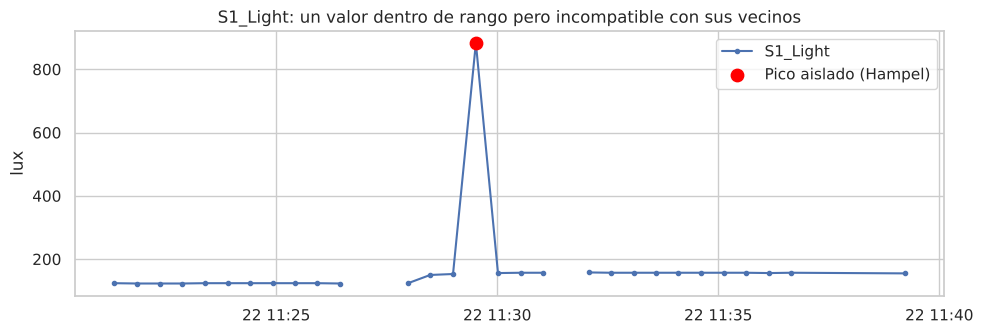

In [19]:
# Ejemplo visual: luz del sensor S1 en una ventana con un pico aislado
col = "S1_Light"
flags_s1 = hampel_flags(body[col], body_day, min_delta=HAMPEL_CONFIG[col])
example_idx = flags_s1[flags_s1].index[0]
window = body.loc[example_idx - 15: example_idx + 15, col]
window_ts = timestamp_raw.loc[window.index]

plt.figure(figsize=(10, 3.5))
plt.plot(window_ts, window.values, marker="o", ms=3, label=col)
plt.scatter(window_ts[window.index == example_idx], window[window.index == example_idx],
            color="red", s=80, zorder=3, label="Pico aislado (Hampel)")
plt.title(f"{col}: un valor dentro de rango pero incompatible con sus vecinos")
plt.ylabel("lux")
plt.legend()
plt.tight_layout()
plt.show()

**Resultado → acción.** El filtro encuentra decenas de picos aislados en luz, CO₂ y su pendiente que la regla de rango no
puede ver → **los marco como inválidos** dentro del pipeline, después de ordenar y fusionar duplicados.

### T10 — Prueba de la variable objetivo
**Qué verifica:** `Room_Occupancy_Count` debe ser un entero entre 0 y 3.
**Por qué importa:** el objetivo es la verdad de referencia de la que aprende el modelo. **Una etiqueta nunca se imputa**:
una etiqueta adivinada es un ejemplo de entrenamiento inventado. Las filas con objetivo inválido se eliminan en todas las
estrategias.

In [20]:
q = numeric_raw[TARGET]
target_test = pd.Series({
    "faltante / no convertible": int(q.isna().sum()),
    "no entero": int((q.dropna() % 1 != 0).sum()),
    "fuera de 0-3": int(((q < 0) | (q > 3)).sum()),
})
print(target_test.to_string())
print("\nEtiquetas válidas presentes:", sorted(q[(q >= 0) & (q <= 3)].dropna().unique()))

faltante / no convertible    172
no entero                      0
fuera de 0-3                  43

Etiquetas válidas presentes: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]


**Resultado → acción.** Las etiquetas vienen como decimales (`1.0`) y algunas faltan o son imposibles → **elimino esas
filas y convierto el objetivo a entero**. Antes de hacerlo, intento recuperarlas desde una copia duplicada (T11).

### T11 — Prueba de duplicados (exactos y por marca de tiempo)
**Qué verifica:** filas exactamente iguales y, más importante, **marcas de tiempo repetidas**.
**Por qué importa:** los duplicados sobreponderan observaciones, sesgan las estadísticas y pueden filtrarse entre los
conjuntos de entrenamiento y prueba. En una serie de tiempo de sensores la marca de tiempo es una **llave natural**: dos
filas con el mismo instante describen la misma lectura, aunque el ruido haga que sus textos no coincidan.

In [21]:
ts_key = timestamp_raw.dropna()
ts_dups = ts_key.duplicated(keep=False)
dup_groups = ts_key[ts_dups]

pd.Series({
    "duplicados exactos en el archivo crudo": int(raw_df.duplicated().sum()),
    "... ignorando la columna de ruido": int(raw_df[check_cols].duplicated().sum()),
    "... después de quitar espacios y convertir": int(pd.concat([stripped[TIME_COLUMNS], numeric_raw], axis=1).duplicated().sum()),
    "marcas de tiempo repetidas (filas sobrantes)": int(ts_key.duplicated().sum()),
    "filas del bloque final cuya marca ya existe antes": int(ts_key.loc[first_break:].isin(ts_key.loc[:first_break - 1]).sum()),
}).to_frame("n_filas")

,n_filas
duplicados exactos en el archivo crudo,1
... ignorando la columna de ruido,16
... después de quitar espacios y convertir,87
marcas de tiempo repetidas (filas sobrantes),189
filas del bloque final cuya marca ya existe antes,189


In [22]:
# ¿Las copias son idénticas? Comparo, para cada marca repetida, cuántas variables tienen valores válidos distintos
comparison_rows = []
for ts, idx in dup_groups.groupby(dup_groups).groups.items():
    block = in_range.loc[idx]
    n_conflicts = int((block.nunique(dropna=True) > 1).sum())
    n_fillable = int((block.isna().any() & block.notna().any()).sum())
    comparison_rows.append({"timestamp": ts, "filas": len(idx), "variables_en_conflicto": n_conflicts,
                            "faltantes_recuperables": n_fillable})
dup_comparison = pd.DataFrame(comparison_rows)

print(f"Marcas de tiempo repetidas: {len(dup_comparison):,}")
print(f"Grupos con al menos un faltante que la copia puede completar: {(dup_comparison['faltantes_recuperables'] > 0).sum()}")
print(f"Grupos con valores válidos en conflicto: {(dup_comparison['variables_en_conflicto'] > 0).sum()}")
dup_comparison.sort_values("variables_en_conflicto", ascending=False).head()

Marcas de tiempo repetidas: 189
Grupos con al menos un faltante que la copia puede completar: 96
Grupos con valores válidos en conflicto: 12


,timestamp,filas,variables_en_conflicto,faltantes_recuperables
155,2017-12-26 09:04:24,2,2,1
3,2017-12-22 14:17:29,2,1,0
6,2017-12-22 16:21:03,2,1,0
12,2017-12-22 18:57:17,2,1,0
2,2017-12-22 13:57:04,2,1,2


**Resultado → acción.**

- Solo hay 1 duplicado exacto en el archivo crudo, pero casi 200 marcas de tiempo repetidas: **el ruido de formato y la
  corrupción disfrazan los duplicados**. Una deduplicación por igualdad exacta (la del ejemplo del vino) dejaría pasar la
  gran mayoría.
- Las copias casi siempre coinciden en sus valores válidos, y en muchos casos una copia tiene el dato que a la otra le
  falta. Por eso, en lugar de solo descartar la copia, **fusiono (coalesco) cada grupo**: conservo el primer valor válido
  de cada variable, priorizando la fila que aparece primero en el archivo (cuerpo cronológico).
- Los pocos conflictos los resuelvo con la misma prioridad, y el filtro de Hampel (T9) revisa después el valor resultante.

### T12 — Prueba de consistencia entre columnas
**Qué verifica:** dos reglas que relacionan varias columnas en el mismo instante:
1. **Movimiento implica presencia:** si alguno de los PIR detecta movimiento (`= 1`), la ocupación debería ser mayor que 0.
2. **Coherencia espacial de la temperatura:** los cuatro sensores están en la misma sala de 28 m²; ninguno debería
   alejarse más de 5 °C de la mediana de los cuatro en el mismo instante.

**Por qué importa:** las reglas de una sola columna no ven un valor que es plausible por sí mismo pero incoherente con otra
columna (el equivalente al *SO₂ libre ≤ SO₂ total* del ejemplo del vino).

In [23]:
# Regla 1: PIR activo con la sala vacía
pir_any = (in_range["S6_PIR"] == 1) | (in_range["S7_PIR"] == 1)
pir_violation = pir_any & (in_range[TARGET] == 0)

# ¿Son lecturas aisladas (firma típica de corrupción) o rachas consecutivas (comportamiento del sensor)?
viol_idx = pd.Series(pir_violation[pir_violation].index)
run_lengths = viol_idx.groupby((viol_idx.diff() != 1).cumsum()).size()

n_empty = int((in_range[TARGET] == 0).sum())
print(f"Lecturas con PIR = 1 y ocupación = 0: {int(pir_violation.sum())} "
      f"({pir_violation.sum() / n_empty:.2%} de las lecturas con la sala vacía)")
print(f"Rachas: {len(run_lengths)} | lecturas en rachas de 2 o más: {int(run_lengths[run_lengths > 1].sum())} "
      f"| racha más larga: {run_lengths.max()} lecturas")

# Regla 2: coherencia espacial de la temperatura
temps = in_range[SENSOR_GROUPS["Temperatura"]]
temp_dev = temps.sub(temps.median(axis=1), axis=0).abs()
pd.DataFrame({
    "desviacion_max_vs_mediana_C": temp_dev.max().round(2),
    "lecturas_mayores_a_5C": (temp_dev > 5).sum(),
}).T

Lecturas con PIR = 1 y ocupación = 0: 23 (0.28% de las lecturas con la sala vacía)
Rachas: 13 | lecturas en rachas de 2 o más: 16 | racha más larga: 4 lecturas


,S1_Temp,S2_Temp,S3_Temp,S4_Temp
desviacion_max_vs_mediana_C,0.53,3.07,1.22,0.81
lecturas_mayores_a_5C,0.00,0.00,0.00,0.00


**Resultado → acción.**

- **Movimiento ⇒ presencia:** hay 23 lecturas (0.28 % de las de sala vacía) con un PIR activo y
  ocupación 0. Sus valores son 0/1 válidos (la corrupción de los PIR ya la atrapó T7 porque produce valores como 915) y la
  mayoría (16 de 23) aparecen en **rachas consecutivas** de hasta 4 lecturas, no aisladas. Ese patrón corresponde al comportamiento real del sensor:
  falsos disparos por corrientes de aire o el desfase entre el momento en que alguien sale y el registro de la etiqueta.
  → **Las conservo y lo documento.** No invalido los PIR (perdería señal real) ni modifico la etiqueta (nunca se imputa).
- **Coherencia de la temperatura:** ningún sensor se aleja más de 5 °C de la mediana de los cuatro (el máximo, cercano a
  3 °C en S2, coincide con los periodos de ocupación). → **La regla se cumple, no requiere acción**, pero la incorporo como
  aserción en la validación final (Sección 6) para que una versión futura del dataset que la viole detenga el pipeline.

# 4. Pipeline de limpieza

Cada prueba se traduce en una **función pura** (DataFrame de entrada → DataFrame nuevo, sin estado oculto). Así escribo
código de limpieza con criterio de MLOps: cada paso se puede probar por separado, el orden es explícito y el mismo
pipeline se puede volver a ejecutar sobre los datos del próximo mes o llevar a un job de producción sin cambios.

Además llevo una **bitácora de limpieza** que registra cuántas celdas y filas tocó cada paso. En producción esa bitácora
se guardaría junto con la versión del dataset (por ejemplo, con DVC o MLflow) para garantizar trazabilidad. También
conservo `row_id`, la posición de cada fila en `modified.csv`, para poder auditar el resultado.

In [24]:
cleaning_log = []
FLAGS = {}      # celdas marcadas como inválidas por cada regla (para la auditoría de la Sección 7)


def log_step(step, detail, rows_before, rows_after, cells_changed=None):
    cleaning_log.append({
        "paso": step, "detalle": detail,
        "filas_antes": rows_before, "filas_despues": rows_after,
        "celdas_modificadas": cells_changed,
    })


def enforce_schema(df):
    # Paso 1 (T1): conservar solo las columnas del contrato, en su orden
    dropped = [c for c in df.columns if c not in EXPECTED_COLUMNS]
    missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")   # fallar ruidosamente, nunca adivinar
    log_step("enforce_schema", f"eliminadas {dropped}", len(df), len(df))
    return df[EXPECTED_COLUMNS].copy()


def strip_whitespace(df):
    # Paso 2 (T3): quitar espacios al inicio y al final de cada celda
    out = df.apply(lambda s: s.str.strip())
    log_step("strip_whitespace", "str.strip() en todas las columnas", len(df), len(out),
             int((out != df).sum().sum()))
    return out


def placeholders_to_nan(df, tokens):
    # Paso 3 (T4/T5): marcadores conocidos y cadenas vacías -> NaN
    is_placeholder = df.apply(lambda s: s.str.lower().isin(tokens) | (s == ""))
    out = df.mask(is_placeholder)
    log_step("placeholders_to_nan", f"{len(tokens)} tokens + cadenas vacías", len(df), len(out),
             int(is_placeholder.sum().sum()))
    return out


def parse_timestamp(df):
    # Paso 4 (T6): Date + Time -> timestamp; lo que no se pueda interpretar queda NaT
    out = df.copy()
    out["timestamp"] = pd.to_datetime(out["Date"] + " " + out["Time"], format="%Y/%m/%d %H:%M:%S", errors="coerce")
    out = out.drop(columns=TIME_COLUMNS)
    log_step("parse_timestamp", "Date + Time -> datetime (inválido -> NaT)", len(df), len(out),
             int(out["timestamp"].isna().sum()))
    return out


def cast_numeric(df):
    # Paso 5 (T2): conversión explícita; lo que no se pueda convertir queda NaN y se cuenta
    out = df.copy()
    for col in DATA_CONTRACT:
        out[col] = pd.to_numeric(df[col], errors="coerce")
    newly_nan = int((out[list(DATA_CONTRACT)].isna() & df[list(DATA_CONTRACT)].notna()).sum().sum())
    log_step("cast_numeric", "a float64 (no convertible -> NaN)", len(df), len(out), newly_nan)
    return out

In [25]:
def invalidate_out_of_range(df, contract):
    # Paso 6 (T7): valores imposibles son errores -> NaN (después se decide eliminar o imputar)
    out = df.copy()
    n = 0
    for col, (lo, hi) in contract.items():
        bad = (out[col] < lo) | (out[col] > hi)
        FLAGS.setdefault("rango", []).extend((i, col) for i in out.index[bad])
        n += int(bad.sum())
        out.loc[bad, col] = np.nan
    log_step("invalidate_out_of_range", "fuera de los límites del contrato -> NaN", len(df), len(out), n)
    return out


def invalidate_discrete_domain(df):
    # Paso 7 (T8): enteros con decimales, binarios distintos de 0/1 y CO2 fuera de la rejilla de 5 ppm -> NaN
    out = df.copy()
    n = 0
    for col in INTEGER_COLUMNS:
        bad = out[col].notna() & (out[col] % 1 != 0)
        n += int(bad.sum())
        out.loc[bad, col] = np.nan
    bad_co2 = out["S5_CO2"].notna() & (out["S5_CO2"] % 5 != 0)
    FLAGS.setdefault("resolucion_co2", []).extend((i, "S5_CO2") for i in out.index[bad_co2])
    n += int(bad_co2.sum())
    out.loc[bad_co2, "S5_CO2"] = np.nan
    log_step("invalidate_discrete_domain", "enteros/binarios inválidos y CO2 fuera de rejilla -> NaN",
             len(df), len(out), n)
    return out


def reconstruct_timestamp(df, max_gap_s=120):
    # Paso 8 (T6): una marca faltante entre dos vecinas válidas, del mismo día y a <= 2 min -> punto medio
    out = df.copy()
    prev_ts, next_ts = out["timestamp"].shift(1), out["timestamp"].shift(-1)
    gap = (next_ts - prev_ts).dt.total_seconds()
    can_fix = (out["timestamp"].isna() & prev_ts.notna() & next_ts.notna()
               & (prev_ts.dt.date == next_ts.dt.date) & (gap > 0) & (gap <= max_gap_s))
    estimate = pd.Series((prev_ts + (next_ts - prev_ts) / 2).dt.round("s").values, index=out.index)

    # Si en otra parte del archivo existe una marca REAL entre las dos vecinas, es la de la copia de esta misma
    # lectura (dos filas consecutivas no dejan espacio para otra lectura distinta): uso la marca real.
    known = np.sort(out["timestamp"].dropna().unique())
    pos = np.searchsorted(known, prev_ts[can_fix].values, side="right")
    pos = np.minimum(pos, len(known) - 1)
    candidate = pd.Series(known[pos], index=prev_ts[can_fix].index)
    twin = (candidate > prev_ts[can_fix]) & (candidate < next_ts[can_fix])
    estimate.loc[twin[twin].index] = candidate[twin]

    out.loc[can_fix, "timestamp"] = estimate[can_fix]
    out["timestamp_reconstruido"] = can_fix
    log_step("reconstruct_timestamp", f"punto medio entre vecinas válidas ({int(twin.sum())} con la marca de su copia)",
             len(df), len(out), int(can_fix.sum()))
    return out


def drop_missing_timestamp(df):
    # Paso 9 (T6): una lectura sin marca de tiempo no se puede ubicar en la serie
    out = df[df["timestamp"].notna()].copy()
    log_step("drop_missing_timestamp", "filas sin marca de tiempo recuperable", len(df), len(out))
    return out


def coalesce_duplicates(df):
    # Paso 10 (T11): fusionar filas con la misma marca de tiempo; primer valor válido de cada variable,
    # priorizando el orden del archivo. Se conserva el row_id de la primera aparición.
    ordered = df.reset_index().sort_values(["timestamp", "row_id"], kind="stable")
    keep_first = ordered.drop_duplicates("timestamp", keep="first")              # deduplicación simple, como referencia
    out = ordered.groupby("timestamp", as_index=False, sort=True).first()       # first() toma el primer valor no nulo
    out = out.set_index("row_id")
    recovered = int(keep_first[list(DATA_CONTRACT)].isna().sum().sum() - out[list(DATA_CONTRACT)].isna().sum().sum())
    log_step("coalesce_duplicates", "fusión por marca de tiempo; celdas = faltantes recuperados de la copia",
             len(df), len(out), recovered)
    return out


def add_segments(df, max_gap_s=300):
    # Paso 11: ordenar y numerar tramos continuos (un salto > 5 min abre un nuevo segmento)
    out = df.sort_values("timestamp").copy()
    gap = out["timestamp"].diff().dt.total_seconds()
    out["segment"] = (gap.isna() | (gap > max_gap_s)).cumsum()
    log_step("add_segments", f"{out['segment'].nunique()} segmentos continuos", len(df), len(out))
    return out


def invalidate_spikes(df, config):
    # Paso 12 (T9): filtro de Hampel por segmento en variables de dinámica lenta -> NaN
    out = df.copy()
    n = 0
    for col, min_delta in config.items():
        bad = hampel_flags(out[col], out["segment"], min_delta=min_delta)
        FLAGS.setdefault("hampel", []).extend((i, col) for i in out.index[bad])
        n += int(bad.sum())
        out.loc[bad, col] = np.nan
    sound_bad = sound_spike_flags(out, out["segment"])
    for col in SOUND_COLUMNS:
        FLAGS.setdefault("hampel_sonido", []).extend((i, col) for i in out.index[sound_bad[col]])
        out.loc[sound_bad[col], col] = np.nan
    n += int(sound_bad.sum().sum())
    log_step("invalidate_spikes", "picos aislados (Hampel; sonido sin corroboración) -> NaN", len(df), len(out), n)
    return out


def drop_invalid_target(df):
    # Paso 13 (T10): una etiqueta nunca se imputa; además se fuerza el tipo entero
    valid = df[TARGET].notna() & (df[TARGET] % 1 == 0)
    out = df[valid].copy()
    out[TARGET] = out[TARGET].astype(int)
    log_step("drop_invalid_target", "filas con objetivo faltante/inválido eliminadas", len(df), len(out))
    return out

### Pasos 1 a 13: comunes a todas las estrategias

In [26]:
cleaning_log.clear()   # permite re-ejecutar la celda sin duplicar la bitácora
FLAGS.clear()

base_df = (
    raw_df
    .pipe(enforce_schema)
    .pipe(strip_whitespace)
    .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS)
    .pipe(parse_timestamp)
    .pipe(cast_numeric)
    .pipe(invalidate_out_of_range, DATA_CONTRACT)
    .pipe(invalidate_discrete_domain)
    .pipe(reconstruct_timestamp)
    .pipe(drop_missing_timestamp)
    .pipe(coalesce_duplicates)
    .pipe(add_segments)
    .pipe(invalidate_spikes, HAMPEL_CONFIG)
    .pipe(drop_invalid_target)
)

n_rows_with_nan = base_df[FEATURES].isna().any(axis=1).sum()
print(f"Filas después de los pasos comunes: {len(base_df):,}")
print(f"Filas con al menos una variable faltante: {n_rows_with_nan:,} ({n_rows_with_nan / len(base_df):.1%})")
print(f"Marcas de tiempo únicas: {base_df['timestamp'].is_unique}")
base_df[FEATURES].isna().sum().to_frame("celdas_faltantes").T

Filas después de los pasos comunes: 9,914
Filas con al menos una variable faltante: 3,025 (30.5%)
Marcas de tiempo únicas: True


,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR
celdas_faltantes,255,253,250,232,213,230,214,210,264,241,225,208,240,223,181,192


# 5. Cuatro estrategias para los faltantes restantes

En este punto todos los problemas se redujeron a uno solo y bien entendido: **valores faltantes en las variables
predictoras**. Comparo cuatro formas de tratarlos:

| | **A — Eliminar filas** | **B — Mediana** | **C — Interpolación temporal** | **D — KNN** |
|---|---|---|---|---|
| Idea | Conservar solo filas completas | Reemplazar por la mediana de la columna | Interpolar en el tiempo dentro de cada segmento continuo | Promediar las 5 lecturas más parecidas en las demás variables |
| A favor | Todos los valores son mediciones reales | Simple, conserva filas | Respeta la dinámica de la serie; usa la lectura de 30 s antes y después | Usa la correlación entre sensores (p. ej. las 4 temperaturas) |
| En contra | Pierde toda fila con *cualquier* celda mala | Crea picos artificiales en la mediana, reduce la dispersión y debilita correlaciones | Puede suavizar un cambio brusco real si coincide con un faltante | Depende del escalamiento y de *k*; más costosa |
| Válida cuando | Faltantes al azar (MCAR) y quedan suficientes filas | Pocos faltantes y el modelo necesita todas las filas | Datos ordenados en el tiempo con muestreo regular | Variables con dependencia multivariada fuerte |

Después de imputar redondeo cada variable a la resolución de su sensor: PIR a {0, 1}, luz a enteros, CO₂ a la rejilla de
5 ppm, temperatura y sonido a dos decimales. Así la salida sigue cumpliendo el contrato.

**Duplicados en cada estrategia.** La deduplicación ocurre dos veces en las cuatro estrategias: la fusión por marca de
tiempo (paso 10, común a todas) y un `drop_duplicates` final por estrategia (paso 15), cuyo resultado confirma un `assert`
en la Sección 6.

> **Nota de MLOps sobre fuga de información.** En un pipeline de modelado, la mediana o el `KNNImputer` se deben
> *ajustar solo con el conjunto de entrenamiento* (dentro de un `sklearn.pipeline.Pipeline`) y luego aplicarse al de prueba.
> Además, la interpolación temporal usa la lectura *siguiente*, algo que no existe en inferencia en tiempo real. Aquí
> imputo el dataset completo porque el objetivo es la limpieza para EDA, no la evaluación de un modelo. Tampoco uso el
> objetivo como variable de entrada del KNN, para no contaminar las predictoras con la etiqueta.

In [27]:
def snap_to_domain(df):
    # Redondea las variables discretas al dominio del contrato después de imputar
    out = df.copy()
    for col in BINARY_COLUMNS:
        out[col] = out[col].round().clip(0, 1)
    for col in SENSOR_GROUPS["Luz"]:
        out[col] = out[col].round()
    out["S5_CO2"] = (out["S5_CO2"] / 5).round() * 5
    for col in SENSOR_GROUPS["Temperatura"] + SENSOR_GROUPS["Sonido"]:
        out[col] = out[col].round(2)                      # resolución con que reportan los sensores
    return out


def strategy_a_drop_rows(df):
    # Paso 14A: eliminación por lista (listwise deletion)
    out = df.dropna(subset=FEATURES).copy()
    log_step("A: drop_incomplete_rows", "filas con cualquier faltante eliminadas", len(df), len(out))
    return out


def strategy_b_impute_median(df):
    # Paso 14B: imputación por la mediana (robusta frente a las colas largas de luz y sonido)
    out = df.copy()
    n = int(out[FEATURES].isna().sum().sum())
    out[FEATURES] = out[FEATURES].fillna(out[FEATURES].median())
    log_step("B: impute_median", "faltantes <- mediana de la columna", len(df), len(out), n)
    return snap_to_domain(out)


def strategy_c_interpolate_time(df):
    # Paso 14C: interpolación lineal en el tiempo dentro de cada segmento; bordes con el valor más cercano
    out = df.copy()
    n = int(out[FEATURES].isna().sum().sum())

    def _interp(group):
        g = group.set_index("timestamp")[FEATURES]
        g = g.interpolate(method="time", limit_direction="both")
        return g.reset_index(drop=True).set_axis(group.index)

    parts = [_interp(group) for _, group in out.groupby("segment", sort=False)]
    out[FEATURES] = pd.concat(parts).loc[out.index]
    out[FEATURES] = out[FEATURES].fillna(out[FEATURES].median())   # salvaguarda: segmentos sin ningún valor válido
    log_step("C: interpolate_time", "interpolación temporal por segmento", len(df), len(out), n)
    return snap_to_domain(out)


def strategy_d_impute_knn(df, k=5):
    # Paso 14D: KNN multivariado sobre variables estandarizadas (sin usar el objetivo)
    out = df.copy()
    n = int(out[FEATURES].isna().sum().sum())
    scaler = StandardScaler()
    scaled = scaler.fit_transform(out[FEATURES])                 # StandardScaler ignora los NaN al ajustar
    imputed = KNNImputer(n_neighbors=k, weights="distance").fit_transform(scaled)
    imputed = pd.DataFrame(scaler.inverse_transform(imputed), index=out.index, columns=FEATURES)
    out[FEATURES] = out[FEATURES].fillna(imputed)      # solo reemplazo celdas faltantes; las medidas no se tocan
    log_step("D: impute_knn", f"KNNImputer(k={k}, weights='distance') estandarizado", len(df), len(out), n)
    return snap_to_domain(out)


def finalize(df, name):
    # Paso 15: columnas finales en orden del contrato + marca de tiempo; deduplicación final de cada estrategia
    cols = ["timestamp"] + list(DATA_CONTRACT)
    out = df[cols].drop_duplicates().copy()
    log_step(f"{name}: drop_duplicates", "duplicados exactos tras imputar (la fusión por marca ya ocurrió en el paso 10)",
             len(df), len(out))
    for col in INTEGER_COLUMNS:
        out[col] = out[col].astype(int)
    out["S5_CO2"] = out["S5_CO2"].astype(int)
    return out


clean = {
    "A": finalize(strategy_a_drop_rows(base_df), "A"),
    "B": finalize(strategy_b_impute_median(base_df), "B"),
    "C": finalize(strategy_c_interpolate_time(base_df), "C"),
    "D": finalize(strategy_d_impute_knn(base_df), "D"),
}
for name, d in clean.items():
    print(f"Estrategia {name}: {len(d):,} filas")

Estrategia A: 6,889 filas
Estrategia B: 9,914 filas
Estrategia C: 9,914 filas
Estrategia D: 9,914 filas


In [28]:
# La bitácora documenta lo que hizo cada paso
pd.DataFrame(cleaning_log)

,paso,detalle,filas_antes,filas_despues,celdas_modificadas
0,enforce_schema,eliminadas ['mixed_type_col'],10331,10331,NaN
1,strip_whitespace,str.strip() en todas las columnas,10331,10331,9766.0
2,placeholders_to_nan,6 tokens + cadenas vacías,10331,10331,2810.0
3,parse_timestamp,Date + Time -> datetime (inválido -> NaT),10331,10331,197.0
4,cast_numeric,a float64 (no convertible -> NaN),10331,10331,0.0
5,invalidate_out_of_range,fuera de los límites del contrato -> NaN,10331,10331,994.0
6,invalidate_discrete_domain,enteros/binarios inválidos y CO2 fuera de reji...,10331,10331,37.0
7,reconstruct_timestamp,punto medio entre vecinas válidas (7 con la ma...,10331,10331,184.0
8,drop_missing_timestamp,filas sin marca de tiempo recuperable,10331,10318,NaN
9,coalesce_duplicates,fusión por marca de tiempo; celdas = faltantes...,10318,10122,75.0


# 6. Validación posterior a la limpieza

La limpieza no termina hasta **probar** que la salida cumple el contrato. Estas aserciones correrían automáticamente en
un pipeline de CI o como compuerta antes del entrenamiento: si una falla, el pipeline se detiene.

In [29]:
def validate(df, name):
    assert list(df.columns) == ["timestamp"] + list(DATA_CONTRACT), "conjunto y orden de columnas"
    assert df.notna().all().all(), "sin faltantes"
    assert df["timestamp"].is_unique, "marca de tiempo única"
    assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES), "predictoras numéricas"
    assert pd.api.types.is_integer_dtype(df[TARGET]), "objetivo entero"
    for col, (lo, hi) in DATA_CONTRACT.items():
        assert df[col].between(lo, hi).all(), f"{col} dentro de los límites del contrato"
    for col in BINARY_COLUMNS:
        assert df[col].isin([0, 1]).all(), f"{col} binario"
    assert (df["S5_CO2"] % 5 == 0).all(), "CO2 en la rejilla de 5 ppm"
    t = df[SENSOR_GROUPS["Temperatura"]]
    assert (t.sub(t.median(axis=1), axis=0).abs() <= 5).all().all(), "coherencia espacial de la temperatura (T12)"
    assert not df.duplicated().any(), "sin filas duplicadas"
    print(f"Estrategia {name}: las {len(df):,} filas cumplen el contrato de datos")


for name, d in clean.items():
    validate(d, name)

Estrategia A: las 6,889 filas cumplen el contrato de datos
Estrategia B: las 9,914 filas cumplen el contrato de datos
Estrategia C: las 9,914 filas cumplen el contrato de datos
Estrategia D: las 9,914 filas cumplen el contrato de datos


In [30]:
# Persisto los datasets limpios (artefactos versionados en un proyecto real)
for name, d in clean.items():
    d.to_csv(CLEAN_PATHS[name], index=False)
    print("Guardado:", CLEAN_PATHS[name])

Guardado: room-occupancy-estimation/cleaned_A_dropna.csv


Guardado: room-occupancy-estimation/cleaned_B_median.csv


Guardado: room-occupancy-estimation/cleaned_C_interpolated.csv


Guardado: room-occupancy-estimation/cleaned_D_knn.csv


# 7. Auditoría contra el original (solo posible en un ejercicio sintético)

A partir de aquí cargo `original.csv`. Nada de lo anterior depende de él.

Si el archivo perturbado conservó alineadas las primeras 10,129 filas con el original y agregó las copias al final (lo
que sugirió la prueba T6), puedo verificar celda por celda cuántos valores corruptos detectaron mis pruebas. Primero
compruebo ese supuesto en lugar de confiar en él.

In [31]:
original_df = pd.read_csv(ORIGINAL_PATH)
assert list(original_df.columns) == EXPECTED_COLUMNS
original_df["timestamp"] = pd.to_datetime(original_df["Date"] + " " + original_df["Time"], format="%Y/%m/%d %H:%M:%S")
N = len(original_df)

# Valores del archivo modificado solo con correcciones de formato (sin reglas de dominio)
parsed = numeric_raw.iloc[:N].reset_index(drop=True)
same = np.isclose(parsed.values, original_df[numeric_cols].values, equal_nan=False)
ts_same = (timestamp_raw.iloc[:N].reset_index(drop=True) == original_df["timestamp"])

print(f"Celdas numéricas idénticas al original tras corregir formato: {same.mean():.1%}")
print(f"Marcas de tiempo idénticas: {ts_same.mean():.1%}")
print(f"Duplicados en el original: {original_df.duplicated().sum()}  |  marcas repetidas: {original_df['timestamp'].duplicated().sum()}")

Celdas numéricas idénticas al original tras corregir formato: 97.7%
Marcas de tiempo idénticas: 98.1%
Duplicados en el original: 0  |  marcas repetidas: 0


Más del 97 % de las celdas coincide, lo que confirma la alineación: las celdas que no coinciden son exactamente la
corrupción inyectada. El original no tiene duplicados, así que lo uso directamente como línea base (a diferencia del
ejemplo del vino, aquí no hace falta deduplicarlo).

## 7.1 Detección de celdas corruptas

In [32]:
# Verdad de corrupción por celda: valor faltante/no convertible O distinto del original
corrupted = pd.DataFrame(~same, columns=numeric_cols)

# Celdas que mi pipeline invalidó: marcadores/vacíos + reglas de rango, resolución y Hampel
flagged = parsed.isna()
for rule in ["rango", "resolucion_co2", "hampel", "hampel_sonido"]:
    for i, col in FLAGS.get(rule, []):
        if i < N:
            flagged.loc[i, col] = True

tp = int((flagged & corrupted).sum().sum())
fn = int((~flagged & corrupted).sum().sum())
fp = int((flagged & ~corrupted).sum().sum())
print(f"Celdas corruptas en la parte alineada: {int(corrupted.sum().sum()):,}")
print(f"Detectadas por las pruebas (verdaderos positivos): {tp:,}  -> recall {tp / (tp + fn):.1%}")
print(f"Celdas válidas marcadas por error (falsos positivos): {fp:,}  -> precisión {tp / (tp + fp):.1%}")
print(f"Celdas corruptas no detectadas (falsos negativos): {fn:,}")

Celdas corruptas en la parte alineada: 3,979
Detectadas por las pruebas (verdaderos positivos): 3,964  -> recall 99.6%
Celdas válidas marcadas por error (falsos positivos): 35  -> precisión 99.1%
Celdas corruptas no detectadas (falsos negativos): 15


In [33]:
# Aporte de cada regla y residuo por variable
rule_contrib = {}
for rule in ["rango", "resolucion_co2", "hampel", "hampel_sonido"]:
    m = pd.DataFrame(False, index=parsed.index, columns=numeric_cols)
    for i, col in FLAGS.get(rule, []):
        if i < N:
            m.loc[i, col] = True
    rule_contrib[rule] = (m & corrupted).sum()

detection = pd.DataFrame({
    "corruptas": corrupted.sum(),
    "por_marcador_o_vacio": (parsed.isna() & corrupted).sum(),
    **{f"por_{k}": v for k, v in rule_contrib.items()},
    "no_detectadas": (~flagged & corrupted).sum(),
})
detection.T

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
corruptas,264,268,260,242,221,235,225,222,250,250,233,220,252,232,190,203,212
por_marcador_o_vacio,154,161,156,151,144,160,174,139,141,155,137,123,156,149,137,156,169
por_rango,110,107,104,91,11,14,10,16,82,52,61,67,43,64,53,47,43
por_resolucion_co2,0,0,0,0,0,0,0,0,0,0,0,0,36,0,0,0,0
por_hampel,0,0,0,0,66,60,41,67,0,0,0,0,17,17,0,0,0
por_hampel_sonido,0,0,0,0,0,0,0,0,25,39,32,27,0,0,0,0,0
no_detectadas,0,0,0,0,0,1,0,0,2,4,3,3,0,2,0,0,0


In [34]:
# Validación ex post de la regla de corroboración en el sonido: Hampel simple vs. Hampel + corroboración
in_range_aligned = parsed.where(parsed.ge(pd.Series({c: v[0] for c, v in DATA_CONTRACT.items()}))
                                & parsed.le(pd.Series({c: v[1] for c, v in DATA_CONTRACT.items()})))
plain = pd.DataFrame({c: hampel_flags(in_range_aligned[c], original_df["Date"], min_delta=SOUND_MIN_DELTA)
                      for c in SOUND_COLUMNS})
corroborated = sound_spike_flags(in_range_aligned, original_df["Date"])
in_range_corrupt = corrupted[SOUND_COLUMNS] & in_range_aligned[SOUND_COLUMNS].notna()

pd.DataFrame({
    "corruptas_dentro_de_rango": in_range_corrupt.sum(),
    "hampel_simple_TP": (plain & in_range_corrupt).sum(),
    "hampel_simple_FP": (plain & ~corrupted[SOUND_COLUMNS]).sum(),
    "con_corroboracion_TP": (corroborated & in_range_corrupt).sum(),
    "con_corroboracion_FP": (corroborated & ~corrupted[SOUND_COLUMNS]).sum(),
}).T

,S1_Sound,S2_Sound,S3_Sound,S4_Sound
corruptas_dentro_de_rango,27,43,35,30
hampel_simple_TP,26,41,35,30
hampel_simple_FP,126,69,94,28
con_corroboracion_TP,25,39,32,27
con_corroboracion_FP,26,4,4,0


**Lectura de la auditoría.** De las 3,979 celdas corruptas de la parte alineada, mis pruebas detectan 3,964 (recall de
99.6 %) y solo marcan por error 35 celdas válidas (precisión de 99.1 %). Los marcadores y vacíos explican la mayor parte;
la regla de rango atrapa los valores imposibles; y la resolución del CO₂ junto con el filtro de Hampel recuperan más de
400 celdas que estaban **dentro** del rango físico, que una limpieza basada solo en límites (como la del ejemplo del vino)
habría dejado pasar.

La última tabla valida la regla de corroboración del sonido: el Hampel simple habría capturado casi todas las celdas
corruptas, pero a costa de borrar más de 300 lecturas legítimas (voces, puertas), que son justamente la señal de
ocupación. Con la corroboración entre micrófonos se capturan 123 de 135 y los falsos positivos bajan a 34, concentrados en
S1, el micrófono que con más frecuencia registra sonidos que los demás no alcanzan a percibir.

## 7.2 Recuperación de duplicados y marcas de tiempo

In [35]:
kept_ids = base_df.index
tail_ids = raw_df.index[raw_df.index >= N]
surviving_tail = base_df[kept_ids.isin(tail_ids)]

# ¿A qué lectura del original corresponde cada fila sobreviviente del bloque final? ¿Su gemela también quedó?
ts_to_orig = pd.Series(original_df.index, index=original_df["timestamp"])
twin_ids = ts_to_orig.reindex(surviving_tail["timestamp"]).dropna().astype(int)
twin_also_kept = int(twin_ids.isin(kept_ids).sum())

recon = base_df[base_df["timestamp_reconstruido"]]
recon_body = recon[recon.index < N]
recon_error = (recon_body["timestamp"] - original_df.loc[recon_body.index, "timestamp"]).dt.total_seconds().abs()

pd.Series({
    "filas agregadas al final del archivo": len(tail_ids),
    "... fusionadas con su gemela o eliminadas": len(tail_ids) - len(surviving_tail),
    "... que sobreviven como fila independiente": len(surviving_tail),
    "... cuya gemela del cuerpo también sobrevive (duplicado residual)": twin_also_kept,
    "marcas de tiempo reconstruidas": len(recon),
    "... exactas o con error <= 1 s": int((recon_error <= 1).sum()),
    "error máximo de reconstrucción (s)": recon_error.max(),
}).to_frame("valor")

,valor
filas agregadas al final del archivo,202.0
... fusionadas con su gemela o eliminadas,201.0
... que sobreviven como fila independiente,1.0
... cuya gemela del cuerpo también sobrevive (duplicado residual),0.0
marcas de tiempo reconstruidas,179.0
... exactas o con error <= 1 s,177.0
error máximo de reconstrucción (s),15.0


Todas las filas agregadas, salvo una, se fusionaron con su gemela del cuerpo o se eliminaron por no tener marca de tiempo.
La que sobrevive no es un duplicado residual: su gemela del cuerpo había perdido la fecha y la hora a la vez que su vecina,
así que se eliminó, y la copia del final quedó como la única versión de esa lectura (con su marca real). En cuanto a las
marcas reconstruidas, casi todas son exactas o difieren en un segundo; los dos casos de 15 s ocurren donde el propio
original tenía un intervalo de 61 s entre las vecinas, de modo que el punto medio no coincide con la lectura real.

## 7.3 Error de imputación (B, C y D)

Como conozco el valor verdadero de cada celda que imputé, puedo medir directamente qué tan cerca quedó cada estrategia.
Uso el **error absoluto medio normalizado** (NMAE = MAE / desviación estándar del original), que permite comparar
variables con escalas muy distintas. Un NMAE de 0 es una imputación perfecta; un NMAE cercano a 1 equivale a errar por
una desviación estándar completa.

In [36]:
imputed_mask = base_df[FEATURES].isna()
imputed_mask = imputed_mask[imputed_mask.index < N]          # solo filas alineadas con el original
truth = original_df.loc[imputed_mask.index, FEATURES]
orig_std = original_df[FEATURES].std()

imputation_rows = []
for name in ["B", "C", "D"]:
    est = clean[name][FEATURES].loc[imputed_mask.index]     # el índice row_id se conserva en todo el pipeline
    for col in FEATURES:
        m = imputed_mask[col]
        if m.sum() == 0:
            continue
        err = (est.loc[m, col] - truth.loc[m, col]).abs()
        imputation_rows.append({"estrategia": name, "variable": col, "n_imputadas": int(m.sum()),
                                "NMAE": err.mean() / orig_std[col]})
imputation_error = pd.DataFrame(imputation_rows)

nmae_table = imputation_error.pivot(index="variable", columns="estrategia", values="NMAE").loc[FEATURES]
nmae_table.loc["PROMEDIO"] = nmae_table.mean()
nmae_table.round(3)

estrategia,B,C,D
variable,,,
S1_Temp,0.713,0.031,0.055
S2_Temp,0.539,0.022,0.078
S3_Temp,0.783,0.032,0.061
S4_Temp,0.719,0.062,0.099
S1_Light,0.486,0.002,0.013
S2_Light,0.323,0.019,0.053
S3_Light,0.649,0.004,0.021
S4_Light,0.867,0.007,0.046
S1_Sound,0.639,0.546,0.493


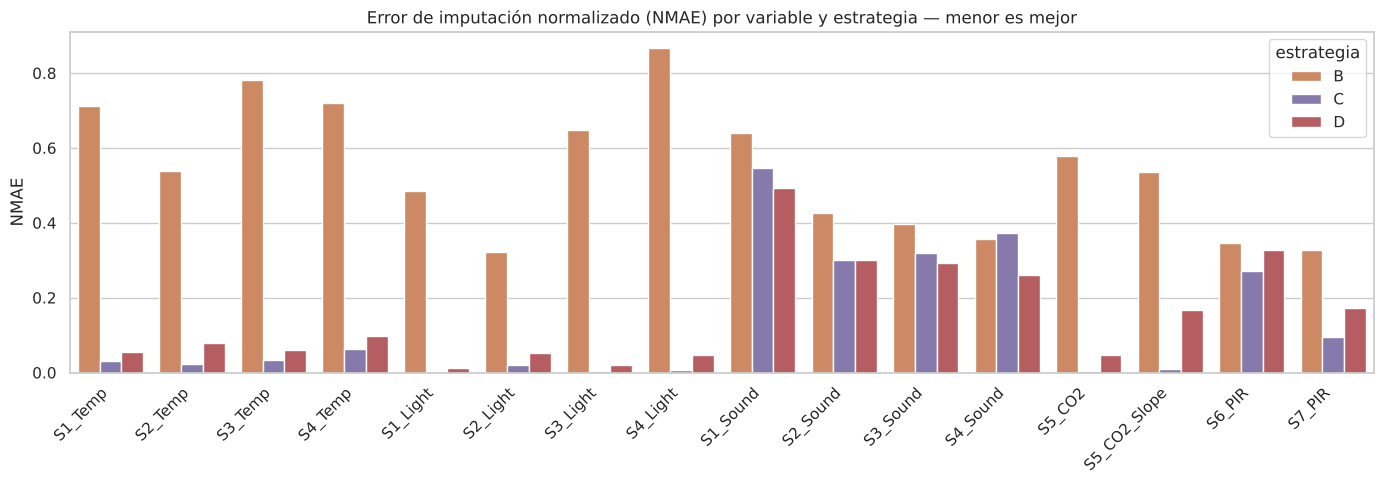

In [37]:
plot_df = imputation_error.copy()
plt.figure(figsize=(14, 5))
sns.barplot(data=plot_df, x="variable", y="NMAE", hue="estrategia",
            palette={"B": "#dd8452", "C": "#8172b3", "D": "#c44e52"})
plt.title("Error de imputación normalizado (NMAE) por variable y estrategia — menor es mejor")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Lectura.** La interpolación temporal (C) es la que más se acerca al valor verdadero: en una serie muestreada cada 30 s
la mejor estimación de una lectura perdida es la lectura de al lado. En temperatura, luz y CO₂ su error es prácticamente
nulo (NMAE < 0.07). El KNN (D) queda muy cerca porque aprovecha la redundancia entre sensores, y es incluso un poco mejor
en el sonido, donde la serie es tan impulsiva que la lectura vecina no anticipa la actual. La mediana (B) es la peor
opción en casi todas las variables, porque imputa siempre el estado de *sala vacía*: su error promedio es cuatro veces
mayor que el de C.

# 8. EDA comparativo contra el original

Repito ahora el EDA del ejemplo (notebook 1.3) sobre cinco datasets en paralelo, siempre contra el original sin duplicados:

| Nombre | Descripción |
|---|---|
| **Original sin duplicados** | Línea base: `original_no_duplicates.csv` (el original no tiene duplicados, pero aplico y verifico la misma regla para que la comparación sea justa) |
| **A — eliminar** | `cleaned_A_dropna.csv` |
| **B — mediana** | `cleaned_B_median.csv` |
| **C — interpolación** | `cleaned_C_interpolated.csv` |
| **D — KNN** | `cleaned_D_knn.csv` |

In [38]:
# Línea base: el original sin duplicados (misma regla aplicada a los datasets limpios)
n_dup_original = int(original_df[EXPECTED_COLUMNS].duplicated().sum())
original_df[EXPECTED_COLUMNS].drop_duplicates().to_csv(BASELINE_PATH, index=False)
print(f"Duplicados en original.csv: {n_dup_original}  ->  línea base guardada en {BASELINE_PATH}")

baseline_df = original_df[["timestamp"] + list(DATA_CONTRACT)].drop_duplicates().copy()
assert not baseline_df.duplicated().any(), "la línea base no debe tener duplicados"
assert baseline_df["timestamp"].is_unique, "la línea base no debe tener marcas de tiempo repetidas"

datasets = {
    "Original sin duplicados": baseline_df,
    "A - eliminar": clean["A"],
    "B - mediana": clean["B"],
    "C - interpolación": clean["C"],
    "D - KNN": clean["D"],
}
REFERENCE = "Original sin duplicados"
CANDIDATES = [k for k in datasets if k != REFERENCE]
PALETTE = dict(zip(datasets, ["#4c72b0", "#55a868", "#dd8452", "#8172b3", "#c44e52"]))
numeric_features = FEATURES


def long_format(cols):
    # Apila todos los datasets en un DataFrame largo con la columna `dataset` (útil para hue en seaborn)
    return pd.concat([d[cols].assign(dataset=name) for name, d in datasets.items()], ignore_index=True)

Duplicados en original.csv: 0  ->  línea base guardada en room-occupancy-estimation/original_no_duplicates.csv


## 8.1 Estructura y calidad

In [39]:
structure = pd.DataFrame({
    name: {
        "filas": len(d),
        "pct_filas_vs_original": 100 * len(d) / len(baseline_df),
        "columnas": d.shape[1],
        "celdas_faltantes": int(d.isna().sum().sum()),
        "filas_duplicadas": int(d.duplicated().sum()),
        "marcas_repetidas": int(d["timestamp"].duplicated().sum()),
    }
    for name, d in datasets.items()
}).T
structure.round(1)

,filas,pct_filas_vs_original,columnas,celdas_faltantes,filas_duplicadas,marcas_repetidas
Original sin duplicados,10129.0,100.0,18.0,0.0,0.0,0.0
A - eliminar,6889.0,68.0,18.0,0.0,0.0,0.0
B - mediana,9914.0,97.9,18.0,0.0,0.0,0.0
C - interpolación,9914.0,97.9,18.0,0.0,0.0,0.0
D - KNN,9914.0,97.9,18.0,0.0,0.0,0.0


Los datasets limpios no tienen faltantes ni duplicados. El número de filas difiere por diseño: A sacrifica filas a cambio
de pureza, mientras B, C y D conservan casi todo el original (la diferencia son las filas con objetivo inválido o sin
marca de tiempo recuperable, que se eliminan en todas las estrategias).

## 8.2 Variable objetivo: `Room_Occupancy_Count`

In [40]:
target_pct = pd.DataFrame({
    name: d[TARGET].value_counts(normalize=True).sort_index() * 100 for name, d in datasets.items()
}).fillna(0)
target_pct.round(2)

,Original sin duplicados,A - eliminar,B - mediana,C - interpolación,D - KNN
Room_Occupancy_Count,,,,,
0,81.23,81.74,81.33,81.33,81.33
1,4.53,4.18,4.47,4.47,4.47
2,7.38,7.36,7.41,7.41,7.41
3,6.85,6.72,6.79,6.79,6.79


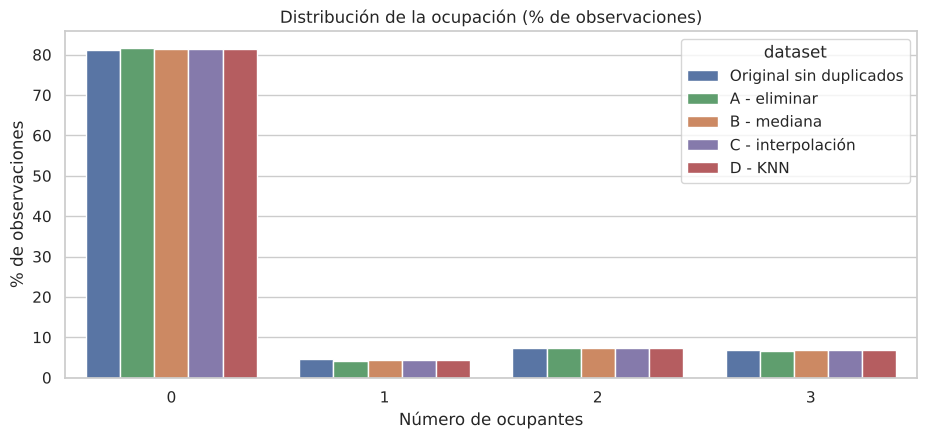

In [41]:
plot_df = target_pct.reset_index(names=TARGET).melt(id_vars=TARGET, var_name="dataset", value_name="porcentaje")
plt.figure(figsize=(11, 4.5))
sns.barplot(data=plot_df, x=TARGET, y="porcentaje", hue="dataset", palette=PALETTE)
plt.title("Distribución de la ocupación (% de observaciones)")
plt.xlabel("Número de ocupantes")
plt.ylabel("% de observaciones")
plt.show()

In [42]:
# Prueba chi-cuadrado de homogeneidad: ¿las proporciones de clase son iguales a las del original?
ref_counts = datasets[REFERENCE][TARGET].value_counts().sort_index()
chi2_results = {}
for name in CANDIDATES:
    counts = datasets[name][TARGET].value_counts().reindex(ref_counts.index, fill_value=0)
    chi2, p, _, _ = stats.chi2_contingency(np.vstack([ref_counts.values, counts.values]))
    chi2_results[name] = p
    print(f"{name:18s} vs {REFERENCE}: chi2 = {chi2:6.2f}, p-value = {p:.3f}")

A - eliminar       vs Original sin duplicados: chi2 =   1.39, p-value = 0.709
B - mediana        vs Original sin duplicados: chi2 =   0.09, p-value = 0.994
C - interpolación  vs Original sin duplicados: chi2 =   0.09, p-value = 0.994
D - KNN            vs Original sin duplicados: chi2 =   0.09, p-value = 0.994


Un p-value mayor a 0.05 significa que **no hay evidencia** de que las proporciones de clase difieran. El fuerte
desbalance del original (más del 80 % de las lecturas con la sala vacía) se conserva en todas las estrategias, porque solo
eliminé filas por posiciones aleatorias, nunca en función de la etiqueta.

## 8.3 Análisis univariado

In [43]:
def univariate_summary(d):
    s = d[numeric_features]
    return pd.DataFrame({
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "min": s.min(), "max": s.max(),
        "skewness": s.skew(), "kurtosis": s.kurt(),
    })


univariate = pd.concat({name: univariate_summary(d) for name, d in datasets.items()}, axis=1)
univariate.xs("mean", axis=1, level=1).round(3)

,Original sin duplicados,A - eliminar,B - mediana,C - interpolación,D - KNN
S1_Temp,25.454,25.450,25.452,25.453,25.453
S2_Temp,25.546,25.539,25.541,25.544,25.544
S3_Temp,25.057,25.052,25.053,25.056,25.056
S4_Temp,25.754,25.748,25.753,25.754,25.754
S1_Light,25.445,24.680,24.812,25.344,25.347
S2_Light,26.016,25.262,25.450,25.970,26.016
S3_Light,34.248,33.423,33.310,34.128,34.119
S4_Light,13.220,12.726,12.833,13.194,13.188
S1_Sound,0.168,0.166,0.163,0.165,0.165
S2_Sound,0.120,0.118,0.118,0.120,0.120


In [44]:
# Diferencia relativa (%) de cada estadístico frente al original
ref_stats = univariate_summary(datasets[REFERENCE])
rel_diff = {}
for name in CANDIDATES:
    s = univariate_summary(datasets[name])
    rel_diff[name] = ((s - ref_stats) / ref_stats.abs() * 100)[["mean", "std", "skewness"]]

pd.concat(rel_diff, axis=1).round(1)

A - eliminar               B - mediana               C - interpolación               D - KNN              
                     mean  std skewness        mean  std skewness              mean  std skewness    mean  std skewness
S1_Temp              -0.0 -0.2      2.9        -0.0 -1.4      3.5              -0.0 -0.2      0.8    -0.0 -0.2      0.8
S2_Temp              -0.0 -1.3      1.3        -0.0 -1.6      2.1              -0.0 -0.5      0.6    -0.0 -0.6      0.2
S3_Temp              -0.0  0.2      3.4        -0.0 -1.3      4.8              -0.0 -0.2      0.7    -0.0 -0.2      0.7
S4_Temp              -0.0 -0.0      9.5        -0.0 -1.1      4.2              -0.0 -0.2      0.5    -0.0 -0.1      0.3
S1_Light             -3.0 -1.3      2.6        -2.5 -0.9      2.3              -0.4 -0.1      0.4    -0.4 -0.1      0.4
S2_Light             -2.9 -1.3      1.9        -2.2 -0.8      1.3              -0.2 -0.1      0.1    -0.0 -0.0     -0.1
S3_Light             -2.4 -0.5      1.0        -2.7 -1.0      1.9              -0.4 -0.2      0.1    -0.4 -0.2      0.1
S4_Light             -3.7 -1.2      4.6        -2.9 -0.8      3.0              -0.2  0.1      0.2    -0.2 -0.0      0.1
S1_Sound             -1.0 -0.5      2.1        -3.2 -4.2      3.2              -2.2 -3.8      1.9    -2.0 -3.7      1.7
S2_Sound             -1.8 -3.2      2.8        -1.9 -2.0      1.9              -0.1 -0.9     -0.3    -0.4 -1.2      0.1
S3_Sound              1.0  2.8     -0.3        -1.9 -1.1      2.0              -0.1  0.0      0.3    -0.3 -0.4      0.4
S4_Sound              0.7  7.9      5.2        -0.1  4.2      7.8               0.8  6.3      4.9     0.7  5.2      5.4
S5_CO2               -0.0  0.4     -0.5        -0.7 -1.2      2.6              -0.1 -0.3      0.4    -0.1 -0.3      0.3
S5_CO2_Slope       -186.4  1.2      5.8       -27.3 -1.1     -1.0             -22.9 -0.0     -2.6    -4.0 -0.1     -2.3
S6_PIR               -1.9 -0.9      1.3        -2.2 -1.0      1.5               0.0  0.0     -0.0     0.2  0.1     -0.1
S7_PIR                2.0  0.9     -1.3        -1.9 -0.9      1.2              -0.1 -0.1      0.1     0.1  0.1     -0.1

**Cómo leerla.** Son diferencias porcentuales frente al original. La columna que más revela es **`std`**: la mediana (B)
tiende a *reducirla*, porque cada valor imputado cae justo en el centro de la distribución. En variables donde la mediana
es 0 (luz, PIR), imputar la mediana equivale a afirmar que la sala estaba vacía y oscura, lo que sesga la media hacia
abajo. La asimetría es el estadístico más sensible, porque depende de pocos valores extremos pero válidos. Las
diferencias relativas grandes en la media de `S5_CO2_Slope` no son preocupantes: su media es prácticamente cero, de modo
que cualquier cambio mínimo se ve enorme en porcentaje (por eso en 8.8 uso la SMD, que se mide en desviaciones estándar).

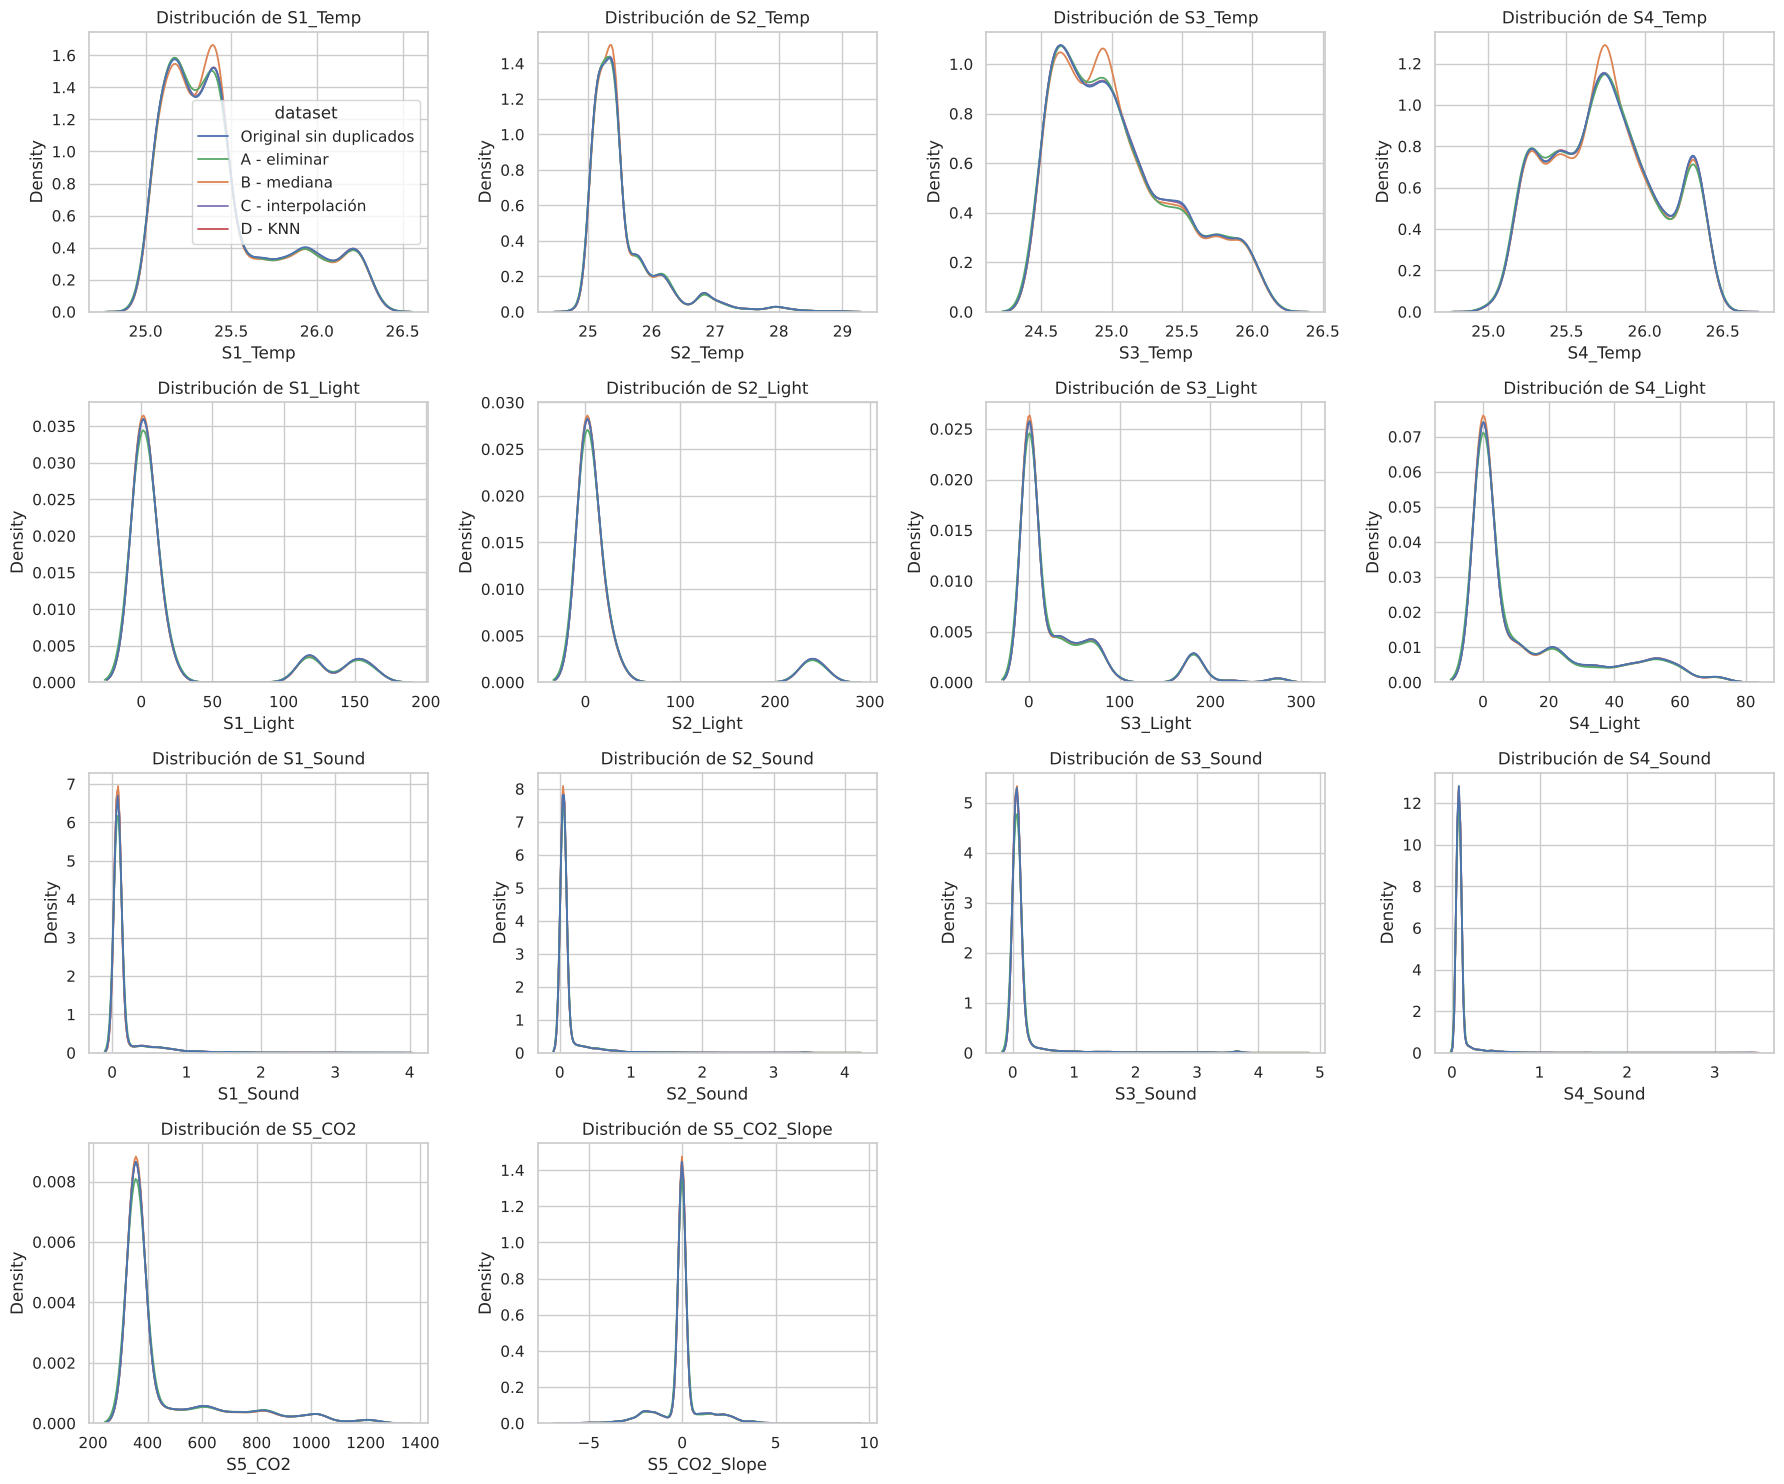

In [45]:
# Distribuciones superpuestas: todas en los mismos ejes, normalizadas a densidad (variables continuas)
long_df = long_format(CONTINUOUS_FEATURES)
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, column in zip(axes.flat, CONTINUOUS_FEATURES):
    sns.kdeplot(data=long_df, x=column, hue="dataset", palette=PALETTE, common_norm=False,
                ax=ax, linewidth=1.3, legend=(column == CONTINUOUS_FEATURES[0]))
    ax.set_title(f"Distribución de {column}")
for ax in axes.flat[len(CONTINUOUS_FEATURES):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [46]:
# Variables binarias: proporción de lecturas con movimiento detectado
pd.DataFrame({name: d[BINARY_COLUMNS].mean() * 100 for name, d in datasets.items()}).round(2)

,Original sin duplicados,A - eliminar,B - mediana,C - interpolación,D - KNN
S6_PIR,9.01,8.84,8.82,9.02,9.03
S7_PIR,7.96,8.11,7.81,7.95,7.97


Las curvas de los datasets limpios se superponen a la del original. La única firma visible es la de la imputación por
mediana (B) en las temperaturas S1, S3 y S4: un pico más alto justo en la mediana, porque cerca del 2.5 % de cada columna
recibió exactamente el mismo valor. Las curvas de C y D son indistinguibles del original.

## 8.4 Atípicos potenciales con la regla IQR

In [47]:
def iqr_outlier_pct(d):
    out = {}
    for column in numeric_features:
        q1, q3 = d[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[column] = 100 * ((d[column] < q1 - 1.5 * iqr) | (d[column] > q3 + 1.5 * iqr)).mean()
    return pd.Series(out)


pd.DataFrame({name: iqr_outlier_pct(d) for name, d in datasets.items()}).round(2).T

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR
Original sin duplicados,1.60,9.36,0.0,0.0,16.94,10.04,9.38,5.36,17.49,16.81,16.50,7.12,16.36,39.82,9.01,7.96
A - eliminar,1.55,9.01,0.0,0.0,16.45,10.74,9.30,7.88,17.03,16.33,16.11,7.00,17.64,38.18,8.84,8.11
B - mediana,1.53,9.05,0.0,0.0,16.51,10.87,9.11,8.00,16.87,16.38,16.02,6.90,18.46,38.73,8.82,7.81
C - interpolación,1.53,9.24,0.0,0.0,16.87,10.04,9.33,5.37,17.48,16.84,16.50,7.11,16.28,39.74,9.02,7.95
D - KNN,1.53,9.24,0.0,0.0,16.89,10.08,9.33,5.35,17.46,16.77,16.49,7.14,16.30,39.73,9.03,7.97


El porcentaje de atípicos *potenciales* por variable es similar en todos los datasets. Esto confirma que la limpieza
eliminó los **errores** inyectados pero no las colas naturales: las lecturas de ocupación (luz encendida, CO₂ alto,
sonido) siguen ahí, como debe ser.

## 8.5 Análisis bivariado: predictoras vs. ocupación

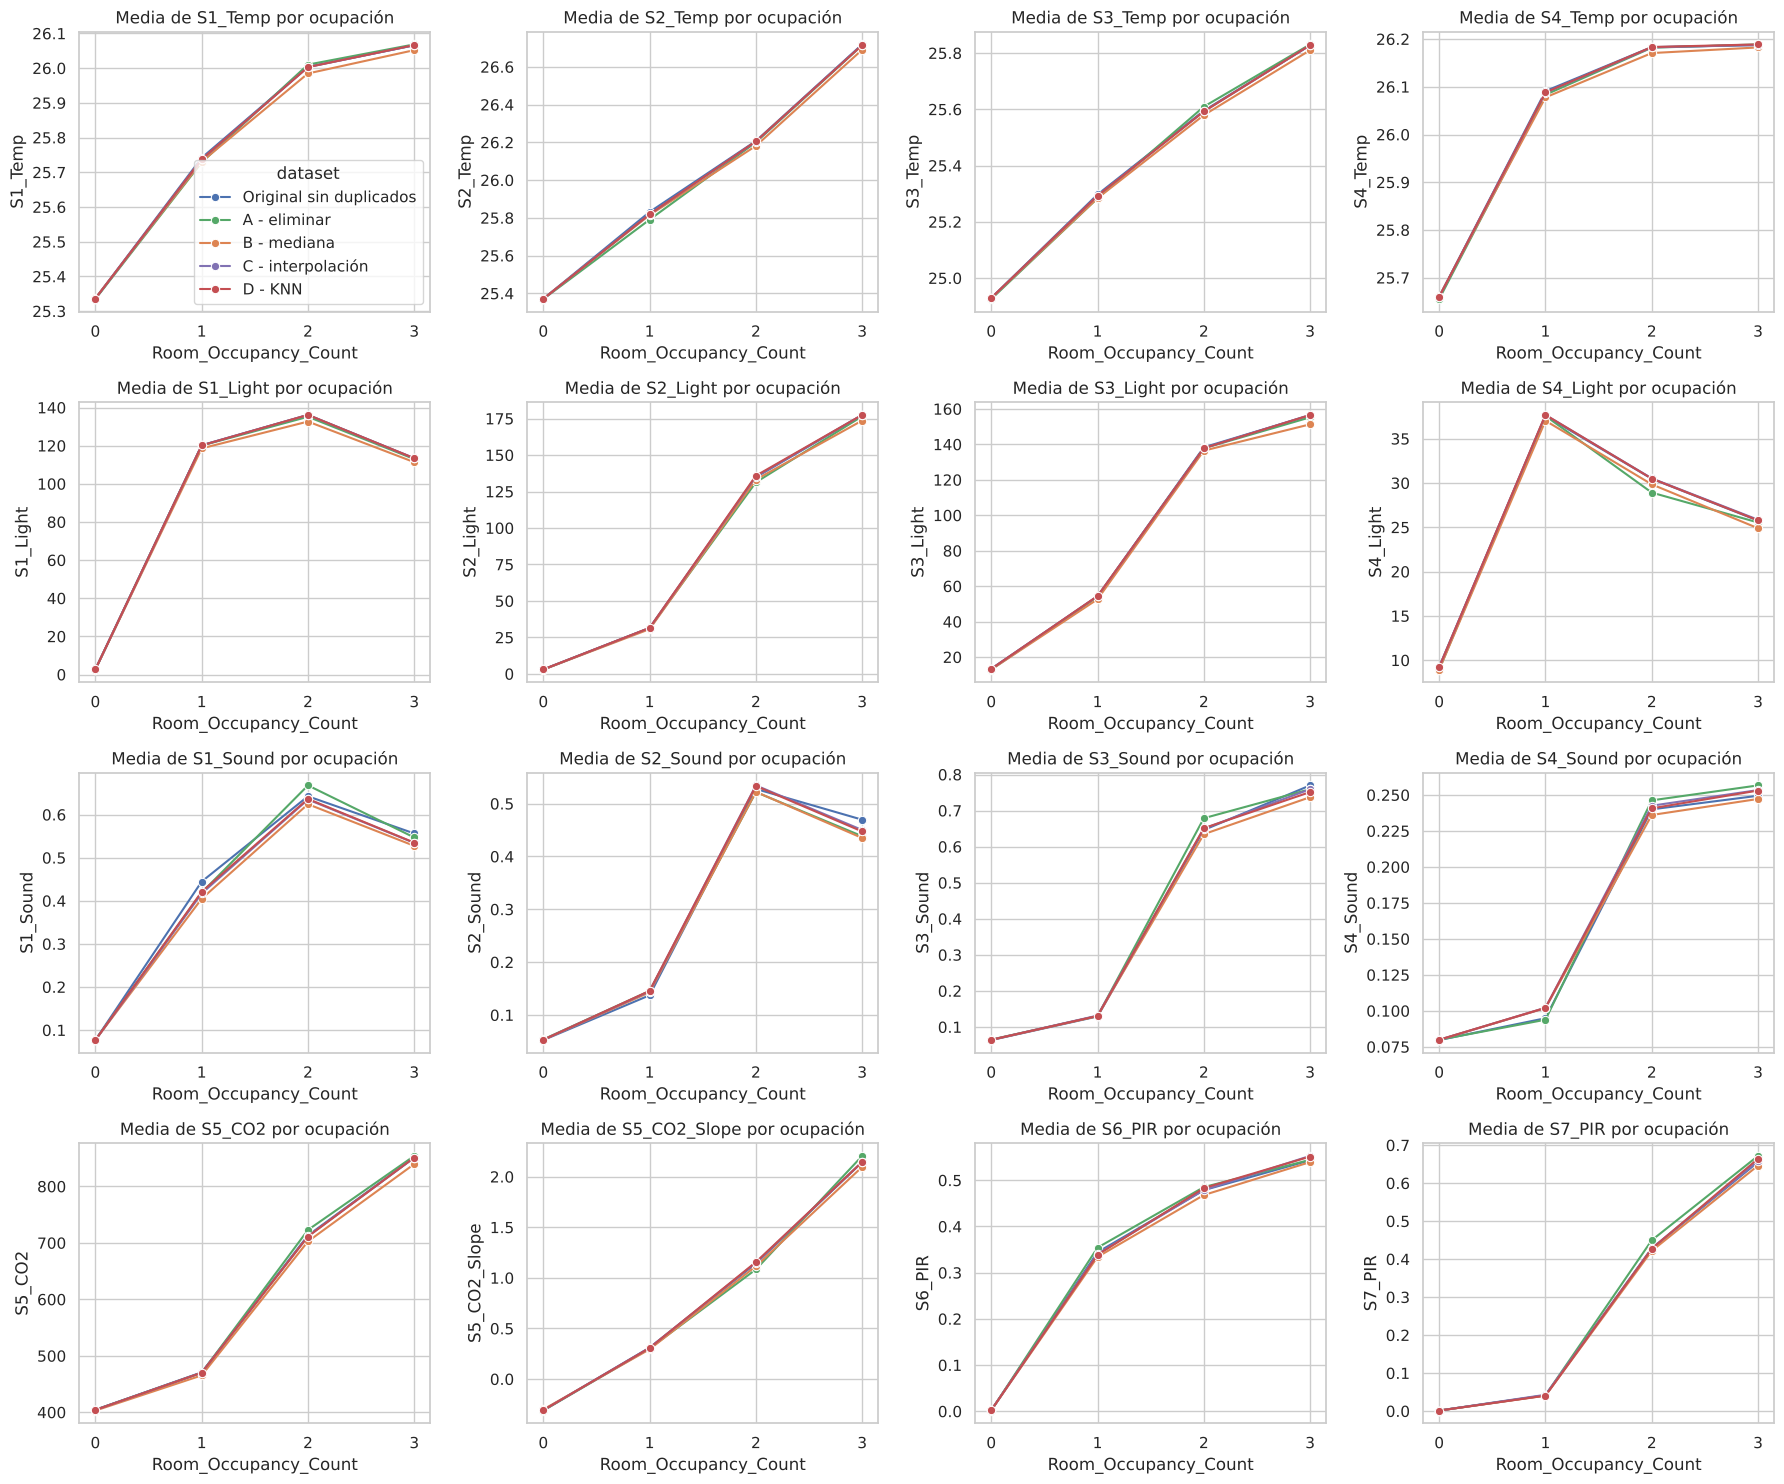

In [48]:
means_by_target = pd.concat(
    [d.groupby(TARGET)[numeric_features].mean().assign(dataset=name).reset_index() for name, d in datasets.items()],
    ignore_index=True,
)
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, column in zip(axes.flat, numeric_features):
    sns.lineplot(data=means_by_target, x=TARGET, y=column, hue="dataset", palette=PALETTE,
                 marker="o", ax=ax, legend=(column == numeric_features[0]))
    ax.set_title(f"Media de {column} por ocupación")
    ax.set_xticks([0, 1, 2, 3])
plt.tight_layout()
plt.show()

Las tendencias se conservan en todas las estrategias: la luz, el CO₂, el sonido y los PIR crecen con el número de
ocupantes. Las desviaciones aparecen sobre todo en la estrategia B para las clases 1–3, porque la mediana imputa valores
de *sala vacía* en filas donde la sala estaba ocupada.

## 8.6 Correlaciones (Pearson y Spearman)

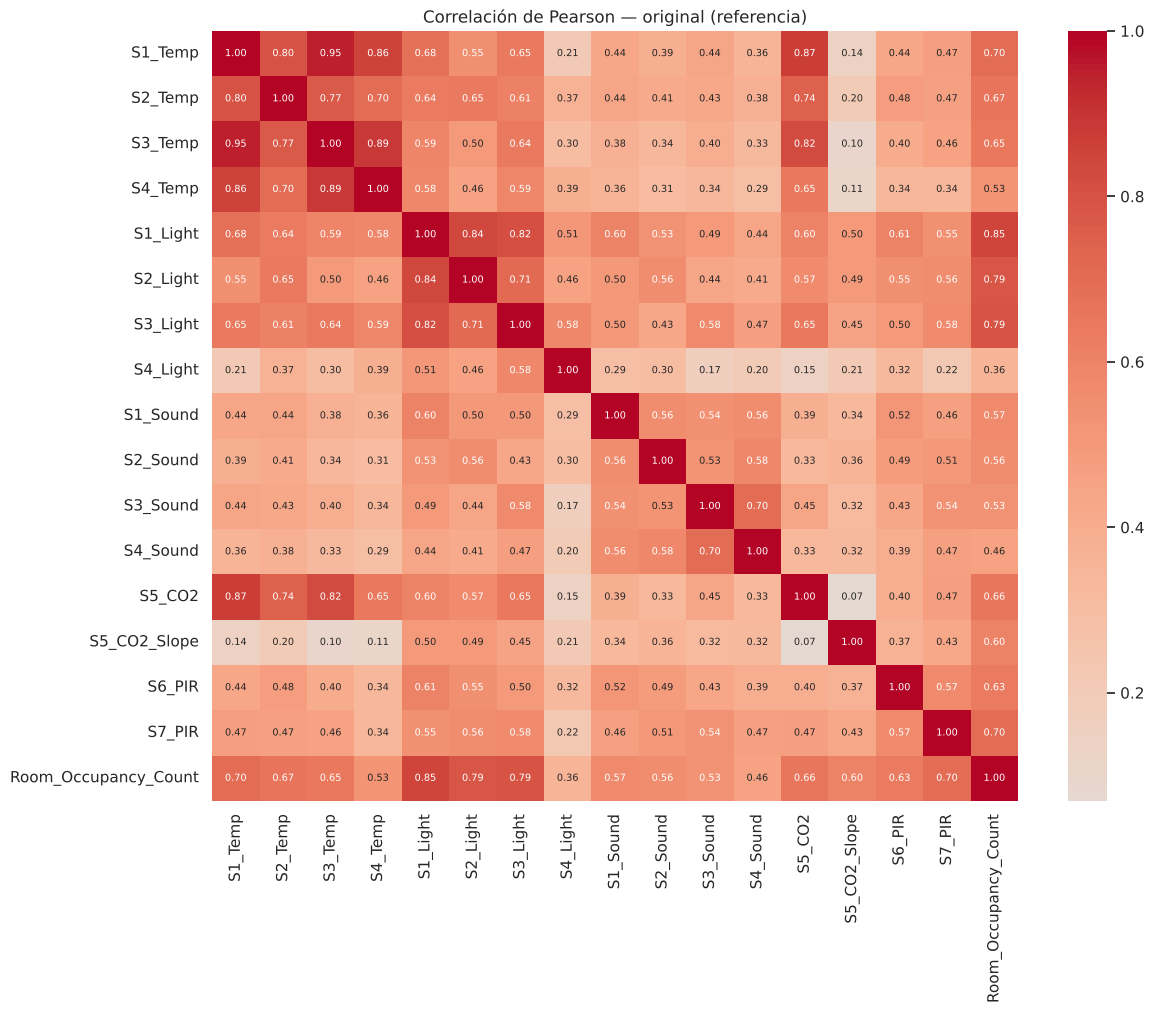

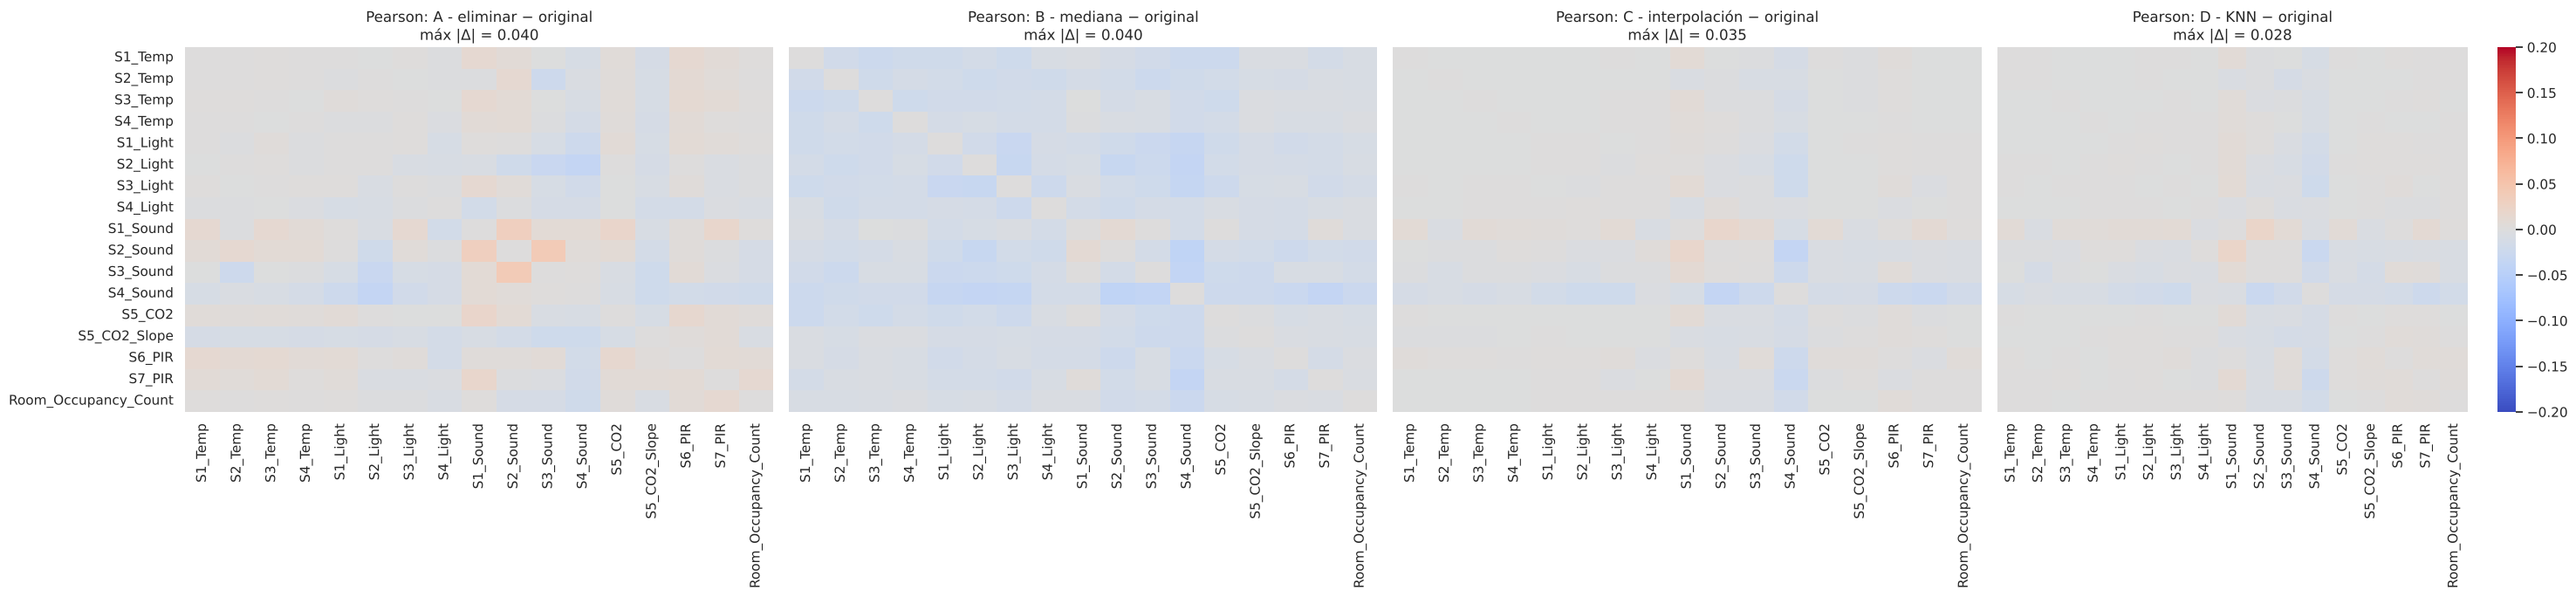

In [49]:
corr_cols = numeric_features + [TARGET]


def corr_diff_heatmaps(method):
    ref = datasets[REFERENCE][corr_cols].corr(method=method)
    fig, axes = plt.subplots(1, 4, figsize=(30, 7))
    for ax, name in zip(axes, CANDIDATES):
        diff = datasets[name][corr_cols].corr(method=method) - ref
        sns.heatmap(diff, cmap="coolwarm", center=0, vmin=-0.2, vmax=0.2, ax=ax, cbar=(name == CANDIDATES[-1]),
                    xticklabels=True, yticklabels=(name == CANDIDATES[0]))
        ax.set_title(f"{method.title()}: {name} − original\nmáx |Δ| = {diff.abs().max().max():.3f}")
    plt.tight_layout()
    plt.show()


ref_pearson = datasets[REFERENCE][corr_cols].corr(method="pearson")
plt.figure(figsize=(13, 10))
sns.heatmap(ref_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlación de Pearson — original (referencia)")
plt.show()

corr_diff_heatmaps("pearson")

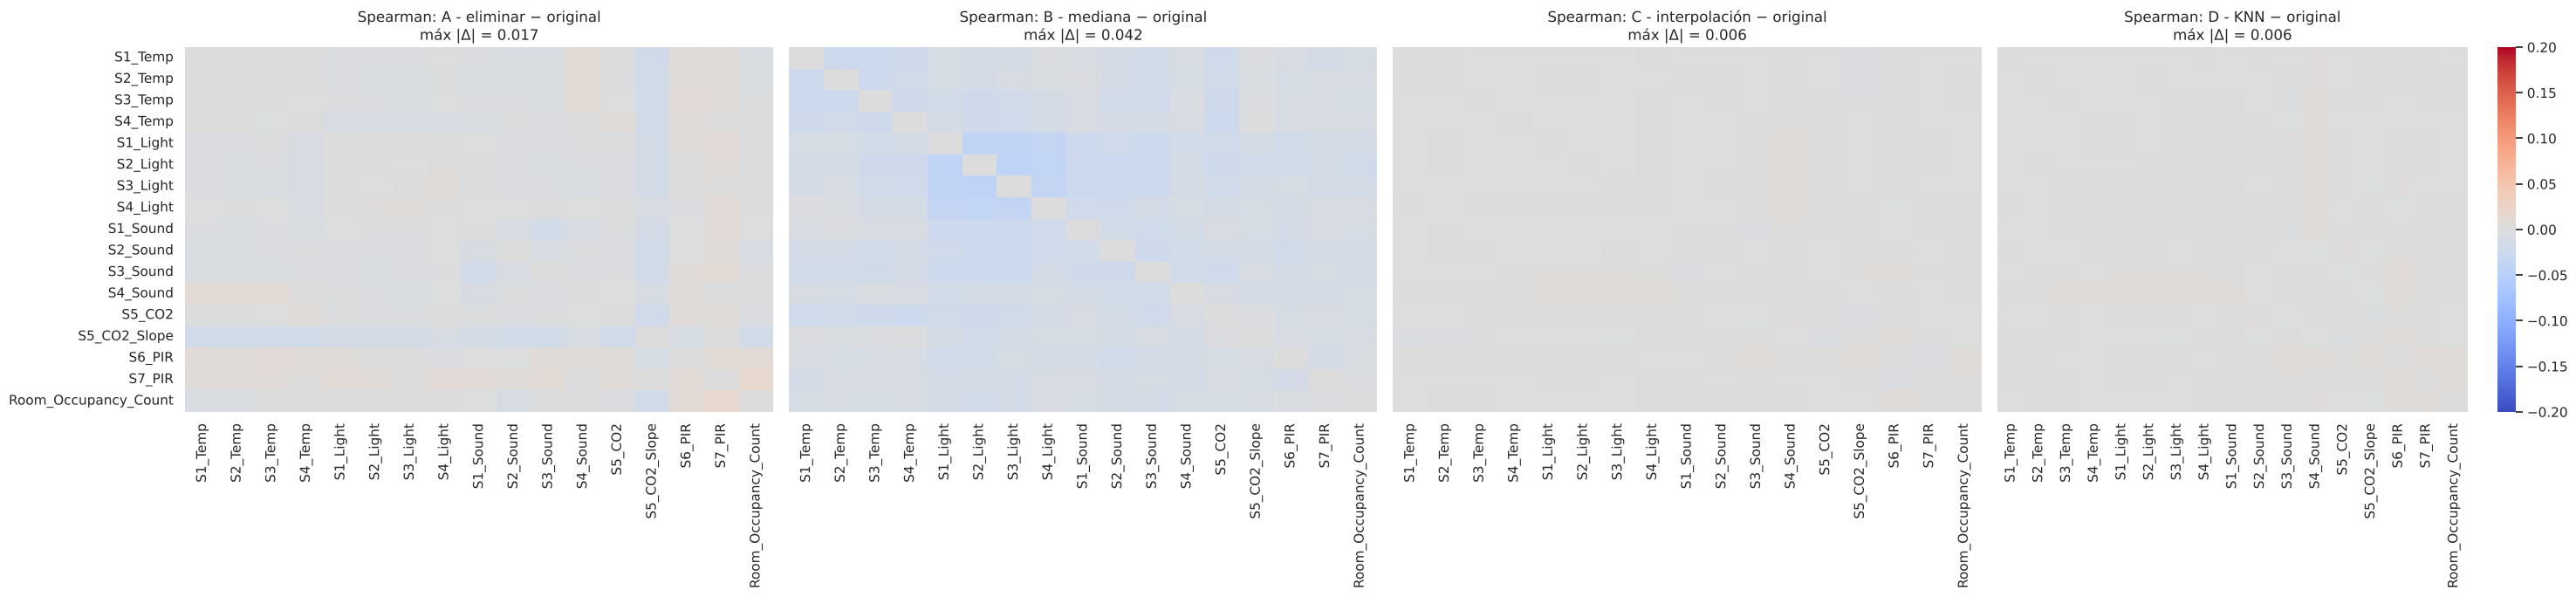

In [50]:
corr_diff_heatmaps("spearman")

Los mapas de diferencias usan una escala estrecha (±0.2) para que los cambios pequeños se vean. Las celdas casi blancas
indican que la relación entre dos variables no cambió con la limpieza.

In [51]:
# Correlación con la ocupación: los números que más suelen guiar la selección de variables
target_corr = pd.DataFrame({
    name: d[corr_cols].corr(method="pearson")[TARGET].drop(TARGET) for name, d in datasets.items()
})
target_corr.sort_values(REFERENCE, key=lambda s: s.abs(), ascending=False).round(3)

,Original sin duplicados,A - eliminar,B - mediana,C - interpolación,D - KNN
S1_Light,0.849,0.851,0.839,0.850,0.850
S3_Light,0.793,0.791,0.780,0.793,0.793
S2_Light,0.789,0.786,0.779,0.789,0.790
S1_Temp,0.701,0.703,0.692,0.701,0.701
S7_PIR,0.695,0.708,0.690,0.697,0.699
S2_Temp,0.671,0.671,0.663,0.671,0.672
S5_CO2,0.660,0.664,0.650,0.660,0.660
S3_Temp,0.652,0.655,0.645,0.651,0.651
S6_PIR,0.633,0.640,0.630,0.638,0.639
S5_CO2_Slope,0.601,0.595,0.592,0.600,0.601


In [52]:
# Ranking de variables por |correlación con la ocupación|: ¿la limpieza cambia cuáles parecen importantes?
top_k = 6
rankings = {name: target_corr[name].abs().sort_values(ascending=False).head(top_k).index.tolist() for name in datasets}
pd.DataFrame(rankings, index=[f"#{i + 1}" for i in range(top_k)])

,Original sin duplicados,A - eliminar,B - mediana,C - interpolación,D - KNN
#1,S1_Light,S1_Light,S1_Light,S1_Light,S1_Light
#2,S3_Light,S3_Light,S3_Light,S3_Light,S3_Light
#3,S2_Light,S2_Light,S2_Light,S2_Light,S2_Light
#4,S1_Temp,S7_PIR,S1_Temp,S1_Temp,S1_Temp
#5,S7_PIR,S1_Temp,S7_PIR,S7_PIR,S7_PIR
#6,S2_Temp,S2_Temp,S2_Temp,S2_Temp,S2_Temp


## 8.7 Perfil multivariado estandarizado por ocupación

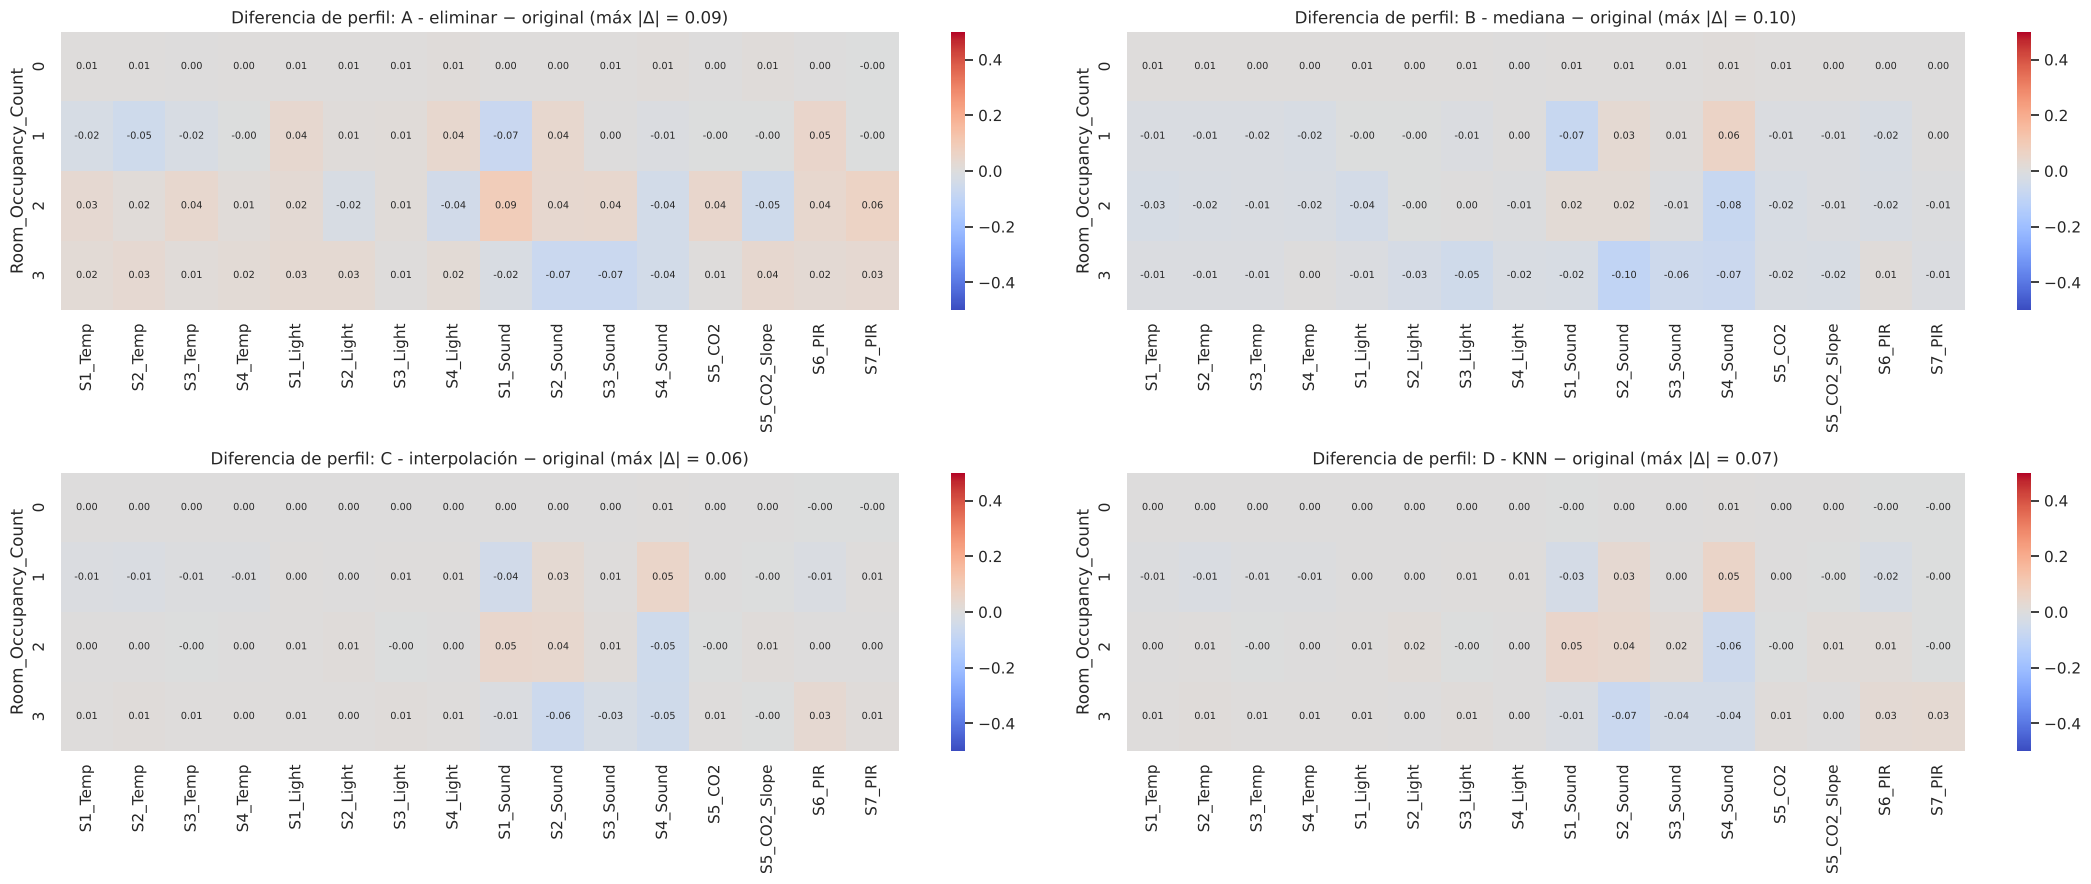

In [53]:
def standardized_profile(d):
    means = d.groupby(TARGET)[numeric_features].mean()
    return (means - d[numeric_features].mean()) / d[numeric_features].std()


ref_profile = standardized_profile(datasets[REFERENCE])
fig, axes = plt.subplots(2, 2, figsize=(22, 9))
for ax, name in zip(axes.flat, CANDIDATES):
    diff = standardized_profile(datasets[name]) - ref_profile
    sns.heatmap(diff, cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f",
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"Diferencia de perfil: {name} − original (máx |Δ| = {diff.abs().max().max():.2f})")
plt.tight_layout()
plt.show()

## 8.8 Pruebas formales de distribución

Las gráficas persuaden pero son subjetivas. Tres métricas hacen medible la afirmación "las distribuciones se
corresponden":

| Métrica | Qué mide | Criterio de "equivalente" |
|---|---|---|
| **Kolmogorov–Smirnov (KS) de dos muestras** | La mayor distancia entre las dos distribuciones acumuladas | p-value > 0.05 |
| **Diferencia de medias estandarizada (SMD)** | Desplazamiento de la media, en desviaciones estándar del original | \|SMD\| < 0.1 es despreciable |
| **Razón de varianzas** | Dispersión limpia / dispersión del original | entre 0.9 y 1.1 |

> Con ~10,000 filas el KS es muy sensible, y en variables discretas o con muchos ceros (luz, PIR) es conservador por los
> empates. Por eso lo combino con SMD y razón de varianzas, y uso la chi-cuadrado (8.2) para el objetivo.

In [54]:
def distribution_tests(name, ref_name=REFERENCE):
    ref, d = datasets[ref_name], datasets[name]
    rows = []
    for column in numeric_features:
        ks = stats.ks_2samp(ref[column], d[column])
        rows.append({
            "variable": column,
            "ks_stat": ks.statistic,
            "ks_pvalue": ks.pvalue,
            "smd": (d[column].mean() - ref[column].mean()) / ref[column].std(),
            "variance_ratio": d[column].var() / ref[column].var(),
        })
    out = pd.DataFrame(rows).set_index("variable")
    out["equivalente"] = (out["ks_pvalue"] > 0.05) & (out["smd"].abs() < 0.1) & out["variance_ratio"].between(0.9, 1.1)
    return out


all_tests = {name: distribution_tests(name) for name in CANDIDATES}
pd.concat({name: t[["ks_pvalue", "smd", "variance_ratio", "equivalente"]] for name, t in all_tests.items()},
          axis=1).round(3)

A - eliminar                                   B - mediana                                   C - interpolación                                     D - KNN         \
                ks_pvalue    smd variance_ratio equivalente   ks_pvalue    smd variance_ratio equivalente         ks_pvalue    smd variance_ratio equivalente ks_pvalue    smd   
variable                                                                                                                                                                         
S1_Temp             0.753 -0.011          0.995        True       0.495 -0.007          0.973        True               1.0 -0.002          0.996        True       1.0 -0.002   
S2_Temp             0.778 -0.012          0.974        True       0.459 -0.008          0.969        True               1.0 -0.003          0.990        True       1.0 -0.004   
S3_Temp             0.804 -0.012          1.005        True       0.343 -0.009          0.975        True               1.0 -0.002          0.996        True       1.0 -0.002   
S4_Temp             0.936 -0.018          0.999        True       0.547 -0.004          0.978        True               1.0 -0.001          0.997        True       1.0 -0.001   
S1_Light            0.605 -0.015          0.975        True       0.430 -0.012          0.983        True               1.0 -0.002          0.997        True       1.0 -0.002   
S2_Light            0.575 -0.011          0.974        True       0.379 -0.008          0.984        True               1.0 -0.001          0.998        True       1.0 -0.000   
S3_Light            0.464 -0.014          0.989        True       0.434 -0.016          0.980        True               1.0 -0.002          0.996        True       1.0 -0.002   
S4_Light            0.348 -0.025          0.977        True       0.392 -0.020          0.983        True               1.0 -0.001          1.001        True       1.0 -0.002   
S1_Sound            1.000 -0.006          0.990        True       0.695 -0.017          0.917        True               1.0 -0.011          0.926        True       1.0 -0.011   
S2_Sound            1.000 -0.008          0.937        True       0.884 -0.008          0.960        True               1.0 -0.001          0.981        True       1.0 -0.002   
S3_Sound            1.000  0.004          1.057        True       0.655 -0.007          0.977        True               1.0 -0.000          1.000        True       1.0 -0.001   
S4_Sound            0.998  0.006          1.165       False       0.556 -0.000          1.087        True               1.0  0.007          1.130       False       1.0  0.006   
S5_CO2              0.987 -0.000          1.007        True       0.520 -0.016          0.977        True               1.0 -0.003          0.995        True       1.0 -0.003   
S5_CO2_Slope        0.948 -0.008          1.023        True       0.863 -0.001          0.979        True               1.0 -0.001          1.000        True       1.0 -0.000   
S6_PIR              1.000 -0.006          0.983        True       1.000 -0.007          0.980        True               1.0  0.000          1.000        True       1.0  0.000   
S7_PIR              1.000  0.006          1.018        True       1.000 -0.006          0.983        True               1.0 -0.000          0.999        True       1.0  0.000   

                                         
             variance_ratio equivalente  
variable                                 
S1_Temp               0.996        True  
S2_Temp               0.988        True  
S3_Temp               0.996        True  
S4_Temp               0.997        True  
S1_Light              0.997        True  
S2_Light              1.000        True  
S3_Light              0.995        True  
S4_Light              1.000        True  
S1_Sound              0.927        True  
S2_Sound              0.976        True  
S3_Sound              0.993        True  
S4_Sound              1.108       False  


In [55]:
# Tablero de resultados: cada estrategia contra el original
def corr_gap(name, ref_name=REFERENCE):
    return (datasets[name][corr_cols].corr() - datasets[ref_name][corr_cols].corr()).abs().max().max()


nmae_mean = nmae_table.loc["PROMEDIO"]
scorecard = []
for name in CANDIDATES:
    t = all_tests[name]
    key = name[0]
    scorecard.append({
        "estrategia": name,
        "filas": len(datasets[name]),
        "pct_filas": 100 * len(datasets[name]) / len(baseline_df),
        "variables_equivalentes": f"{int(t['equivalente'].sum())}/{len(t)}",
        "ks_pvalue_min": t["ks_pvalue"].min(),
        "max_abs_smd": t["smd"].abs().max(),
        "rango_razon_var": f"{t['variance_ratio'].min():.3f} - {t['variance_ratio'].max():.3f}",
        "max_abs_dcorr": corr_gap(name),
        "chi2_pvalue_objetivo": chi2_results[name],
        "NMAE_imputacion": nmae_mean.get(key, np.nan),
    })
scorecard_df = pd.DataFrame(scorecard).set_index("estrategia")
scorecard_df.round(4)

,filas,pct_filas,variables_equivalentes,ks_pvalue_min,max_abs_smd,rango_razon_var,max_abs_dcorr,chi2_pvalue_objetivo,NMAE_imputacion
estrategia,,,,,,,,,
A - eliminar,6889,68.0126,15/16,0.3475,0.0252,0.937 - 1.165,0.0399,0.7087,NaN
B - mediana,9914,97.8774,16/16,0.3433,0.0198,0.917 - 1.087,0.0396,0.9935,0.5430
C - interpolación,9914,97.8774,15/16,1.0000,0.0115,0.926 - 1.130,0.0354,0.9935,0.1312
D - KNN,9914,97.8774,15/16,1.0000,0.0105,0.927 - 1.108,0.0275,0.9935,0.1557


# 9. EDA del dataset limpio seleccionado

Con la evidencia de las secciones 7 y 8 selecciono la **estrategia C (interpolación temporal)** como dataset de trabajo:
conserva prácticamente todas las filas del original, tiene el menor error de imputación y reproduce sus distribuciones y
correlaciones. Sobre ella realizo el EDA completo, siguiendo la estructura del notebook 1.3 y agregando un análisis
temporal propio de este tipo de datos:

1. Estructura y calidad.
2. Variable objetivo.
3. Análisis univariado, asimetría y atípicos potenciales.
4. Relación de cada predictora con la ocupación.
5. Correlaciones (Pearson y Spearman) y pares redundantes.
6. Perfil multivariado por ocupación.
7. Patrones temporales.

In [56]:
eda_df = clean["C"].copy()
print(f"Filas: {eda_df.shape[0]:,}   Columnas: {eda_df.shape[1]}")
print(f"Periodo: {eda_df['timestamp'].min()} -> {eda_df['timestamp'].max()}")

pd.DataFrame({
    "dtype": eda_df.dtypes.astype(str),
    "faltantes": eda_df.isna().sum(),
    "n_unicos": eda_df.nunique(),
}).T

Filas: 9,914   Columnas: 18
Periodo: 2017-12-22 10:49:41 -> 2018-01-11 09:00:09


,timestamp,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
dtype,datetime64[us],float64,float64,float64,float64,int64,int64,int64,int64,float64,float64,float64,float64,int64,float64,int64,int64,int64
faltantes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
n_unicos,9914,52,99,66,57,68,83,176,75,220,184,255,110,184,1694,2,2,4


## 9.1 Variable objetivo

                      conteo  porcentaje
Room_Occupancy_Count                    
0                       8063       81.33
1                        443        4.47
2                        735        7.41
3                        673        6.79


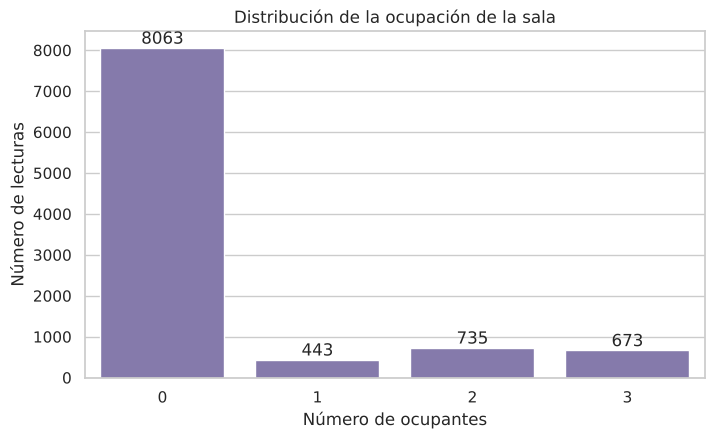

In [57]:
target_summary = pd.DataFrame({
    "conteo": eda_df[TARGET].value_counts().sort_index(),
    "porcentaje": eda_df[TARGET].value_counts(normalize=True).sort_index() * 100,
})
print(target_summary.round(2).to_string())

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=eda_df, x=TARGET, color="#8172b3")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Distribución de la ocupación de la sala")
plt.xlabel("Número de ocupantes")
plt.ylabel("Número de lecturas")
plt.show()

La clase 0 (sala vacía) domina con más del 80 % de las lecturas, y la clase 1 es la menos frecuente. Este desbalance es
la primera implicación para el modelado: el *accuracy* sería engañoso (un modelo que siempre prediga "vacía" acertaría
más del 80 %), por lo que convendrá usar F1 macro o *balanced accuracy* y una partición estratificada.

## 9.2 Análisis univariado

In [58]:
univariate_eda = eda_df[numeric_features].describe().T
univariate_eda["median"] = eda_df[numeric_features].median()
univariate_eda["skewness"] = eda_df[numeric_features].skew()
univariate_eda["kurtosis"] = eda_df[numeric_features].kurt()
univariate_eda[["mean", "median", "std", "min", "25%", "75%", "max", "skewness", "kurtosis"]] \
    .sort_values("skewness", key=lambda x: x.abs(), ascending=False).round(3)

,mean,median,std,min,25%,75%,max,skewness,kurtosis
S4_Sound,0.105,0.08,0.128,0.050,0.060,0.10,3.440,11.493,219.727
S2_Sound,0.120,0.05,0.264,0.040,0.050,0.06,4.100,6.858,63.012
S3_Sound,0.158,0.06,0.414,0.040,0.060,0.07,4.620,6.012,39.843
S1_Sound,0.165,0.08,0.305,0.060,0.070,0.08,3.880,5.555,41.639
S7_PIR,0.079,0.00,0.271,0.000,0.000,0.00,1.000,3.110,7.672
S6_PIR,0.090,0.00,0.286,0.000,0.000,0.00,1.000,2.862,6.192
S2_Light,25.970,0.00,67.247,0.000,0.000,14.00,257.000,2.830,6.205
S2_Temp,25.544,25.38,0.583,24.750,25.190,25.63,29.000,2.369,6.613
S3_Light,34.128,0.00,58.287,0.000,0.000,50.00,280.000,2.103,3.899
S5_CO2,460.311,360.00,199.431,345.000,355.000,465.00,1270.000,1.983,3.030


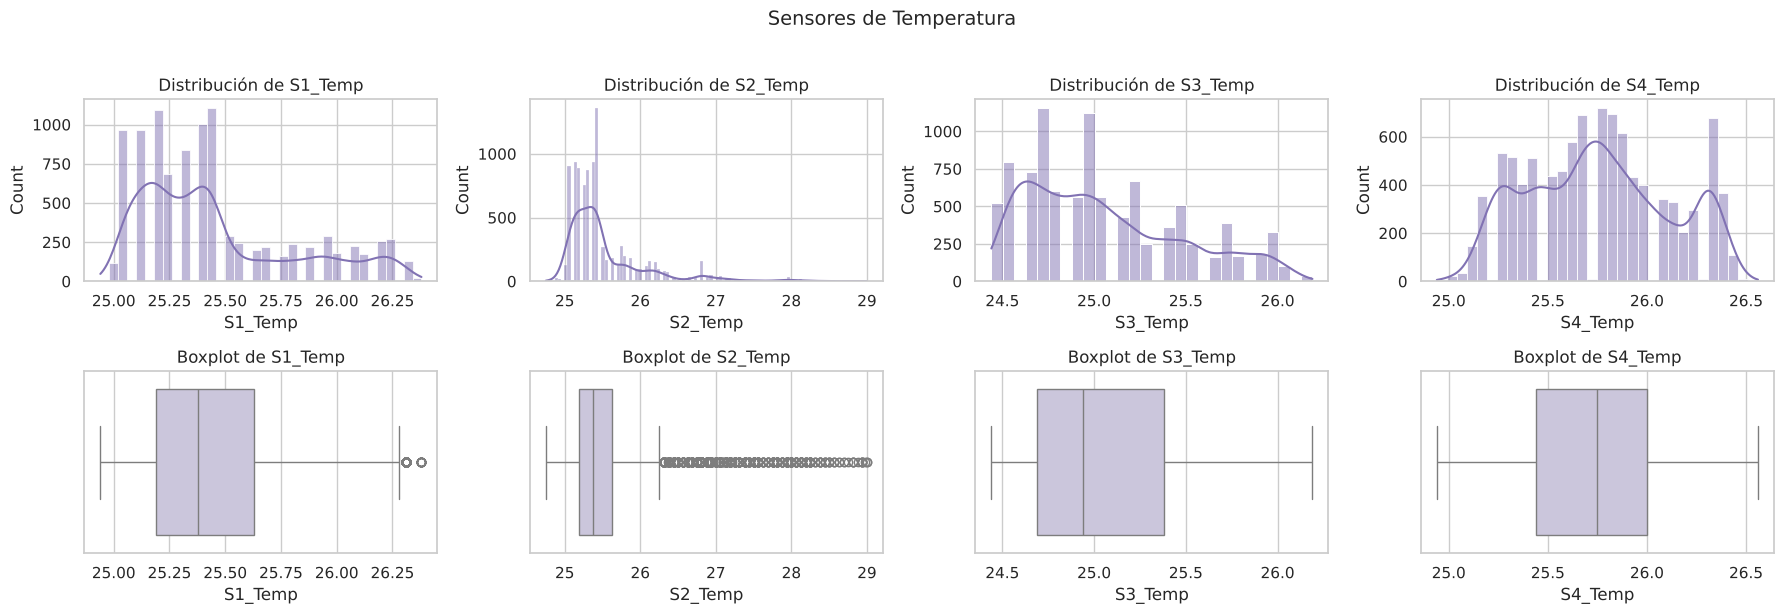

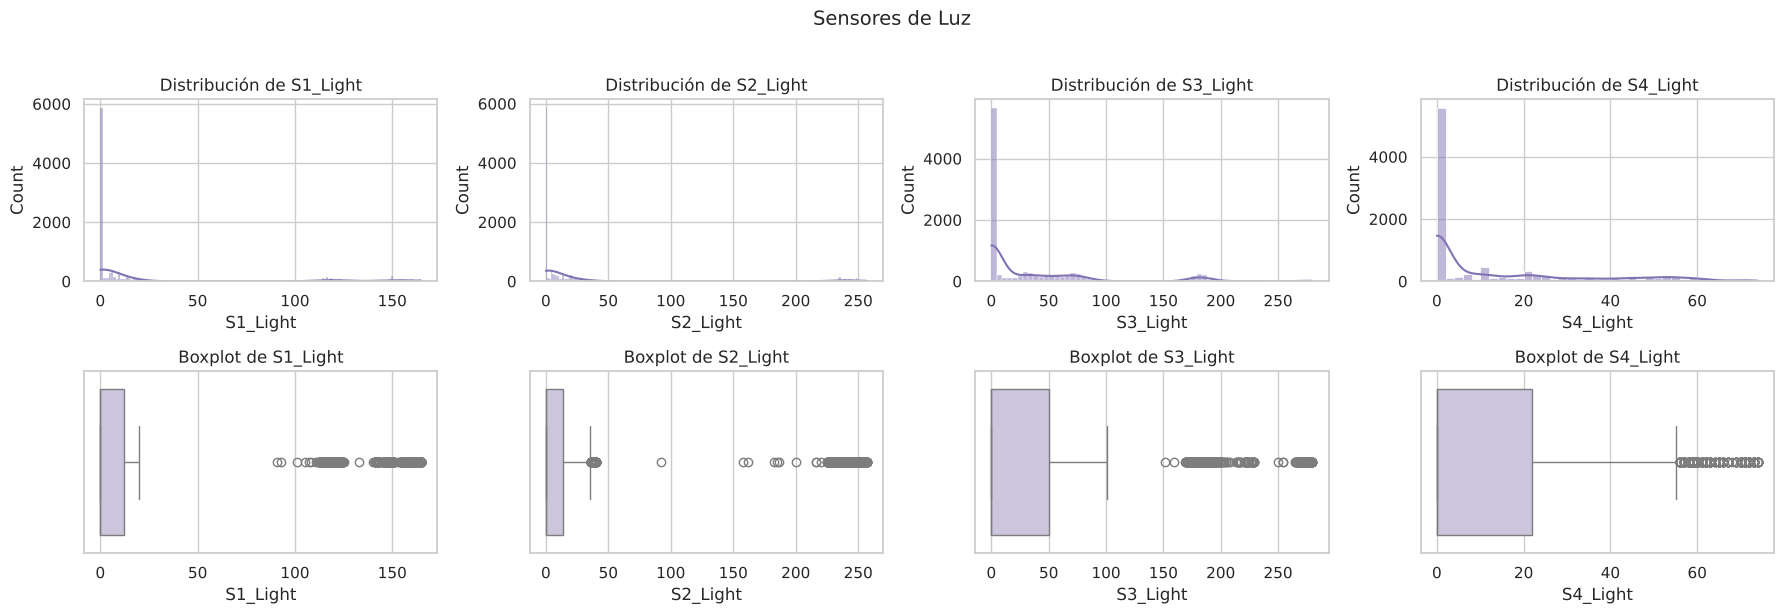

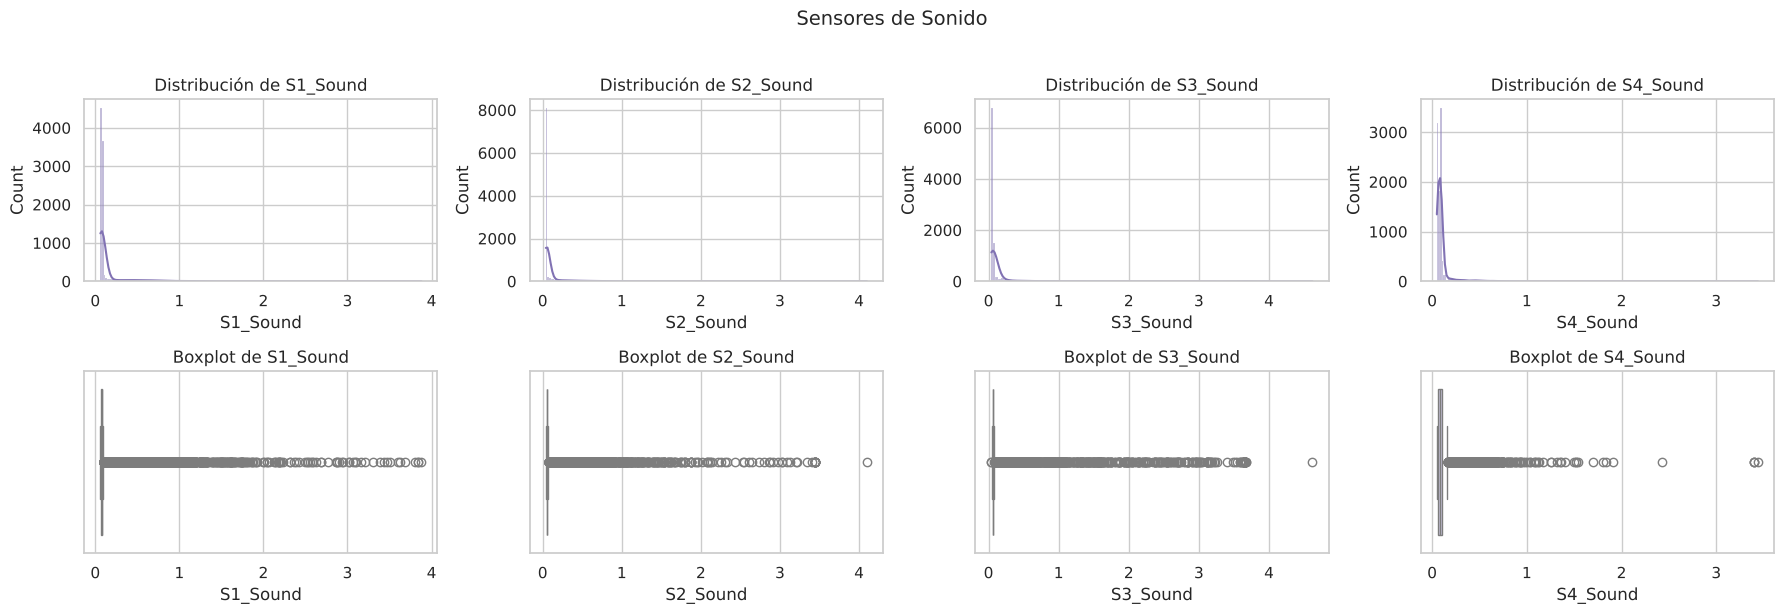

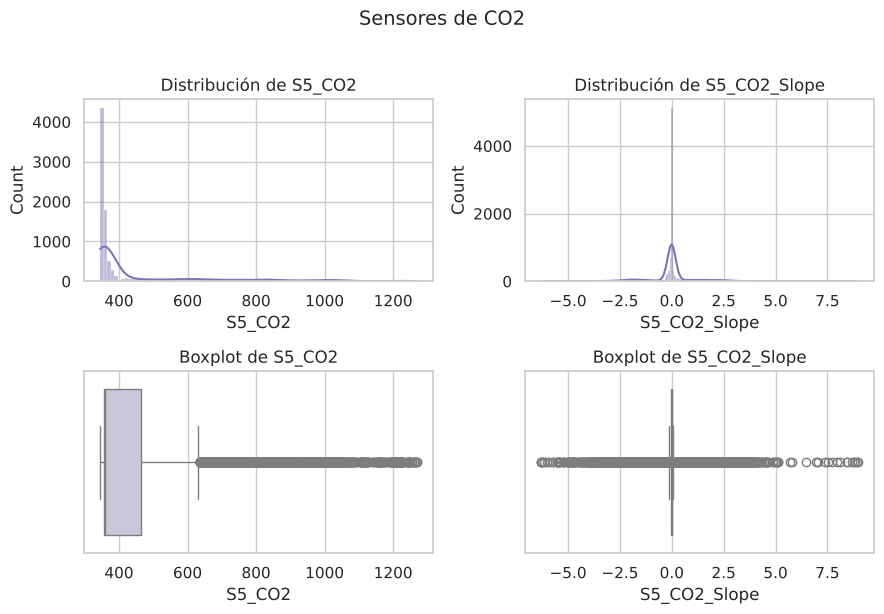

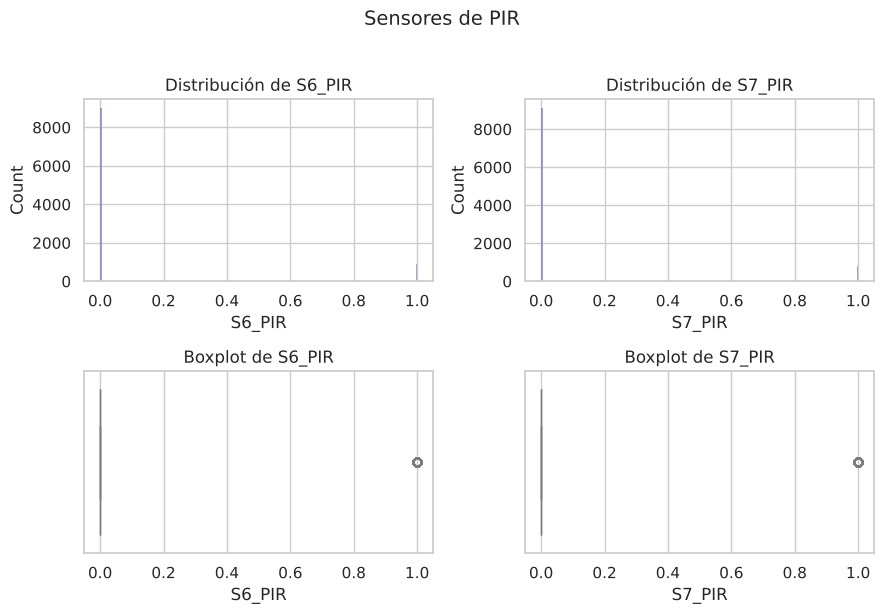

In [59]:
# Distribución + boxplot por grupo de sensores
for group, cols in SENSOR_GROUPS.items():
    fig, axes = plt.subplots(2, len(cols), figsize=(4.5 * len(cols), 6))
    axes = np.array(axes).reshape(2, -1)
    for j, column in enumerate(cols):
        sns.histplot(data=eda_df, x=column, kde=column not in BINARY_COLUMNS, ax=axes[0, j], color="#8172b3")
        axes[0, j].set_title(f"Distribución de {column}")
        sns.boxplot(data=eda_df, x=column, ax=axes[1, j], color="#c9c2e0")
        axes[1, j].set_title(f"Boxplot de {column}")
    fig.suptitle(f"Sensores de {group}", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

**Lectura.** Los sensores muestran dos comportamientos muy distintos:

- **Temperatura**: distribuciones casi simétricas en un rango estrecho (24.4–29 °C), con `S2_Temp` algo más dispersa.
- **Luz, sonido, CO₂ y PIR**: fuertemente asimétricas a la derecha, con una masa enorme en el estado basal (luz = 0,
  sonido ≈ 0.05 V, CO₂ ≈ 350 ppm, PIR = 0) y una cola que corresponde a los momentos de ocupación. Esta forma bimodal o
  de "cero inflado" es precisamente la que contiene la señal predictiva.

In [60]:
outlier_rows = []
for column in numeric_features:
    q1, q3 = eda_df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (eda_df[column] < lower) | (eda_df[column] > upper)
    outlier_rows.append({
        "variable": column, "limite_inferior": lower, "limite_superior": upper,
        "n_atipicos_potenciales": int(mask.sum()), "pct_atipicos": 100 * mask.mean(),
        "pct_ocupada_entre_atipicos": 100 * (eda_df.loc[mask, TARGET] > 0).mean() if mask.any() else np.nan,
    })
pd.DataFrame(outlier_rows).set_index("variable").sort_values("pct_atipicos", ascending=False).round(2)

,limite_inferior,limite_superior,n_atipicos_potenciales,pct_atipicos,pct_ocupada_entre_atipicos
variable,,,,,
S5_CO2_Slope,-0.12,0.07,3940,39.74,45.46
S1_Sound,0.06,0.10,1733,17.48,91.23
S1_Light,-18.00,30.00,1672,16.87,99.94
S2_Sound,0.04,0.07,1670,16.84,90.06
S3_Sound,0.04,0.09,1636,16.50,89.06
S5_CO2,190.00,630.00,1614,16.28,60.78
S2_Light,-21.00,35.00,995,10.04,100.00
S3_Light,-75.00,125.00,925,9.33,100.00
S2_Temp,24.53,26.29,916,9.24,74.56


La última columna es reveladora: en luz, sonido y PIR, entre el 87 % y el 100 % de los "atípicos" IQR ocurren con la sala
ocupada (en el CO₂, el 61 %, porque el gas tarda en disiparse cuando la gente sale). No son errores: son la señal. Recortarlos (*clipping*) o eliminarlos destruiría la información que el modelo
necesita. Para modelos sensibles a la escala, conviene más un `RobustScaler` o una transformación `log1p` en luz y sonido.

## 9.3 Predictoras vs. ocupación

In [61]:
occupancy_profiles = eda_df.groupby(TARGET)[numeric_features].agg(["mean", "median"])
occupancy_profiles.T.round(2)

Room_Occupancy_Count       0       1       2       3
S1_Temp      mean      25.34   25.74   26.00   26.07
             median    25.31   25.88   26.06   26.19
S2_Temp      mean      25.37   25.82   26.20   26.72
             median    25.31   25.75   26.00   26.38
S3_Temp      mean      24.93   25.29   25.59   25.83
             median    24.88   25.50   25.69   25.88
S4_Temp      mean      25.66   26.09   26.18   26.19
             median    25.69   26.25   26.25   26.31
S1_Light     mean       2.68  120.19  136.15  113.42
             median     0.00  120.00  142.00  149.00
S2_Light     mean       3.05   31.53  135.28  177.52
             median     0.00   33.00  226.00  235.00
S3_Light     mean      13.33   54.38  137.87  156.62
             median     0.00   58.00  176.00  180.00
S4_Light     mean       9.21   37.68   30.52   25.85
             median     0.00   41.00   19.00   12.00
S1_Sound     mean       0.08    0.42    0.64    0.53
             median     0.07    0.25    0.53    0.38
S2_Sound     mean       0.05    0.14    0.53    0.45
             median     0.05    0.09    0.39    0.32
S3_Sound     mean       0.06    0.13    0.65    0.76
             median     0.06    0.09    0.30    0.25
S4_Sound     mean       0.08    0.10    0.24    0.25
             median     0.08    0.07    0.18    0.12
S5_CO2       mean     404.24  470.18  711.78  850.98
             median   355.00  440.00  680.00  870.00
S5_CO2_Slope mean      -0.31    0.31    1.15    2.14
             median     0.00    0.30    1.27    2.12
S6_PIR       mean       0.00    0.34    0.48    0.55
             median     0.00    0.00    0.00    1.00
S7_PIR       mean       0.00    0.04    0.43    0.66
             median     0.00    0.00    0.00    1.00

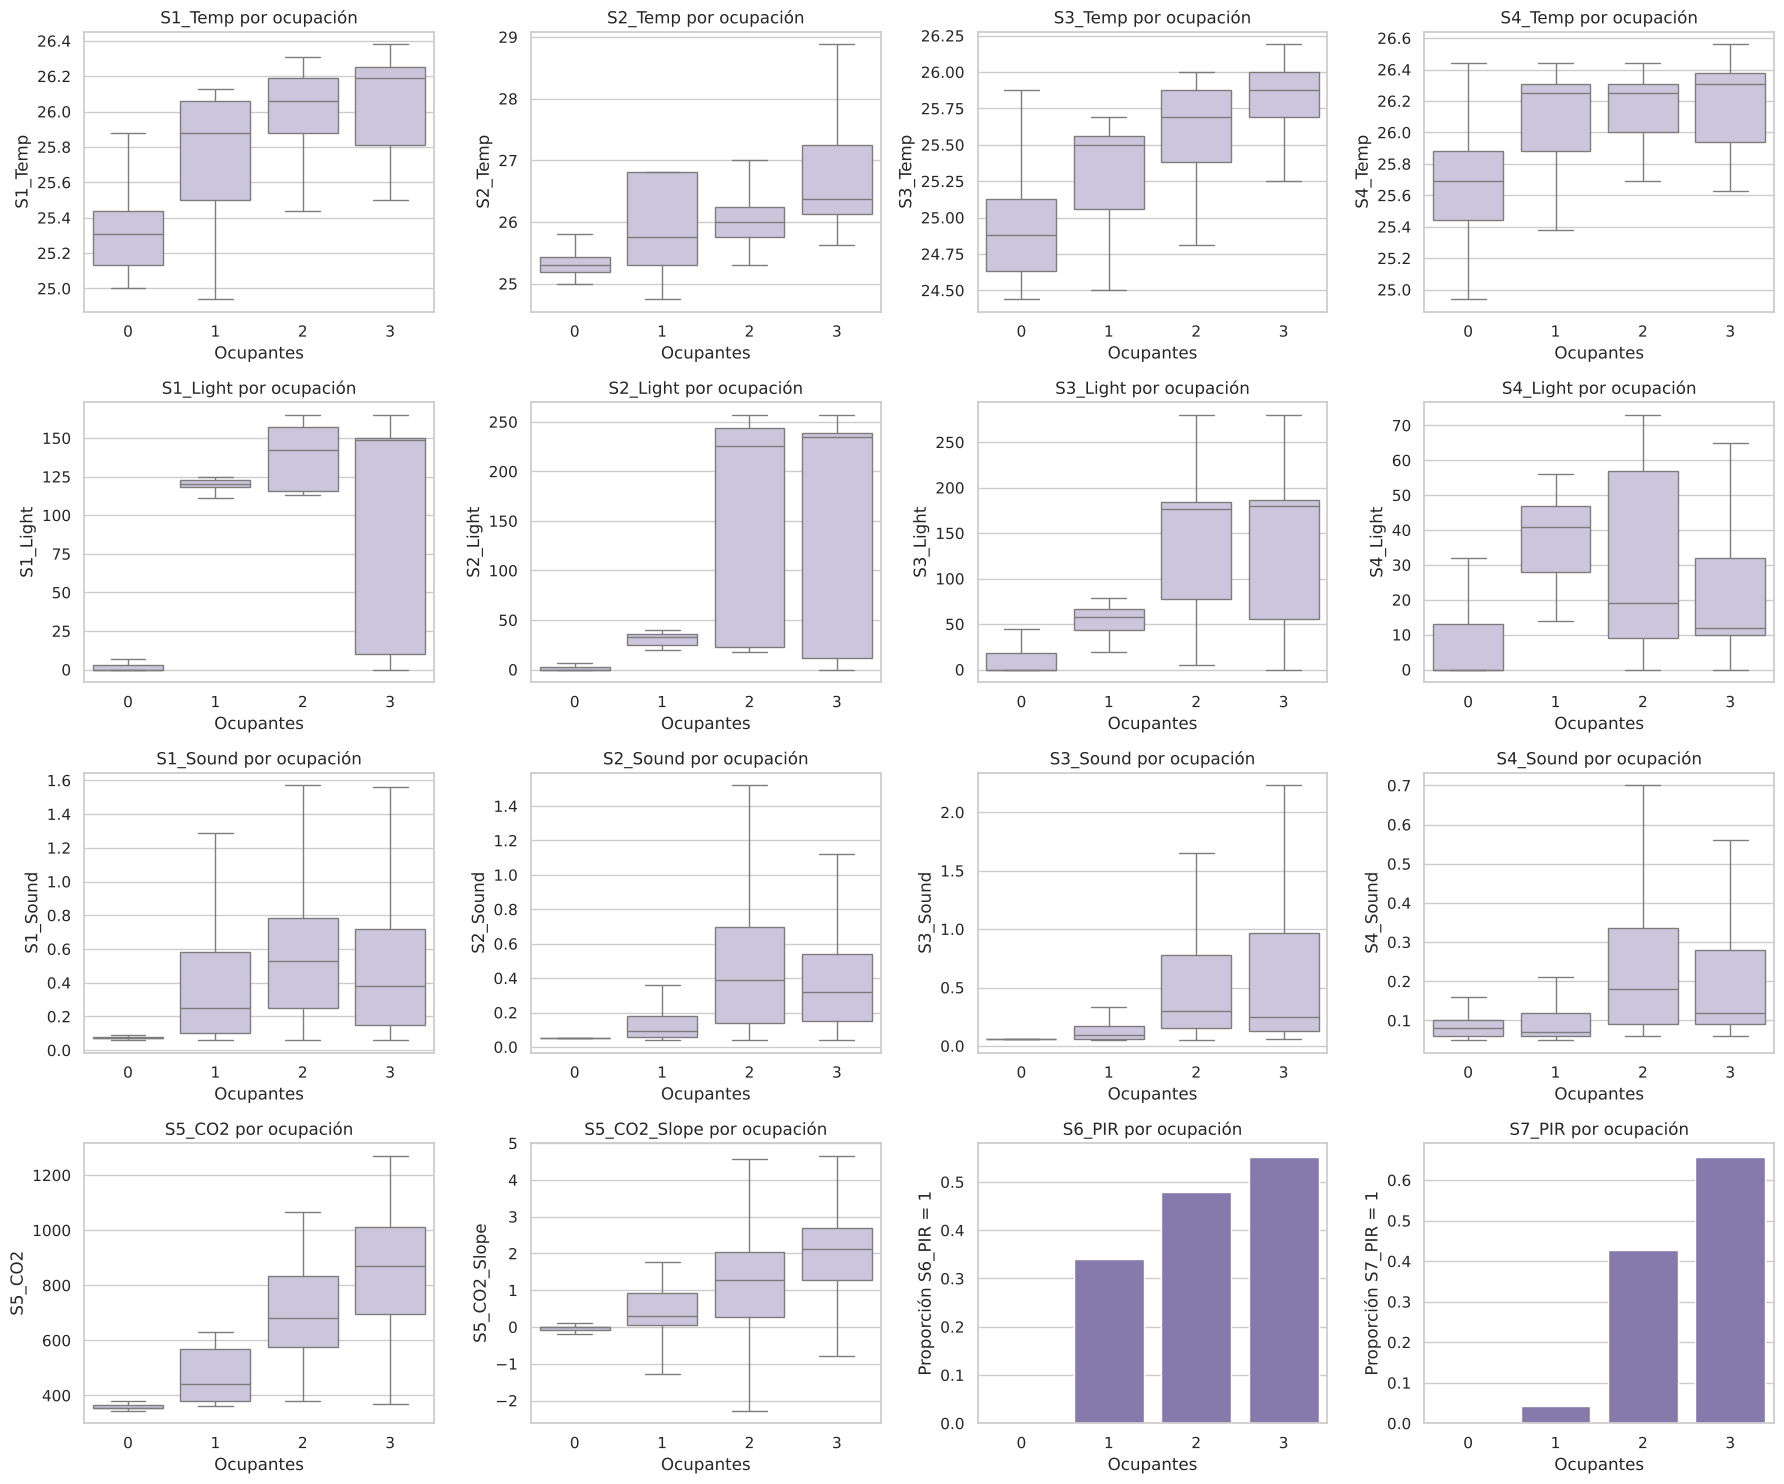

In [62]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, column in zip(axes.flat, numeric_features):
    if column in BINARY_COLUMNS:
        sns.barplot(data=eda_df, x=TARGET, y=column, ax=ax, color="#8172b3", errorbar=None)
        ax.set_ylabel(f"Proporción {column} = 1")
    else:
        sns.boxplot(data=eda_df, x=TARGET, y=column, ax=ax, color="#c9c2e0", showfliers=False)
    ax.set_title(f"{column} por ocupación")
    ax.set_xlabel("Ocupantes")
plt.tight_layout()
plt.show()

**Lectura.** Las variables de luz son las que mejor separan la sala vacía de la ocupada: con la sala vacía la mediana es
0 lux en los cuatro sensores; con un ocupante S1 ya marca 120 lux, y con dos o tres S2 y S3 superan los 170 lux. Esto
sugiere que cada persona trabaja en un puesto con su propia iluminación. El CO₂ y su pendiente crecen de forma monótona
con el número de ocupantes (mediana de 355 ppm con la sala vacía y 870 ppm con tres personas), coherente con la
respiración. Los PIR casi nunca se activan con la sala vacía (las pocas excepciones son las rachas analizadas en T12). El sonido aumenta con la ocupación, aunque con gran dispersión.
La temperatura también sube con más personas (cerca de 0.7 °C en S1), por el calor corporal que se acumula en la sala.

## 9.4 Correlaciones

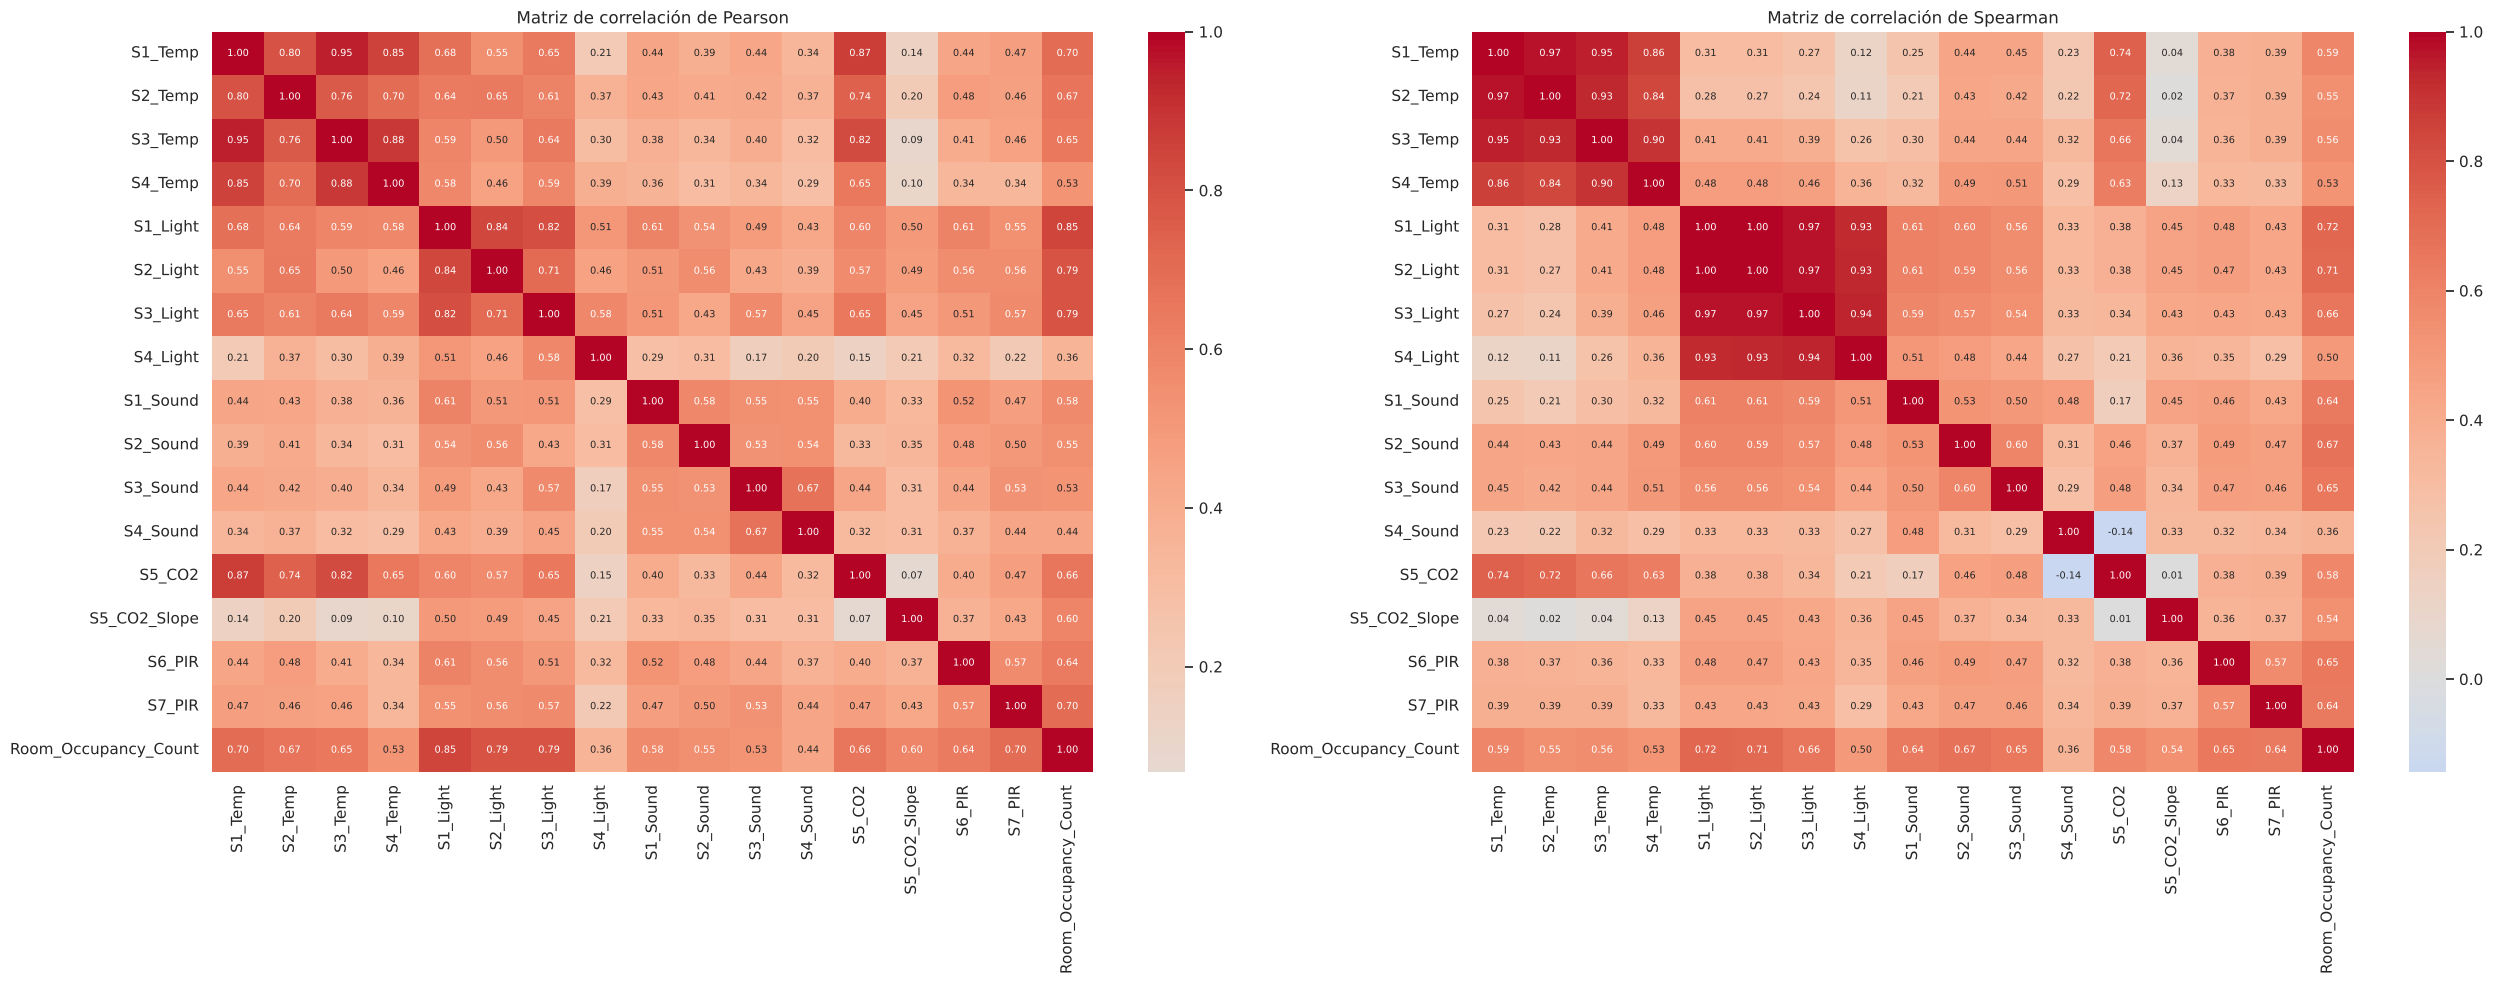

In [63]:
pearson_corr = eda_df[corr_cols].corr(method="pearson")
spearman_corr = eda_df[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(26, 10))
for ax, (title, m) in zip(axes, [("Pearson", pearson_corr), ("Spearman", spearman_corr)]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"Matriz de correlación de {title}")
plt.tight_layout()
plt.show()

In [64]:
target_correlations = pd.DataFrame({
    "pearson": pearson_corr[TARGET].drop(TARGET),
    "spearman": spearman_corr[TARGET].drop(TARGET),
})
target_correlations["spearman_menos_pearson"] = target_correlations["spearman"] - target_correlations["pearson"]
target_correlations.sort_values("pearson", key=lambda s: s.abs(), ascending=False).round(3)

,pearson,spearman,spearman_menos_pearson
S1_Light,0.850,0.719,-0.131
S3_Light,0.793,0.662,-0.132
S2_Light,0.789,0.713,-0.076
S1_Temp,0.701,0.588,-0.113
S7_PIR,0.697,0.640,-0.057
S2_Temp,0.671,0.546,-0.126
S5_CO2,0.660,0.580,-0.080
S3_Temp,0.651,0.556,-0.095
S6_PIR,0.638,0.649,0.011
S5_CO2_Slope,0.600,0.542,-0.058


**Pearson vs. Spearman.** Pearson mide relación lineal; Spearman, relación monótona basada en rangos. En el sonido, la
correlación de Spearman con la ocupación es claramente mayor que la de Pearson: la relación es monótona pero no lineal,
porque el sonido tiene una cola muy larga. Esto sugiere que una transformación logarítmica o modelos basados en árboles
aprovecharían mejor esa variable.

In [65]:
# Pares de predictoras más correlacionados (posible redundancia / multicolinealidad)
feature_corr = eda_df[numeric_features].corr()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
strong_pairs = (
    upper.stack().rename("correlacion").reset_index()
    .rename(columns={"level_0": "variable_1", "level_1": "variable_2"})
)
strong_pairs["abs_correlacion"] = strong_pairs["correlacion"].abs()
strong_pairs.sort_values("abs_correlacion", ascending=False).head(12).round(3)

,variable_1,variable_2,correlacion,abs_correlacion
2,S1_Temp,S3_Temp,0.949,0.949
35,S3_Temp,S4_Temp,0.885,0.885
12,S1_Temp,S5_CO2,0.867,0.867
3,S1_Temp,S4_Temp,0.855,0.855
69,S1_Light,S2_Light,0.843,0.843
44,S3_Temp,S5_CO2,0.821,0.821
70,S1_Light,S3_Light,0.816,0.816
1,S1_Temp,S2_Temp,0.799,0.799
18,S2_Temp,S3_Temp,0.765,0.765
28,S2_Temp,S5_CO2,0.743,0.743


Los cuatro sensores de temperatura y los de luz S1–S3 están altamente correlacionados entre sí: miden el mismo fenómeno
desde distintos puntos de la sala. También destaca la correlación entre la temperatura y el CO₂ (0.87 en S1): ambas son
variables de *acumulación* que crecen mientras la sala está ocupada. Para modelos lineales esto implica
multicolinealidad; una opción sería resumirlos (por ejemplo, la media de las cuatro temperaturas o un PCA por grupo de
sensores).

Variables seleccionadas: ['S1_Light', 'S3_Light', 'S2_Light', 'S1_Temp']


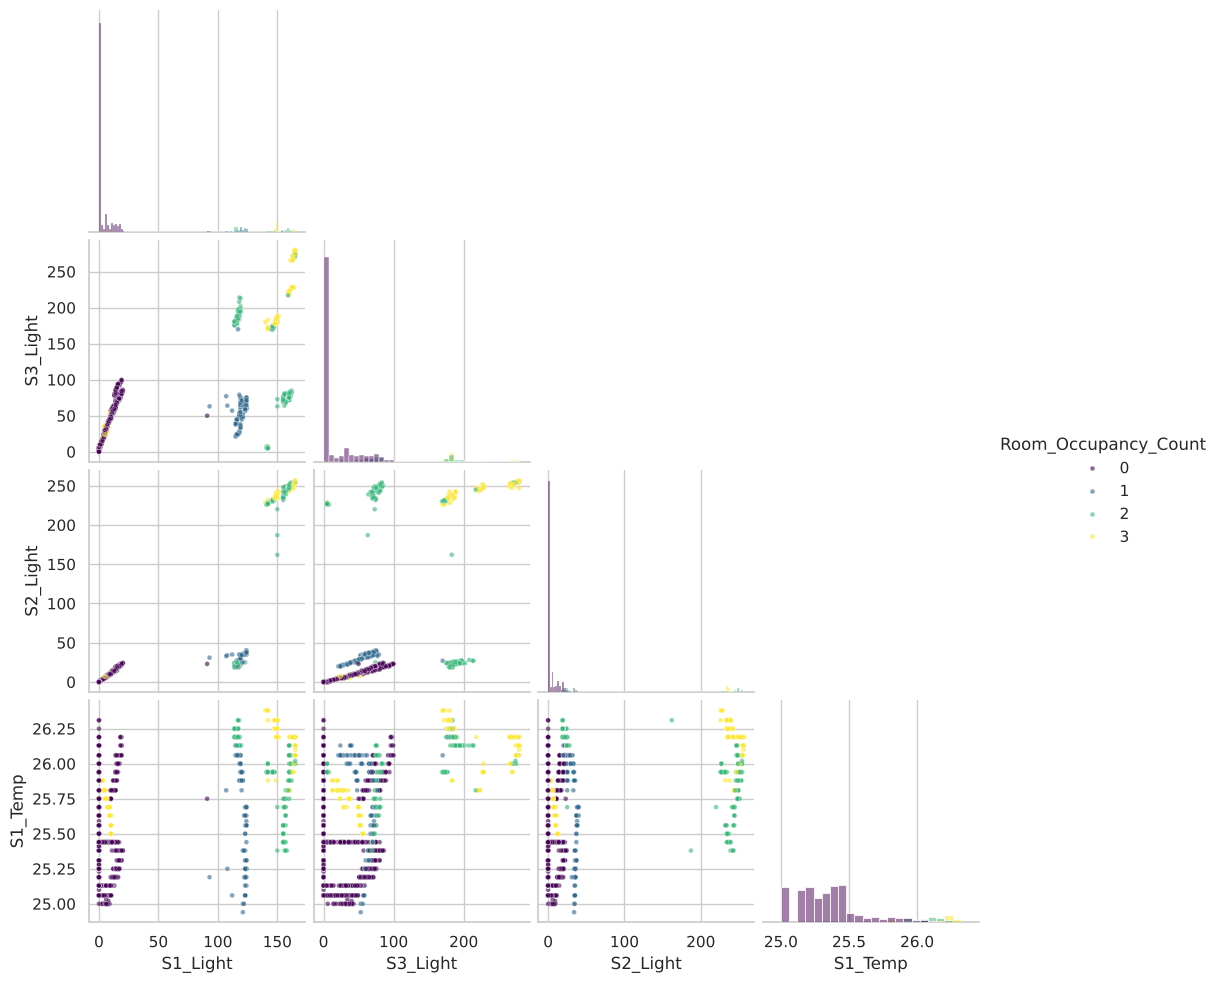

In [66]:
# Vista conjunta de las variables más asociadas con la ocupación
top_features = target_correlations["pearson"].abs().sort_values(ascending=False).head(4).index.tolist()
print("Variables seleccionadas:", top_features)
sns.pairplot(eda_df.sample(3000, random_state=42)[top_features + [TARGET]], hue=TARGET,
             palette="viridis", corner=True, diag_kind="hist", plot_kws={"s": 12, "alpha": 0.6})
plt.show()

## 9.5 Perfil multivariado estandarizado por ocupación

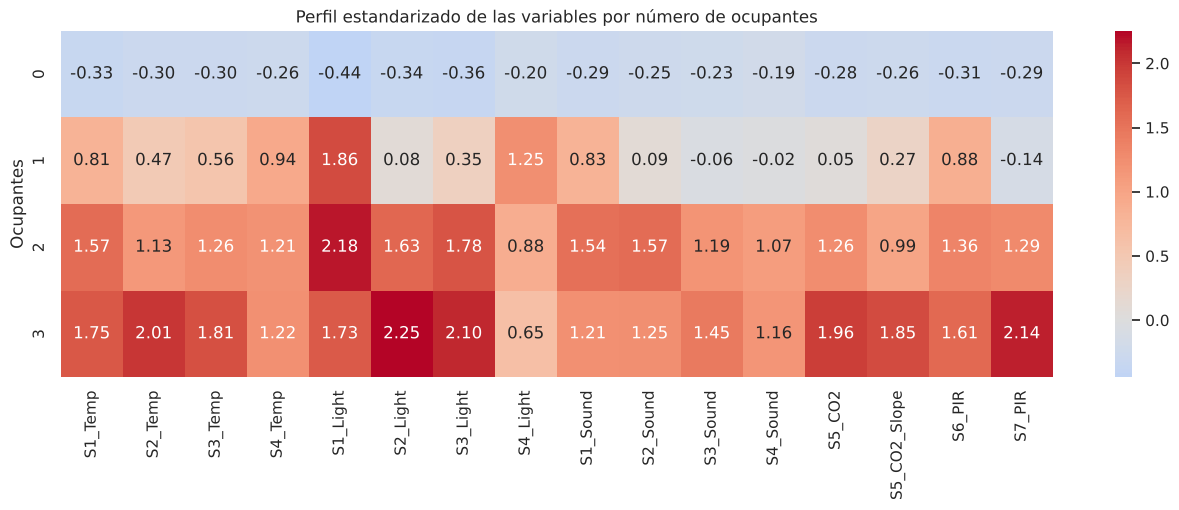

In [67]:
profile = standardized_profile(eda_df)
plt.figure(figsize=(16, 4.5))
sns.heatmap(profile, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Perfil estandarizado de las variables por número de ocupantes")
plt.xlabel("")
plt.ylabel("Ocupantes")
plt.show()

Cada celda indica cuántas desviaciones estándar se aleja la media de una clase de la media global. Con la sala vacía
todas las variables quedan ligeramente por debajo del promedio (entre −0.2 y −0.4); con 2 y 3 ocupantes la luz, el CO₂,
el sonido y los PIR se ubican entre 1 y 2.3 desviaciones por encima. La clase 1 tiene un perfil propio: luz alta en S1 y
S4 y actividad en el PIR S6, pero casi nada en S2, S3, S7 ni en el CO₂. Al ser además la clase menos frecuente, anticipo
que será la más difícil de distinguir de la clase 0.

## 9.6 Patrones temporales

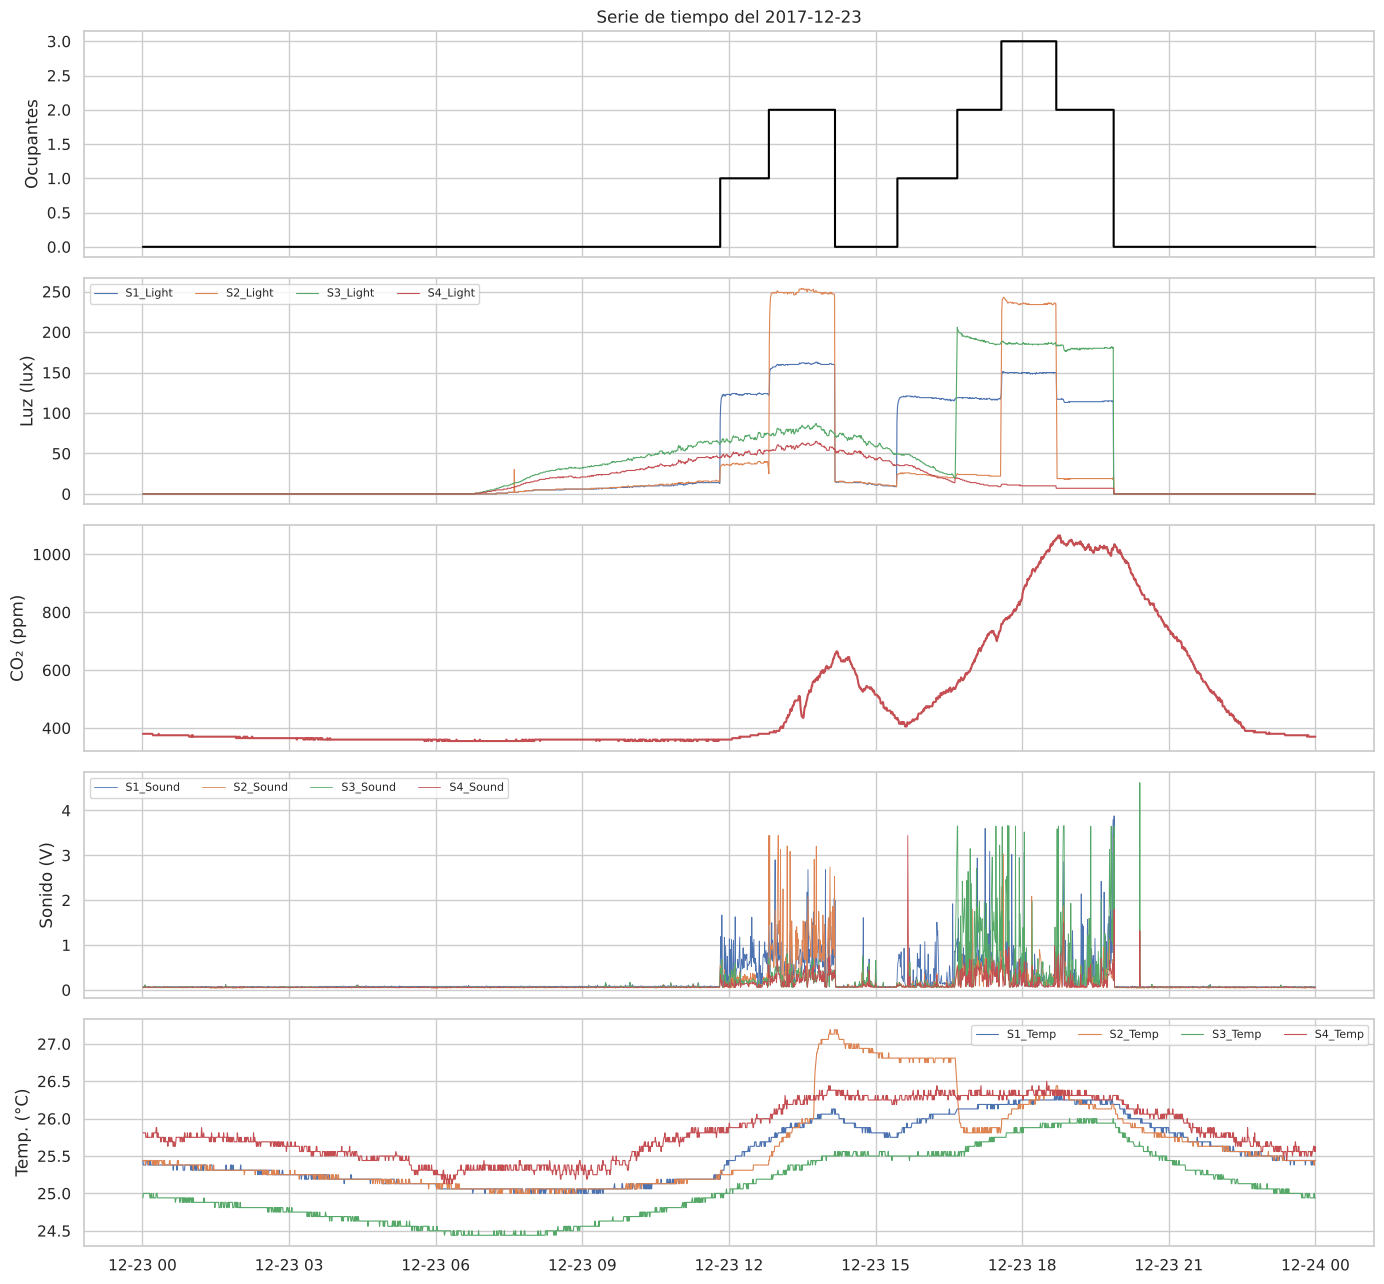

In [68]:
# Un día representativo: cómo responden los sensores a la ocupación a lo largo del día
day = eda_df["timestamp"].dt.date.value_counts().idxmax()
one_day = eda_df[eda_df["timestamp"].dt.date == day]

fig, axes = plt.subplots(5, 1, figsize=(14, 13), sharex=True)
axes[0].step(one_day["timestamp"], one_day[TARGET], where="post", color="black")
axes[0].set_ylabel("Ocupantes")
axes[0].set_title(f"Serie de tiempo del {day}")
for col in SENSOR_GROUPS["Luz"]:
    axes[1].plot(one_day["timestamp"], one_day[col], lw=0.8, label=col)
axes[1].set_ylabel("Luz (lux)")
axes[1].legend(ncol=4, fontsize=8)
axes[2].plot(one_day["timestamp"], one_day["S5_CO2"], color="#c44e52")
axes[2].set_ylabel("CO₂ (ppm)")
for col in SENSOR_GROUPS["Sonido"]:
    axes[3].plot(one_day["timestamp"], one_day[col], lw=0.6, label=col)
axes[3].set_ylabel("Sonido (V)")
axes[3].legend(ncol=4, fontsize=8)
for col in SENSOR_GROUPS["Temperatura"]:
    axes[4].plot(one_day["timestamp"], one_day[col], lw=0.8, label=col)
axes[4].set_ylabel("Temp. (°C)")
axes[4].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

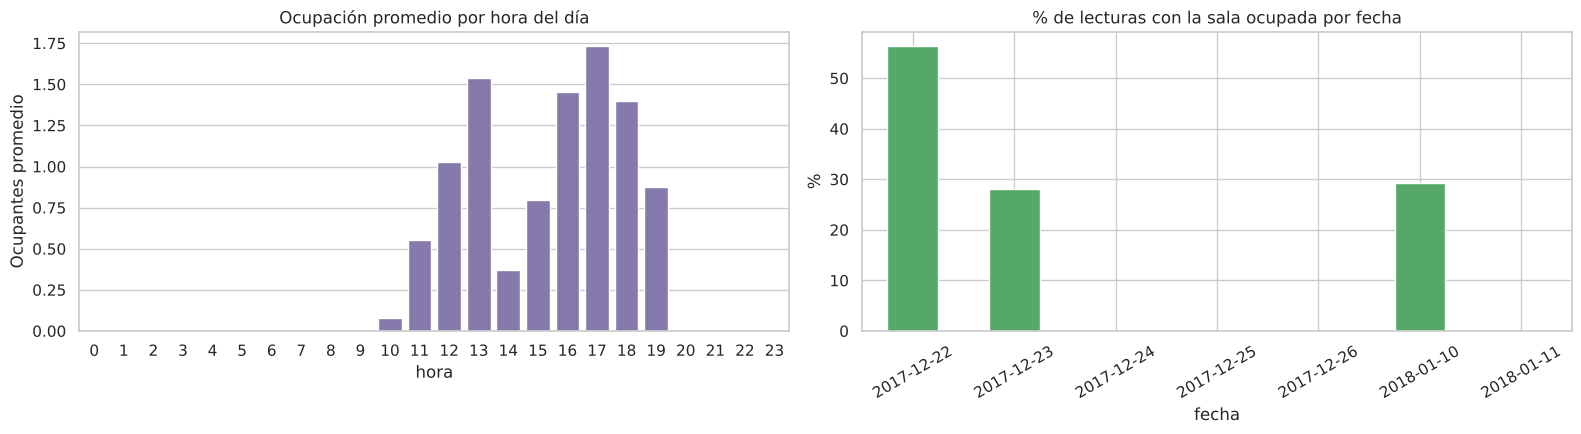

In [69]:
# Ocupación promedio por hora del día y por fecha
eda_df["hora"] = eda_df["timestamp"].dt.hour
eda_df["fecha"] = eda_df["timestamp"].dt.date.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.barplot(data=eda_df, x="hora", y=TARGET, ax=axes[0], color="#8172b3", errorbar=None)
axes[0].set_title("Ocupación promedio por hora del día")
axes[0].set_ylabel("Ocupantes promedio")
occupied_share = eda_df.groupby("fecha")[TARGET].apply(lambda s: 100 * (s > 0).mean())
occupied_share.plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("% de lecturas con la sala ocupada por fecha")
axes[1].set_ylabel("%")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

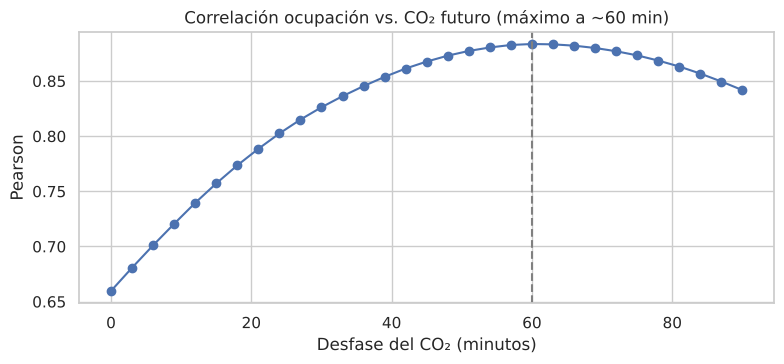

In [70]:
# El CO2 reacciona con retraso: correlación entre la ocupación y el CO2 desplazado k lecturas (~30 s cada una)
lags = range(0, 181, 6)      # de 0 a 90 minutos, cada 3 minutos
lag_corr = []
for k in lags:
    shifted = eda_df.groupby(base_df.loc[eda_df.index, "segment"].values)["S5_CO2"].shift(-k)
    lag_corr.append({"lag_min": k * 0.5, "corr": eda_df[TARGET].corr(shifted)})
lag_corr = pd.DataFrame(lag_corr)

plt.figure(figsize=(8, 3.8))
plt.plot(lag_corr["lag_min"], lag_corr["corr"], marker="o")
best = lag_corr.loc[lag_corr["corr"].idxmax()]
plt.axvline(best["lag_min"], ls="--", color="grey")
plt.title(f"Correlación ocupación vs. CO₂ futuro (máximo a ~{best['lag_min']:.0f} min)")
plt.xlabel("Desfase del CO₂ (minutos)")
plt.ylabel("Pearson")
plt.tight_layout()
plt.show()

**Lectura temporal.**

- La sala solo se ocupa entre las 10:00 y las 20:00, y únicamente en tres de los siete días registrados (22 y 23 de
  diciembre y 10 de enero). Las noches y los días sin actividad explican el gran peso de la clase 0.
- La luz responde de inmediato a la llegada de personas (es un escalón), mientras que el **CO₂ reacciona con retraso**:
  su correlación con la ocupación pasa de 0.66 en el mismo instante a cerca de 0.88 con el CO₂ medido una hora después,
  porque el gas se acumula mientras la gente permanece en la sala. Esto justifica crear variables de rezago o ventanas
  móviles en la etapa de *feature engineering*, y explica por qué el dataset incluye `S5_CO2_Slope`.
- La temperatura se comporta de forma parecida al CO₂: sube lentamente durante los periodos de ocupación.
- La serie también revela un factor de confusión: desde las 7:00 la **luz natural** eleva gradualmente S3 y S4 aunque la
  sala esté vacía. Por eso S4_Light es el sensor de luz menos correlacionado con la ocupación, y un modelo debería
  combinar la luz con la hora del día o con los PIR para no confundir el amanecer con la llegada de una persona.
- Al ser una serie de tiempo, la partición entrenamiento/prueba debe ser **temporal** (por días), no aleatoria: lecturas
  separadas por 30 s son casi idénticas y una partición aleatoria filtraría información entre conjuntos.

# 10. Conclusiones

**Qué encontraron las pruebas y cómo corregí cada problema**

| Problema (prueba) | Acción de limpieza | Alcance |
|---|---|---|
| T1 esquema | Eliminé la columna de ruido `mixed_type_col` | 1 columna |
| T2/T3 tipos y espacios | Quité espacios y convertí a número de forma explícita | 9,766 celdas (5 %) |
| T4/T5 marcadores y vacíos | Mapeé `?`, `NULL`, `N/A`, `error`, `invalid`, `NaN` (en cualquier combinación de mayúsculas) a faltante | 2,810 celdas |
| T6 marca de tiempo | Reconstruí 184 marcas (7 con la marca real de su copia) y eliminé 13 filas imposibles de ubicar | 197 filas |
| T7 rango de dominio | Valores imposibles (10 a 1000 veces la escala normal) → faltante | 994 celdas |
| T8 resolución del sensor | CO₂ fuera de la rejilla de 5 ppm → faltante | 37 celdas |
| T9 picos temporales | Hampel en temperatura, luz y CO₂; en sonido, solo picos sin corroboración de otro micrófono | 426 celdas |
| T10 objetivo | Eliminé las filas con ocupación faltante o imposible; nunca imputé una etiqueta | 208 filas |
| T11 duplicados | Fusioné las copias por marca de tiempo, recuperando 75 celdas que solo tenía la copia | 196 filas |
| T12 consistencia entre columnas | PIR activo con la sala vacía: rachas reales del sensor, conservadas y documentadas; temperatura coherente, convertida en aserción | 0 celdas |

**¿Qué estrategia reproduce mejor el original?** El tablero de 8.8 y la auditoría de 7.3 lo responden (valores de esta
ejecución, frente a las 10,129 filas del original):

| Estrategia | Filas | Variables equivalentes | KS p-value mín. | \|SMD\| máx. | \|Δcorr\| máx. | NMAE de imputación |
|---|---|---|---|---|---|---|
| A — eliminar | 6,889 (68 %) | 15/16 | 0.35 | 0.025 | 0.040 | — |
| B — mediana | 9,914 (98 %) | 16/16 | 0.34 | 0.020 | 0.040 | 0.54 |
| **C — interpolación** | **9,914 (98 %)** | 15/16 | **1.00** | **0.012** | 0.035 | **0.13** |
| D — KNN | 9,914 (98 %) | 15/16 | 1.00 | 0.011 | **0.028** | 0.16 |

- **La limpieza funcionó.** Con las cuatro estrategias, la distribución de la ocupación se conserva (chi-cuadrado
  p > 0.70), el ranking de las seis variables más correlacionadas con la ocupación es prácticamente el mismo del original y
  la mayor diferencia en cualquier correlación es menor a 0.04.
- **Selecciono la estrategia C (interpolación temporal).** Conserva el 98 % de las filas, tiene el menor error de
  imputación (cuatro veces menor que la mediana) y sus distribuciones son indistinguibles del original (KS p ≈ 1 en todas
  las variables). La única variable que sale del criterio, `S4_Sound` (razón de varianzas 1.13), lo hace igual en A, C y D:
  es el efecto de las pocas celdas de sonido corruptas que no logré detectar, no de la imputación.
- **El 16/16 de la mediana (B) es engañoso.** La mediana reduce la varianza de cada columna y eso compensa, por casualidad,
  la inflación que dejan los picos de sonido residuales. Su error de imputación es el peor, sus KS p-values son los más
  bajos y sesga hacia abajo las medias de las clases ocupadas, porque imputa siempre el estado de *sala vacía*.
- **Eliminar filas (A) es la opción más cara.** A diferencia del vino, aquí la corrupción toca casi un tercio de las
  filas: eliminarlas sacrifica 3,000 lecturas reales y rompe la continuidad de la serie de tiempo.
- **KNN (D) es la alternativa para producción en tiempo real.** La interpolación usa la lectura *siguiente*, que no existe
  cuando el modelo predice en vivo. Para ese escenario, D (o un *forward fill*) es la opción coherente, con un desempeño
  muy cercano a C.

**Hallazgos del EDA para la siguiente etapa**

1. El objetivo está muy desbalanceado (81 % sala vacía; 4.5 % un ocupante): usaré métricas como F1 macro o
   *balanced accuracy* y particiones estratificadas.
2. La luz (S1–S3) es el predictor más fuerte (r ≈ 0.79–0.85), seguido por la temperatura, los PIR y el CO₂.
3. Los "atípicos" de luz, sonido, PIR y CO₂ son la señal de ocupación: no se deben recortar.
4. Existe alta redundancia entre sensores del mismo tipo y entre temperatura y CO₂ (multicolinealidad).
5. El CO₂ responde con un retraso de hasta una hora: conviene crear variables de rezago y de ventana móvil.
6. La partición entrenamiento/prueba debe ser temporal, por días, para evitar fuga de información.

**Limitaciones**

1. **Errores no detectables.** Una celda corrupta que conserva un valor plausible y no deja huella temporal ni espacial
   es indistinguible de una lectura real. Quedaron 15 celdas así, casi todas de sonido. Junto con los picos de sonido que
   ninguna imputación puede anticipar, son las que llevan la razón de varianzas de `S4_Sound` a 1.13: al corregir solo
   10 celdas de esa columna la razón vuelve a 1.01.
2. **Falsos positivos de la corroboración.** La regla del sonido borró 34 lecturas legítimas, casi todas de S1, que luego
   se imputaron.
3. **Umbrales por juicio de dominio.** Los rangos del contrato y los umbrales del filtro de Hampel los fijé con
   criterios físicos; con datos de otra sala o de otros sensores habría que revisarlos.
4. **Supuestos de la imputación.** Todas las estrategias suponen que los faltantes son aleatorios (MCAR). Además, imputé el
   dataset completo y la interpolación usa la lectura siguiente; en modelado, el imputador se ajusta solo con
   entrenamiento y, en tiempo real, se usa D o un *forward fill*.
5. **La auditoría es un privilegio del ejercicio.** Medir recall y error de imputación solo fue posible porque existe el
   original; en producción, la única defensa es el contrato de datos y sus pruebas.

**Lecciones de MLOps**

1. **Primero pruebo, luego limpio.** Cada acción de este notebook se justifica con el resultado medido de una prueba.
2. **Escribo el contrato de datos** y valido la salida contra él de forma automática (Sección 6). Es la misma disciplina
   que echo de menos cuando integro información entre plataformas como SIIF Web, PIIP o SUIT: sin un contrato explícito,
   un cambio de formato se descubre cuando el reporte ya salió mal.
3. **Error ≠ atípico.** Las reglas de dominio eliminan valores imposibles; las reglas estadísticas (IQR) son diagnósticos.
4. **La naturaleza de los datos define la técnica.** En una serie de tiempo, la marca de tiempo es la llave para
   deduplicar, el vecino temporal es el mejor imputador y el contexto (otros sensores) permite separar el ruido de la señal.
5. **Nunca imputo el objetivo**, y en modelado ajusto los imputadores solo con el conjunto de entrenamiento.
6. **Registro cada ejecución** (`cleaning_log`) para que el resultado sea trazable. En un proyecto real, los CSV limpios se
   versionarían con DVC y la bitácora se registraría en MLflow junto con el experimento.